<a href="https://colab.research.google.com/github/fxrdhan/Practical-Statistics-for-Data-Scientists/blob/main/Chapter_02_Data_and_Sampling_Distributions/Chapter_02_Data_and_Sampling_Distributions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 2 — Data and Sampling Distributions

| | |
|---|---|
| **Book** | *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, 2nd edition — Peter Bruce, Andrew Bruce and Peter Gedeck (O'Reilly Media, 2020) |
| **Code reproduced here** | the Python code of the book's official repository, `gedeck/practical-statistics-for-data-scientists` (GNU General Public License v3) |
| **Versions used to run this notebook** | printed by the setup cell |
| **What this notebook contains** | a summary of every section of the chapter, the theory behind it, the book's Python code reproduced with an analysis of every output, and extra experiments written for this notebook |

## Chapter overview

Chapter 1 described the data in hand. Chapter 2 asks the question that comes next: **how far can a sample be trusted?** A data set is almost always a *sample* of a larger population, so every number computed from it, the mean, the median, a proportion, is itself a random quantity that would have come out differently with another sample. The chapter follows that idea step by step: how a sample is drawn and how it can be biased, how the values of a statistic vary from sample to sample (its **sampling distribution**), how that variation is measured without any formula (the **bootstrap**) and reported (**standard error**, **confidence interval**), and finally the **probability distributions** that statisticians use as models: the normal distribution and its long-tailed alternatives, Student's $t$, the binomial, the chi-square, the $F$, and the Poisson family with the exponential and Weibull distributions.

### Sections of this chapter

| # | Section of the book | Python code in the book | What this notebook adds |
|---|---|---|---|
| 1 | Random sampling and sample bias | a population and a sample (figure) | stratified against simple random sampling, a biased sample that does not improve with size, the identity that splits the error of a mean into data quality and data quantity |
| 2 | Selection bias | no code | regression to the mean, the vast search effect, a selection that creates a correlation |
| 3 | Sampling distribution of a statistic | the distribution of means of 5 and of 20 incomes | the $1/\sqrt{n}$ law, the central limit theorem step by step, the finite-population correction, the sampling distribution of other statistics |
| 4 | The bootstrap | the bootstrap of a median | the bootstrap by hand, how many resamples, the bootstrap against the true sampling distribution, a statistic for which the bootstrap fails |
| 5 | Confidence intervals | a bootstrap interval of 90% and 95% | the actual coverage of several intervals, width against sample size and level, the meaning of "90%", other bootstrap intervals |
| 6 | Normal distribution | a QQ-plot of normal data | the 68-95-99.7 rule, how a QQ-plot is built, how skewed and heavy-tailed data look in it |
| 7 | Long-tailed distributions | a QQ-plot of the stock NFLX | what the book's code computes from that column, kurtosis, the tails of stock changes, a mean that does not converge |
| 8 | Student's $t$-distribution | no code | quantiles against the normal, why the standardized mean has heavy tails, coverage of $z$ and $t$ intervals |
| 9 | Binomial distribution | the probability of 2 successes in 5 trials | the normal approximation, the shape for different $n$ and $p$, exact and approximate intervals for a proportion |
| 10 | Chi-square distribution | no code | the sum of squares of normal variables, the distribution of the sample variance, a goodness-of-fit test and the rule for small counts |
| 11 | $F$-distribution | no code | a ratio of variances, the link with $t$, the fragility of the variance-ratio test |
| 12 | Poisson and related distributions | Poisson, exponential and Weibull samples | the Poisson process, overdispersion, the rate of failures, the hazard of a Weibull distribution |

### How to read this notebook

Every section has the same structure:

1. **Summary** — what the book says, condensed in my own words (the book itself is not quoted).
2. **Theory** — the ideas behind it: definitions, math and the reasons that make a method behave as it does.
3. **Book code** — the official Python code of the chapter, reproduced and executed, followed by an **output analysis**.
4. **Extra** — experiments written for this notebook. They are *not* part of the book. They are lettered (a), (b), ... inside each section and cited with the section number, as in 3(b).

Every code cell starts with a label comment: `# BOOK CODE` for code of the official repository, `# EXTRA` for code written for this notebook. The book's code is reproduced as it is; where it needs a change to run in a notebook, the change is marked in the cell. Most of this chapter's code draws random numbers without a seed; the cells that do so start with a line `np.random.seed(...)  # NOT IN THE BOOK`, so that every run gives the same output. The extra experiments use their own random generators and never touch the global one.

---
## 0. Setup

The datasets of the book live in the official repository, in its `data` folder. The helper `ensure_data` below looks for each file in a folder called `data` next to the notebook and **downloads it from the official repository the first time** it is missing (this is the only use of the network; the folder is not part of this repository, see `.gitignore`). This chapter needs `loans_income.csv` (the annual income of 50,000 loan applicants), `sp500_data.csv.gz` (about 21 MB, daily stock data) and, for two extra experiments, `kc_tax.csv.gz` (the tax data of Chapter 1).

The setup cell also prints the versions of the libraries, because the code of the book was written for older ones, and sets a quiet plotting style (it is global, so it also applies to the figures of the book code).

In [1]:
# SETUP
import platform
import urllib.request
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn

print(f"Python       : {platform.python_version()}")
print(f"NumPy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"seaborn      : {sns.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# print warnings without the file path, so that the saved output does not depend on the machine
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"

# --- the datasets of the official repository ---------------------------------------------------------
DATA = Path("data")
DATA_URL = "https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/"


def ensure_data(*names):
    """Make sure that the files `names` exist in the folder `data`; download the missing ones."""
    DATA.mkdir(exist_ok=True)
    for name in names:
        if not (DATA / name).exists():
            urllib.request.urlretrieve(DATA_URL + name, DATA / name)
    return DATA


ensure_data("loans_income.csv", "sp500_data.csv.gz", "kc_tax.csv.gz")

# --- a quiet, colour-blind-safe style (global: it also applies to the figures of the book code) --------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua (checked for colour-vision deficiency)
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.labelsize": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_SOFT,
    "figure.dpi": 110, "font.size": 10,
})

Python       : 3.12.3
NumPy        : 2.5.4
pandas       : 3.1.0
SciPy        : 1.16.3
scikit-learn : 1.9.1
seaborn      : 0.13.2
Matplotlib   : 3.11.2


---
## 1. Random sampling and sample bias

*Book section: "Random Sampling and Sample Bias" (with "Bias", "Random Selection", "Size Versus Quality" and "Sample Mean Versus Population Mean"). The only code of the official script that belongs to it is the figure of a population and a sample at the start of the script.*

### Summary

* Statistics works with **samples**: a subset drawn from a larger **population**, in order to learn something about the population. A number computed from a sample (a mean, a median, a proportion) is a **statistic**; the corresponding number for the population is a **parameter**. The usual notation is $n$ for the size of the sample and $N$ for that of the population.
* A sample is **random** when every member of the population has a known chance of entering it, in the simplest case the same chance (a **simple random sample**). Sampling can be **with replacement**, where a member can be drawn again, or **without** it. In **stratified sampling** the population is first divided into groups (**strata**) and a random sample is drawn within each, which guarantees that every group is represented.
* **Bias** is a systematic error, one that points in the same direction however often the study is repeated. In sampling, **sample bias** means that the sample differs in a systematic way from the population it is meant to represent, for instance because the people who answer a survey are not typical. Bias must be told apart from random error, which averages out.
* Size does not repair quality. A large sample that was gathered in a biased way converges to the wrong value; a smaller random sample converges to the right one. More data help only when they are representative.
* The **sample mean** is a random quantity; the **population mean** is a fixed number that we want to estimate. How different they can be is the subject of the rest of the chapter.

### Theory

**Population, sample, parameter, statistic.** Take a finite population of $N$ units with values $y_1, \dots, y_N$; the parameter is, for example, the mean $\mu = \frac{1}{N}\sum_i y_i$. A sample is a subset $S$ of $n$ units, and a statistic such as $\bar{y} = \frac1n\sum_{i \in S} y_i$ depends on which subset was drawn. The **inclusion probability** $\pi_i = P(i \in S)$ describes the design. In a simple random sample without replacement every subset of size $n$ is equally likely and $\pi_i = n/N$ for all units. Sampling with replacement gives independent draws from the population distribution: this is the model behind most formulas of the chapter, and behind the bootstrap.

**Stratified sampling.** Split the population into $H$ strata of sizes $N_h$, with weights $W_h = N_h/N$, and draw $n_h$ units in each. The estimate of the mean is $\bar{y}_{st} = \sum_h W_h \bar{y}_h$, with variance
$$\operatorname{Var}(\bar{y}_{st}) = \sum_{h=1}^{H} W_h^2\left(1 - \frac{n_h}{N_h}\right)\frac{S_h^2}{n_h},$$
where $S_h^2$ is the variance of the values inside stratum $h$. With *proportional allocation* ($n_h = nW_h$) this becomes $\frac{1-f}{n}\sum_h W_h S_h^2$ with $f = n/N$: only the variation **inside** the strata counts. A simple random sample of the same size has variance $\frac{1-f}{n}S^2$, and $S^2$ is, approximately, the within-strata variance plus the variance **between** the strata means. Stratifying on a variable that is related to the outcome therefore removes the between-strata part of the variance (extra 1(a)).

**Bias, variance and mean squared error.** For an estimator $\hat\theta$ of a parameter $\theta$,
$$\mathrm{MSE}(\hat\theta) = E(\hat\theta - \theta)^2 = \underbrace{\bigl(E\hat\theta - \theta\bigr)^2}_{\text{bias}^2} + \underbrace{\operatorname{Var}(\hat\theta)}_{\text{random error}}.$$
For the mean of a random sample the variance is of order $1/n$ and goes to zero as the sample grows; a bias does not depend on $n$ at all. This is why size cannot repair quality.

**Sources of sample bias.** The sample is biased whenever the chance of entering it is related to the value that is measured: people with strong opinions are the ones who answer a voluntary poll (self-selection), the units that survive are the only ones observed (survivorship), a list of contacts leaves out part of the population (undercoverage). A well-known historical case is the 1936 presidential poll of the magazine *Literary Digest*: millions of replies, taken from lists of subscribers, car owners and telephone users, pointed at the wrong winner, while a far smaller but more representative poll got it right (Squire, 1988).

**Size versus quality: an exact identity.** Meng (2018) showed that the error of a sample mean has an exact decomposition. Let $R_i = 1$ if unit $i$ is in the sample and $0$ otherwise, let $\rho$ be the correlation over the population between $R_i$ and $y_i$, and $\sigma$ the standard deviation of $y$ over the population (divisor $N$). Then
$$\bar{y}_n - \mu = \rho \,\sqrt{\frac{N-n}{n}}\; \sigma .$$
The error is the product of a **data defect correlation** $\rho$ (quality: zero for a random sample on average, of size about $1/\sqrt{N}$), of $\sqrt{(N-n)/n}$ (quantity) and of the spread of the data $\sigma$ (difficulty of the problem). For a huge but biased sample $\rho$ is not small compared with $1/\sqrt{N}$ and the error stays large however big $n$ is (extra 1(b) checks the identity).

**The sample mean and the population mean.** For a random sample $E(\bar{y}) = \mu$: the sample mean is *unbiased*. Its distance from $\mu$ in a particular sample is its random error, whose size is measured by the standard error of section 3.

### Book code

The official script starts with the imports and paths used by the whole chapter, and with a figure that contrasts a population (the smooth curve, a normal distribution) with a sample drawn from it (a histogram of 1,000 values). The script already sets a seed for this figure.

In [2]:
# BOOK CODE (imports and paths of the official script; `DATA` comes from the setup cell of this notebook)
from pathlib import Path
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.utils import resample

import seaborn as sns
import matplotlib.pylab as plt

# Define paths to data sets. If you don't keep your data in the same directory as the code, adapt the path names.

LOANS_INCOME_CSV = DATA / 'loans_income.csv'
SP500_DATA_CSV = DATA / 'sp500_data.csv.gz'

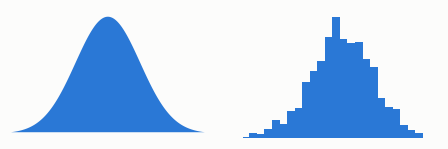

In [3]:
# BOOK CODE (Figure 2.1): a population and a sample drawn from it
np.random.seed(seed=1)
x = np.linspace(-3, 3, 300)
xsample = stats.norm.rvs(size=1000)

fig, axes = plt.subplots(ncols=2, figsize=(5, 1.5))

ax = axes[0]
ax.fill(x, stats.norm.pdf(x))
ax.set_axis_off()
ax.set_xlim(-3, 3)

ax = axes[1]
ax.hist(xsample, bins=30)
ax.set_axis_off()
ax.set_xlim(-3, 3)
ax.set_position
# plt.subplots_adjust(left=0, bottom=0, right=1, top=1, wspace=0, hspace=0)

plt.show()

**Output analysis.**

* The left panel is the **population**, here the standard normal density, a smooth curve; the right panel is a **sample** of 1,000 values drawn from it, a histogram with 30 bars. The sample has the same bell shape and the same centre, but its outline is ragged: the heights of the bars fluctuate around the curve, by chance, and the tails are thin because few values fall there.
* The point of the figure is the relation between the two: a sample resembles the population without being equal to it, and a different sample would give a slightly different histogram. The axes are switched off in the code on purpose, because the figure is a sketch of the idea and not a result.
* The first cell (imports and paths) prints nothing.

### Extra experiments

**(a) Stratified against simple random sampling.** The population is the filtered tax table of Chapter 1 (assessed value below 750,000 and area between 100 and 3,500 square feet, with a known ZIP code), about 409,000 houses in 111 ZIP codes. The aim is to estimate the mean assessed value from a sample of about 300 houses, either by a simple random sample or by a stratified one with the ZIP code as stratum and proportional allocation. 2,000 samples of each kind are drawn; the cell compares the spread of the estimates with the two variance formulas of the theory block.

In [4]:
# EXTRA (a): stratified (by ZIP code) against simple random sampling of the mean assessed value
kc_tax = pd.read_csv(DATA / "kc_tax.csv.gz")
houses = kc_tax.loc[(kc_tax.TaxAssessedValue < 750000) & (kc_tax.SqFtTotLiving > 100) & (kc_tax.SqFtTotLiving < 3500)].dropna(subset=["ZipCode"])
houses = houses.sort_values("ZipCode", kind="stable")
values, zips = houses["TaxAssessedValue"].to_numpy(float), houses["ZipCode"].to_numpy()
N = len(values)
labels, starts, sizes = np.unique(zips, return_index=True, return_counts=True)
weights = sizes / N
allocation = np.maximum(1, np.round(300 * weights).astype(int))  # proportional allocation, at least one unit per stratum
n = int(allocation.sum())

rng = np.random.default_rng(11)
repetitions = 2000
srs = np.array([values[rng.choice(N, n, replace=False)].mean() for _ in range(repetitions)])
stratified = np.array([sum(w * values[start + rng.choice(size, k, replace=False)].mean() for w, start, size, k in zip(weights, starts, sizes, allocation))
                       for _ in range(repetitions)])

f = n / N
theory_srs = np.sqrt((1 - f) * values.var(ddof=1) / n)
stratum_var = np.array([values[s:s + z].var(ddof=1) if z > 1 else 0.0 for s, z in zip(starts, sizes)])
theory_stratified = np.sqrt(np.sum(weights ** 2 * (1 - allocation / sizes) * stratum_var / allocation))
between = np.sum(weights * (np.array([values[s:s + z].mean() for s, z in zip(starts, sizes)]) - values.mean()) ** 2)
print(f"{N:,} houses in {len(labels)} ZIP codes; sample size {n}; population mean {values.mean():,.0f}")
print(f"share of the variance of the values that lies between the ZIP codes: {between / values.var():.1%}")
print(pd.DataFrame({"mean of the estimates": [srs.mean(), stratified.mean()], "sd of the estimates": [srs.std(ddof=1), stratified.std(ddof=1)],
                    "sd from the formula": [theory_srs, theory_stratified]}, index=["simple random", "stratified, proportional"]).round(0).to_string())
print(f"ratio of the variances (stratified / simple random): {stratified.var(ddof=1) / srs.var(ddof=1):.3f}")

409,456 houses in 111 ZIP codes; sample size 336; population mean 372,860
share of the variance of the values that lies between the ZIP codes: 55.3%
                          mean of the estimates  sd of the estimates  sd from the formula
simple random                          372888.0               8051.0               8063.0
stratified, proportional               372808.0               5763.0               5751.0
ratio of the variances (stratified / simple random): 0.512


**Analysis of extra (a).**

* **The population.** 409,456 houses in 111 ZIP codes, with a mean assessed value of 372,860 dollars. 55.3% of the variance of the values is *between* the ZIP codes, so the ZIP code is strongly related to the outcome.
* **The samples.** Proportional allocation with at least one house per stratum gives 336 houses, not 300, because every ZIP code gets at least one house and the numbers are rounded; the simple random sample has the same size.
* **Both estimates are unbiased.** The averages of the 2,000 estimates are 372,888 and 372,808, less than 0.02% from the true mean.
* **Stratifying removes the between-strata variance.** The standard deviation of the estimates is 8,051 for the simple random sample and 5,763 for the stratified one, and the formulas of the theory block (8,063 and 5,751) agree with the simulation to within 0.3%. The ratio of the variances is 0.512: the stratified estimate is as precise as a simple random sample of about 1.95 times the size, roughly 650 houses.
* The gain depends on the stratum variable being related to the outcome. Stratifying on a variable that has nothing to do with the value would leave the variance where it was.

**(b) A biased sample does not improve with its size.** The population is the 50,000 incomes of the book's data set. The biased sample is drawn so that the chance of entering is proportional to the income (an extreme but instructive case of self-selection: the better paid answer more often), the other sample is a simple random sample. For sizes from 50 to 20,000, 300 samples of each kind are drawn without replacement. The cell reports bias, standard deviation and root mean squared error of the sample mean, compares the bias with the theoretical value $E(Y^2)/E(Y)$ of a sample whose chance is proportional to the value, and checks Meng's identity on one of the samples.

population: N = 50,000, mean 68,761, sd 32,872; size-biased mean E(Y^2)/E(Y) = 84,475 (bias 15,715)
    n  srs: bias  srs: sd  srs: rmse  biased: bias  biased: sd  biased: rmse
   50      179.0   4700.0     4695.0       15650.0      5221.0       16495.0
  200      -72.0   2204.0     2201.0       15541.0      2557.0       15749.0
 1000       38.0   1001.0     1000.0       15580.0      1273.0       15632.0
 5000      -15.0    436.0      435.0       14649.0       482.0       14657.0
20000        6.0    182.0      182.0       11178.0       162.0       11179.0

Meng's identity (one biased sample, n = 1000): error of the mean 15,853.3; rho * sqrt((N - n) / n) * sigma = 15,853.3 with rho = 0.0689
for a random sample rho is about 1/sqrt(N) = 0.0045 in size


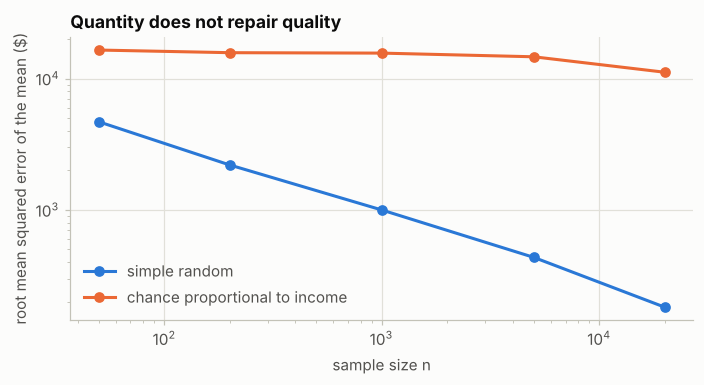

In [5]:
# EXTRA (b): the error of a biased sample does not shrink with n
income = pd.read_csv(LOANS_INCOME_CSV).squeeze("columns").to_numpy(float)
N, mu, sigma = len(income), income.mean(), income.std()          # sigma with divisor N, as in the identity
sizes = [50, 200, 1000, 5000, 20000]
rng = np.random.default_rng(5)
repetitions = 300
errors = {"simple random": {n: [] for n in sizes}, "chance proportional to income": {n: [] for n in sizes}}
for _ in range(repetitions):
    random_order = rng.permutation(N)
    keys = np.log(rng.random(N)) / income                        # Efraimidis-Spirakis keys: the largest keys form a weighted sample
    biased_order = np.argsort(-keys)
    for n in sizes:
        errors["simple random"][n].append(income[random_order[:n]].mean() - mu)
        errors["chance proportional to income"][n].append(income[biased_order[:n]].mean() - mu)

rows = []
for n in sizes:
    row = {"n": n}
    for name, short in (("simple random", "srs"), ("chance proportional to income", "biased")):
        e = np.array(errors[name][n])
        row |= {f"{short}: bias": e.mean(), f"{short}: sd": e.std(ddof=1), f"{short}: rmse": np.sqrt(np.mean(e ** 2))}
    rows.append(row)
print(f"population: N = {N:,}, mean {mu:,.0f}, sd {sigma:,.0f}; size-biased mean E(Y^2)/E(Y) = {np.mean(income ** 2) / mu:,.0f} (bias {np.mean(income ** 2) / mu - mu:,.0f})")
print(pd.DataFrame(rows).round(0).astype({"n": int}).to_string(index=False))

# Meng's identity on one biased sample of 1,000 units
n = 1000
selected = np.zeros(N)
selected[np.argsort(-(np.log(rng.random(N)) / income))[:n]] = 1
rho = np.corrcoef(selected, income)[0, 1]
print(f"\nMeng's identity (one biased sample, n = {n}): error of the mean {income[selected == 1].mean() - mu:,.1f}; "
      f"rho * sqrt((N - n) / n) * sigma = {rho * np.sqrt((N - n) / n) * sigma:,.1f} with rho = {rho:.4f}")
print(f"for a random sample rho is about 1/sqrt(N) = {1 / np.sqrt(N):.4f} in size")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for (label, short), color in zip((("simple random", "srs"), ("chance proportional to income", "biased")), PALETTE[:2]):
    ax.plot(sizes, [r[f"{short}: rmse"] for r in rows], marker="o", color=color, label=label)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("sample size n"); ax.set_ylabel("root mean squared error of the mean ($)")
ax.set_title("Quantity does not repair quality")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis of extra (b).**

* **The random sample.** Its bias is close to zero at every size (between $-72$ and 179 dollars, within the simulation error) and its error falls with the size, from a root mean squared error of 4,695 dollars for $n = 50$ to 182 for $n = 20{,}000$: a factor of about 2 for each factor of 4 to 5 in $n$, as $1/\sqrt{n}$ says.
* **The biased sample.** Its bias is about 15,600 dollars, 23% of the mean income, for $n$ from 50 to 1,000, in line with the theoretical value $E(Y^2)/E(Y) - \mu = 15{,}715$. Its error is dominated by the bias: the root mean squared error is 16,495 for $n = 50$, 15,632 for $n = 1{,}000$ and 14,657 for $n = 5{,}000$. It begins to fall only when the sample is a large share of the population ($n = 20{,}000$ is 40% of it, error 11,179), because a sample that takes in a large part of the population cannot be far from it.
* **Quality against quantity.** A random sample of 50 incomes (error 4,695) is more accurate than a biased sample of 20,000 (error 11,179), and a biased sample of 1,000 is 16 times worse than a random sample of 1,000 (15,632 against 1,000).
* **Meng's identity holds exactly.** For one biased sample of 1,000 the error of the mean is 15,853.3 and $\rho\sqrt{(N-n)/n}\,\sigma$ is 15,853.3, with a data defect correlation $\rho = 0.0689$. This is small as a correlation, but a random sample has $|\rho|$ of order $1/\sqrt{N} = 0.0045$, 15 times less; the factor $\sqrt{(N-n)/n} = 6.9$ and the standard deviation 32,872 turn it into an error of 15,853 dollars.
* The figure shows the two curves on logarithmic axes: the random sample follows a straight line with slope $-1/2$, the biased one is flat.

---
## 2. Selection bias

*Book section: "Selection Bias" (with "Regression to the Mean"). The section has no code.*

### Summary

* **Selection bias** is the bias that comes from *how observations are chosen*: not only the choice of units to sample, but also which data are kept, which variables are used and which results are reported. The classic forms are **data snooping** (looking through the data until something interesting turns up) and the **vast search effect**: if enough variables, models or subgroups are examined, something will look significant by chance.
* The remedy is to state a hypothesis *before* looking, to set aside **holdout data** on which the finding is checked, and to correct for the number of comparisons. A finding that was selected as the best of many has to be re-tested on data that played no part in its selection.
* **Regression to the mean**: when a measurement is partly luck, units that were selected because their first measurement was extreme tend to be less extreme the second time. This happens without any cause other than the selection itself, and it is easily mistaken for the effect of an intervention.

### Theory

**Multiple comparisons.** If $m$ independent hypotheses that are all false findings are each tested at level $\alpha$, the chance of at least one "significant" result is $1 - (1-\alpha)^m$: 5% for $m = 1$, 40% for $m = 10$, 99.4% for $m = 100$. The Bonferroni correction tests each at $\alpha/m$ to keep the chance of any false positive at most $\alpha$. When many predictors are tried, the *largest* of $m$ correlations is a different variable from the correlation of a single, pre-specified predictor: its distribution is shifted far from zero, and the shift grows with $m$. A correlation that was selected for being large will almost certainly shrink on new data (the **winner's curse**).

**Regression to the mean.** Suppose that an observed value is a stable component plus independent luck, $X_1 = T + \varepsilon_1$ and $X_2 = T + \varepsilon_2$, with $T$ having variance $\sigma_T^2$ and the errors variance $\sigma_\varepsilon^2$. The correlation of two measurements is the **reliability** $\rho = \sigma_T^2/(\sigma_T^2 + \sigma_\varepsilon^2)$, and for jointly normal variables
$$E(X_2 \mid X_1 = x) = \mu + \rho\,(x - \mu), \qquad 0 < \rho < 1 .$$
An extreme first value is followed, on average, by a value that is closer to the mean by the factor $1-\rho$: the less reliable the measurement, the stronger the regression. It is a property of the selection, not a change in the units. Galton (1886) first described it, as regression towards mediocrity, in the heights of parents and their children.

**Selection can create a correlation.** If two independent variables $A$ and $B$ both contribute to being selected (an admission based on the sum of two scores), then among the selected units $A$ and $B$ are negatively related: one that is low must be compensated by the other. The effect is known as *Berkson's paradox* (Berkson, 1946, who found it in hospital data) or as conditioning on a collider; it is one more way in which a selected sample misleads (extra 2(c)).

### Extra experiments

This section has no code in the book. The experiments below make its three statements measurable.

**(a) Regression to the mean.** 100,000 players have a true skill $T \sim N(0,1)$. In each of two seasons the score is the skill plus independent luck, $X = T + \varepsilon$, with the luck having a standard deviation of 0.25, 0.5, 1 or 2 (reliability 0.94, 0.80, 0.50, 0.20). The cell selects the top 10% of the first season and looks at the same players in the second, and does the same for the bottom 10%.

 sd of the luck  reliability  corr(season1, season2)  top 10%: season 1  top 10%: season 2  predicted season 2  bottom 10%: season 1  bottom 10%: season 2
           0.25        0.941                   0.941              1.801              1.696               1.695                -1.807                -1.705
           0.50        0.800                   0.800              1.957              1.564               1.565                -1.966                -1.568
           1.00        0.500                   0.499              2.464              1.231               1.232                -2.484                -1.246
           2.00        0.200                   0.195              3.915              0.765               0.783                -3.906                -0.801


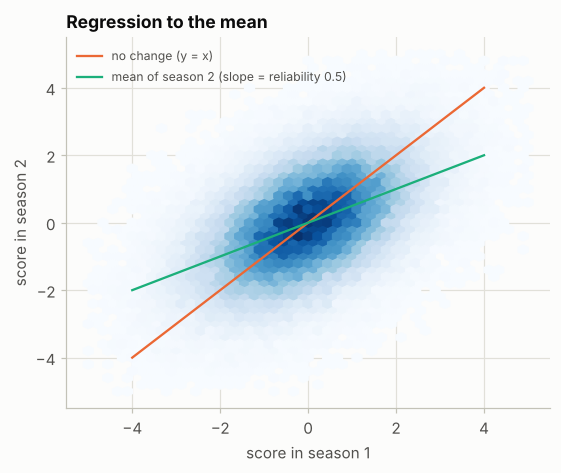

In [6]:
# EXTRA (a): regression to the mean for players selected on an extreme first measurement
rng = np.random.default_rng(21)
players = 100_000
skill = rng.normal(size=players)
rows = []
for luck in (0.25, 0.5, 1.0, 2.0):
    season1, season2 = skill + luck * rng.normal(size=players), skill + luck * rng.normal(size=players)
    reliability = 1 / (1 + luck ** 2)
    top, bottom = season1 >= np.quantile(season1, 0.9), season1 <= np.quantile(season1, 0.1)
    mean_all = season1.mean()
    rows.append({"sd of the luck": luck, "reliability": reliability, "corr(season1, season2)": np.corrcoef(season1, season2)[0, 1],
                 "top 10%: season 1": season1[top].mean(), "top 10%: season 2": season2[top].mean(), "predicted season 2": reliability * season1[top].mean(),
                 "bottom 10%: season 1": season1[bottom].mean(), "bottom 10%: season 2": season2[bottom].mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(5.2, 4.4))
season1, season2 = skill + rng.normal(size=players), skill + rng.normal(size=players)
ax.hexbin(season1, season2, gridsize=45, cmap="Blues", mincnt=1, extent=(-5, 5, -5, 5))
line = np.array([-4, 4])
ax.plot(line, line, color=PALETTE[1], lw=1.5, label="no change (y = x)")
ax.plot(line, 0.5 * line, color=PALETTE[2], lw=1.5, label="mean of season 2 (slope = reliability 0.5)")
ax.set_xlabel("score in season 1"); ax.set_ylabel("score in season 2")
ax.set_title("Regression to the mean")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**Analysis of extra (a).**

* With a reliability of 0.5 (luck as large as skill), the top 10% of the first season have a mean score of 2.46 and score 1.23 in the second season, half as much, as the formula $\rho \times 2.46 = 1.23$ predicts; the bottom 10% move from $-2.48$ to $-1.25$. With a reliability of 0.94 the top group falls only from 1.80 to 1.70, and with a reliability of 0.2 it falls from 3.92 to 0.77 (predicted 0.78).
* The correlation between the two seasons is the reliability (0.941, 0.800, 0.499, 0.195), and the share of the first-season advantage that is kept is the same number.
* Nothing has changed for these players: the second season is a new draw of luck. Whoever treats the top group (with a bonus, with coaching) and then looks at the second season would credit the intervention with a decline that happens anyway, and the bottom group would appear to improve by itself.
* The figure shows why: given a first score, the average second score lies on a line with the slope of the reliability, flatter than the line of no change.

**(b) The vast search effect.** An outcome of 40 observations is generated at random, and $m$ candidate predictors, also random and unrelated to it, are examined: $m = 1, 10, 100, 1000$. For each $m$ the cell records the largest absolute correlation, how often at least one correlation is "significant" at the 5% level, and what the best predictor does on a second set of 40 observations (its **holdout** check). 400 repetitions are run for each $m$.

In [7]:
# EXTRA (b): the best of m useless predictors looks good on the data it was chosen on, and not on new data
rng = np.random.default_rng(8)
n_obs, repetitions = 40, 400
t_critical = stats.t.ppf(0.975, n_obs - 2)
r_critical = t_critical / np.sqrt(n_obs - 2 + t_critical ** 2)


def correlations(y, X):
    """Correlation of the vector y with every column of X (the rows are observations)."""
    y, X = y - y.mean(), X - X.mean(axis=0)
    return (y @ X) / np.sqrt((y @ y) * (X ** 2).sum(axis=0))


rows = []
for m in (1, 10, 100, 1000):
    best_r, hit, holdout = [], [], []
    for _ in range(repetitions):
        y, X = rng.normal(size=n_obs), rng.normal(size=(n_obs, m))
        r = correlations(y, X)
        winner = np.argmax(np.abs(r))
        best_r.append(abs(r[winner]))
        hit.append(abs(r[winner]) > r_critical)
        y2, x2 = rng.normal(size=n_obs), rng.normal(size=n_obs)   # new data, for which the predictor is still useless
        holdout.append(abs(np.corrcoef(x2, y2)[0, 1]))
    rows.append({"predictors m": m, "mean of the largest |r|": np.mean(best_r), "share with a significant |r|": np.mean(hit),
                 "1 - 0.95^m": 1 - 0.95 ** m, "|r| of the winner on new data": np.mean(holdout)})
print(f"with {n_obs} observations an |r| above {r_critical:.3f} is 'significant' at the 5% level for one pre-specified predictor")
print(pd.DataFrame(rows).round(3).to_string(index=False))

with 40 observations an |r| above 0.312 is 'significant' at the 5% level for one pre-specified predictor
 predictors m  mean of the largest |r|  share with a significant |r|  1 - 0.95^m  |r| of the winner on new data
            1                    0.128                         0.042       0.050                          0.130
           10                    0.296                         0.388       0.401                          0.130
          100                    0.426                         0.998       0.994                          0.128
         1000                    0.517                         1.000       1.000                          0.128


**Analysis of extra (b).**

* With 40 observations an $|r|$ above 0.312 is significant at the 5% level for a *single* predictor, and 4.2% of the single useless predictors are (nominal 5%, the simulation error is about 1%).
* Among 10 useless predictors the best is "significant" in 38.8% of the repetitions (theory $1 - 0.95^{10} = 40.1\%$), among 100 in 99.8% (99.4%), among 1,000 always. The mean of the largest $|r|$ rises from 0.128 for one predictor to 0.296, 0.426 and 0.517; a correlation of 0.52 corresponds to about 27% of the variance "explained".
* On new data the selected predictor is as useless as before: its mean $|r|$ is 0.13 whatever $m$ was, the value that two unrelated variables give for 40 observations ($\sqrt{2/\pi}/\sqrt{40} = 0.126$).
* What went wrong was not the correlation formula but the selection of the best of many: the finding is real on the data that chose it and absent on a holdout.

**(c) A selection that creates a correlation.** Two scores are independent standard normal variables, for example a test and an interview. Candidates are admitted if their sum exceeds a threshold. The cell reports the correlation among the admitted for several admission rates and draws the case of 10%.

 share admitted  admitted  corr(test, interview) among the admitted
           1.00    200000                                     0.002
           0.50    100000                                    -0.467
           0.20     40000                                    -0.639
           0.10     20000                                    -0.706
           0.02      4000                                    -0.797


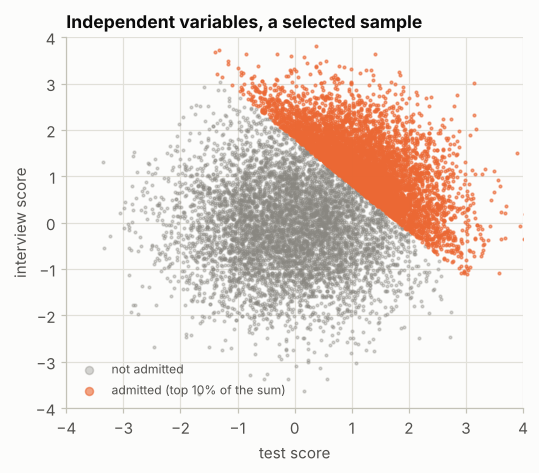

In [8]:
# EXTRA (c): selecting on the sum of two independent variables makes them negatively correlated
rng = np.random.default_rng(3)
a, b = rng.normal(size=200_000), rng.normal(size=200_000)
total = a + b
rows = []
for share in (1.0, 0.5, 0.2, 0.1, 0.02):
    admitted = total >= np.quantile(total, 1 - share)
    rows.append({"share admitted": share, "admitted": int(admitted.sum()), "corr(test, interview) among the admitted": np.corrcoef(a[admitted], b[admitted])[0, 1]})
print(pd.DataFrame(rows).round(3).to_string(index=False))

admitted = total >= np.quantile(total, 0.9)
fig, ax = plt.subplots(figsize=(5, 4.4))
ax.scatter(a[~admitted][:6000], b[~admitted][:6000], s=3, color=MUTED, alpha=0.35, label="not admitted")
ax.scatter(a[admitted][:6000], b[admitted][:6000], s=3, color=PALETTE[1], alpha=0.6, label="admitted (top 10% of the sum)")
ax.set_xlabel("test score"); ax.set_ylabel("interview score"); ax.set_xlim(-4, 4); ax.set_ylim(-4, 4)
ax.set_title("Independent variables, a selected sample")
ax.legend(loc="lower left", fontsize=8, markerscale=3)
plt.tight_layout()
plt.show()

**Analysis of extra (c).**

* Among all 200,000 candidates the scores are uncorrelated (0.002). Among those admitted the correlation is $-0.467$ for the top half, $-0.639$ for the top 20%, $-0.706$ for the top 10% and $-0.797$ for the top 2%: the more selective the admission, the stronger the negative relation.
* The figure shows the cause: the admitted candidates lie above the line "test + interview = threshold", a band that slopes downward, and within the band a low test score must be accompanied by a high interview score.
* An analysis of the admitted candidates alone would find that the two scores are negatively related and might conclude that they measure opposite qualities. The relation is created by the selection and does not exist in the applicants.

---
## 3. Sampling distribution of a statistic

*Book section: "Sampling Distribution of a Statistic" (with "Central Limit Theorem" and "Standard Error"). The code of the script draws many samples of loan incomes and compares the data with means of 5 and of 20 values.*

### Summary

* A **statistic** computed from a sample (a mean, a median, a proportion) changes from sample to sample. Its **sampling distribution** is the distribution of its values over many samples drawn from the same population. It must not be confused with the **data distribution**, the distribution of the individual values in one sample.
* The sampling distribution of a statistic such as the mean is **narrower** than the data distribution, and, for samples that are not tiny, much closer to a bell shape, even when the data are skewed. The statement behind this is the **central limit theorem**: the distribution of the mean of a large enough random sample is approximately normal, whatever the shape of the data. It is the reason why the classical formulas for intervals and tests work well in practice.
* The spread of a sampling distribution is its **standard error**. For the mean it is estimated by the standard deviation of the sample divided by the square root of the sample size, which means that to halve the standard error four times as much data are needed. The standard error is *not* the standard deviation of the data.
* In practice only one sample is available, so its sampling distribution has to be derived: by the formula where one exists, or by the bootstrap of the next section.
* The example of the script: the data distribution of the loan incomes is skewed to the right; the means of 5 incomes are less skewed and narrower; the means of 20 are narrower still and nearly bell-shaped.

### Theory

**The mean and variance of the sample mean.** Let $X_1, \dots, X_n$ be independent draws with mean $\mu$ and variance $\sigma^2$. Then $E(\bar X) = \mu$ and $\operatorname{Var}(\bar X) = \sigma^2/n$, so the standard error is
$$\operatorname{SE}(\bar X) = \frac{\sigma}{\sqrt{n}}, \qquad \widehat{\operatorname{SE}} = \frac{s}{\sqrt{n}} .$$
This needs no assumption about the shape of the data, only independence and a finite variance. The **square-root law** follows: precision grows with $\sqrt{n}$, not with $n$.

**Central limit theorem.** For independent draws with finite variance, $\sqrt{n}\,(\bar X - \mu)/\sigma$ converges in distribution to the standard normal distribution as $n \to \infty$. The *speed* of the convergence depends on the shape of the data: the skewness of $\bar X$ is $\gamma/\sqrt{n}$, where $\gamma$ is the skewness of the data, and its excess kurtosis is $\kappa/n$. A strongly skewed variable needs a larger $n$ than a symmetric one, which is why "$n \ge 30$" is only a rule of thumb. For data with infinite variance the theorem does not apply (section 7).

**Sampling without replacement from a finite population.** If $n$ units are drawn without replacement from $N$, the draws are slightly negatively dependent and
$$\operatorname{Var}(\bar X) = \frac{\sigma^2}{n}\cdot\frac{N-n}{N-1},$$
with $\sigma^2$ the population variance (divisor $N$). The factor $(N-n)/(N-1)$ is the **finite-population correction**: it is almost 1 when the sample is a small part of the population, and 0 when the sample is the whole population. What counts for the precision is the size of the sample, not its share of the population, until that share becomes large.

**Other statistics.** Every statistic has a sampling distribution, with its own standard error and shape. For the median of a continuous distribution with density $f$ and median $m$, the asymptotic standard error is $1/(2 f(m)\sqrt{n})$, which for normal data is $\sqrt{\pi/2}\,\sigma/\sqrt{n}$, about 25% larger than that of the mean. For many statistics (a trimmed mean, a ratio, a correlation) there is no simple formula, and the bootstrap is the practical tool.

### Book code

The script draws 1,000 incomes, 1,000 means of 5 incomes and 1,000 means of 20 incomes from the data set of 50,000 loan incomes, and draws the three histograms one above the other. The script does not set a seed for this cell; the cell below adds one.

        income  type
16441  34000.0  Data
26819  58000.0  Data
9242   68000.0  Data
16234  74000.0  Data
19184  42000.0  Data


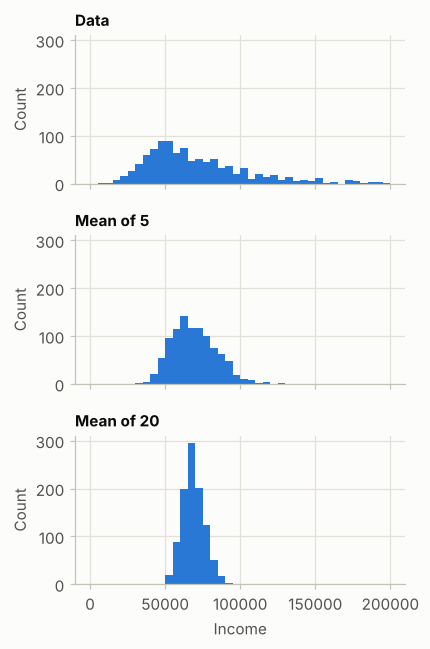

In [9]:
# BOOK CODE (Sampling Distribution of a Statistic): the data, the means of 5 and the means of 20
np.random.seed(2024)  # NOT IN THE BOOK: the book's sampling has no seed

loans_income = pd.read_csv(LOANS_INCOME_CSV).squeeze('columns')

sample_data = pd.DataFrame({
    'income': loans_income.sample(1000),
    'type': 'Data',
})

sample_mean_05 = pd.DataFrame({
    'income': [loans_income.sample(5).mean() for _ in range(1000)],
    'type': 'Mean of 5',
})

sample_mean_20 = pd.DataFrame({
    'income': [loans_income.sample(20).mean() for _ in range(1000)],
    'type': 'Mean of 20',
})

results = pd.concat([sample_data, sample_mean_05, sample_mean_20])
print(results.head())

g = sns.FacetGrid(results, col='type', col_wrap=1,
                  height=2, aspect=2)
g.map(plt.hist, 'income', range=[0, 200000], bins=40)
g.set_axis_labels('Income', 'Count')
g.set_titles('{col_name}')

plt.tight_layout()
plt.show()

**Output analysis.**

* The first lines of `results` show the structure: the column `income` and the column `type`; the index is the position of the sampled row in the full table (the three kinds of values are stacked, so the index repeats).
* The three histograms share the horizontal axis (0 to 200,000 dollars), so the narrowing is visible. The **data** are right-skewed: a mode at about 50,000 dollars and a tail that reaches 200,000. The **means of 5** are mostly between 40,000 and 100,000, around the population mean (68,761), with a short right tail to about 130,000. The **means of 20** are mostly between 50,000 and 95,000 and look close to symmetric.
* The three distributions have the same centre and decreasing spread: the sample statistic is more precise than a single value, and it becomes more normal as the sample size grows.

### Extra experiments

**(a) The standard error shrinks as $1/\sqrt{n}$.** For samples of size $n = 1$ to 2,000 drawn with replacement from the 50,000 incomes, the cell draws 5,000 samples and compares the standard deviation of their means with $\sigma/\sqrt{n}$, and estimates the exponent of $n$ by a straight-line fit on the logarithmic scale.

population standard deviation sigma = 32,872
   n  sd of the means  sigma / sqrt(n)  ratio
   1        33063.607        32871.707  1.006
   2        23625.198        23243.807  1.016
   5        14691.746        14700.674  0.999
  10        10442.108        10394.946  1.005
  20         7334.587         7350.337  0.998
  50         4586.391         4648.761  0.987
 100         3309.042         3287.171  1.007
 500         1474.633         1470.067  1.003
2000          732.266          735.034  0.996
slope of log(sd of the means) against log(n): -0.501 (the theory says -0.5)


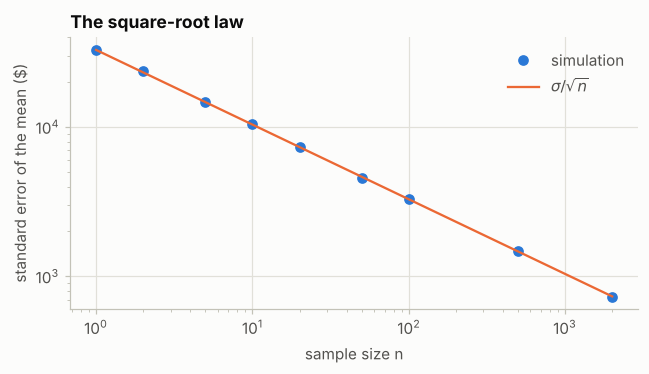

In [10]:
# EXTRA (a): the standard deviation of the sample mean against sigma / sqrt(n)
income = loans_income.to_numpy(float)
sigma = income.std()                       # population standard deviation
rng = np.random.default_rng(1)
sizes = [1, 2, 5, 10, 20, 50, 100, 500, 2000]
rows = []
for n in sizes:
    means = rng.choice(income, size=(5000, n)).mean(axis=1)
    rows.append({"n": n, "sd of the means": means.std(ddof=1), "sigma / sqrt(n)": sigma / np.sqrt(n)})
table = pd.DataFrame(rows)
table["ratio"] = table["sd of the means"] / table["sigma / sqrt(n)"]
print(f"population standard deviation sigma = {sigma:,.0f}")
print(table.round(3).to_string(index=False))
slope = np.polyfit(np.log(table["n"]), np.log(table["sd of the means"]), 1)[0]
print(f"slope of log(sd of the means) against log(n): {slope:.3f} (the theory says -0.5)")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(table["n"], table["sd of the means"], "o", color=PALETTE[0], label="simulation")
ax.plot(table["n"], table["sigma / sqrt(n)"], color=PALETTE[1], lw=1.5, label=r"$\sigma / \sqrt{n}$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("sample size n"); ax.set_ylabel("standard error of the mean ($)")
ax.set_title("The square-root law")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis of extra (a).**

* For every $n$ the standard deviation of the means is within 1.6% of $\sigma/\sqrt{n}$ (ratios 0.987 to 1.016). A standard deviation estimated from 5,000 repetitions has a simulation error of about 1%, which explains the deviations. For $n = 1$ the "mean" is a single income and its standard deviation is that of the data, 33,064 against $\sigma = 32{,}872$.
* The slope on the logarithmic scale is $-0.501$, the exponent $-1/2$ of the theory. In numbers: the standard error is 3,309 for 100 incomes, 1,475 for 500 and 732 for 2,000, so 4 times as many incomes halve it (1,475 to 732) and 20 times as many bring it down by a factor of 4.5.
* The standard error describes the precision of the *mean*, which is much better than that of a single value: with 100 incomes it is one tenth of the standard deviation of the data.

**(b) The central limit theorem step by step.** For samples of size $n = 1$ to 500, the cell draws 20,000 means and measures how far their distribution is from the normal one: the skewness (theory: $\gamma/\sqrt{n}$), the excess kurtosis (theory: $\kappa/n$), the maximum distance between their distribution function and the normal one (Kolmogorov-Smirnov distance), and the share of the standardized means that fall below $-1.96$ and above $+1.96$, which is 2.5% each under normality. The figure shows the standardized means for four sizes.

the incomes: skewness 1.049, excess kurtosis 1.081
  n  skewness  gamma / sqrt(n)  excess kurtosis  kappa / n  KS distance  share below -1.96  share above 1.96
  1     1.049            1.049            1.078      1.081        0.094              0.000             0.050
  2     0.738            0.742            0.523      0.540        0.060              0.002             0.046
  5     0.454            0.469            0.166      0.216        0.035              0.008             0.036
 10     0.358            0.332            0.084      0.108        0.032              0.012             0.033
 20     0.229            0.235            0.111      0.054        0.012              0.018             0.032
 50     0.155            0.148            0.067      0.022        0.016              0.021             0.028
100     0.106            0.105            0.023      0.011        0.005              0.022             0.027
500     0.039            0.047            0.004      0.002        0.006      

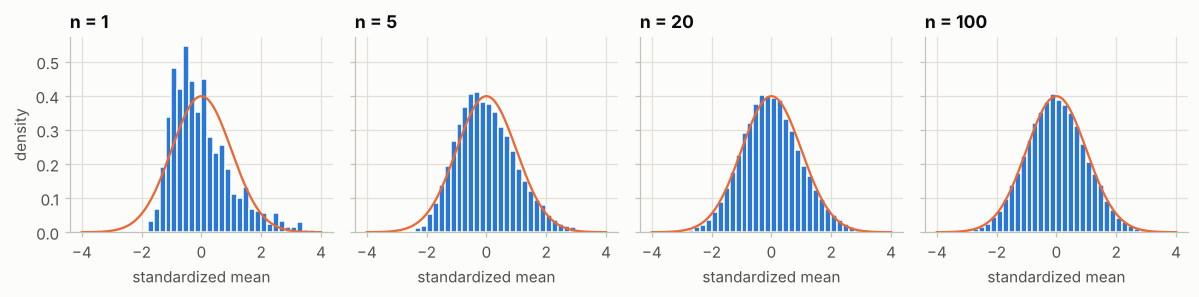

In [11]:
# EXTRA (b): how the distribution of the mean approaches the normal distribution
gamma, kappa = stats.skew(income), stats.kurtosis(income)    # skewness and excess kurtosis of the data
mu = income.mean()
rng = np.random.default_rng(2)
repetitions = 20_000
rows, standardized = [], {}
for n in [1, 2, 5, 10, 20, 50, 100, 500]:
    means = rng.choice(income, size=(repetitions, n)).mean(axis=1)
    z = (means - mu) / (sigma / np.sqrt(n))
    standardized[n] = z
    rows.append({"n": n, "skewness": stats.skew(means), "gamma / sqrt(n)": gamma / np.sqrt(n), "excess kurtosis": stats.kurtosis(means), "kappa / n": kappa / n,
                 "KS distance": stats.kstest(z, "norm").statistic, "share below -1.96": np.mean(z < -1.96), "share above 1.96": np.mean(z > 1.96)})
print(f"the incomes: skewness {gamma:.3f}, excess kurtosis {kappa:.3f}")
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(11, 2.8), sharey=True)
grid = np.linspace(-4, 4, 200)
for ax, n in zip(axes, [1, 5, 20, 100]):
    ax.hist(standardized[n], bins=np.linspace(-4, 4, 41), density=True, color=PALETTE[0], edgecolor=SURFACE)
    ax.plot(grid, stats.norm.pdf(grid), color=PALETTE[1], lw=1.5)
    ax.set_title(f"n = {n}")
    ax.set_xlabel("standardized mean")
axes[0].set_ylabel("density")
plt.tight_layout()
plt.show()

**Analysis of extra (b).**

* **Skewness.** The skewness of the means falls as $\gamma/\sqrt{n}$: 1.049 for $n = 1$, 0.454 for 5, 0.229 for 20, 0.106 for 100, 0.039 for 500, against the theoretical 1.049, 0.469, 0.235, 0.105 and 0.047. The simulation error of a skewness from 20,000 values is about 0.017. The excess kurtosis follows $\kappa/n$ in the same way, with more noise.
* **Distance to the normal distribution.** The Kolmogorov-Smirnov distance falls from 0.094 ($n = 1$) to 0.035 (5), 0.012 (20) and 0.005 (100). From 20 the histograms in the figure are hard to tell from the normal curve.
* **The tails take longest.** The share of standardized means below $-1.96$ and above $+1.96$ should be 2.5% each. For $n = 20$ it is 1.8% and 3.2%; for $n = 100$, 2.2% and 2.7%; even for $n = 500$ it is 2.3% and 2.8%. The normal approximation is good in the centre long before it is good in the tails, and the remaining asymmetry is the skewness of the data: the sample mean is rarely much too low and more often too high, which is what a right-skewed population does.
* "A sample of 30 is enough" is a rule of thumb that depends on the shape of the data: for these incomes (skewness 1.05) the centre is normal at about 20 and the tails at several hundred.

**(c) The finite-population correction.** Samples of size 100, 5,000, 25,000 and 45,000 are drawn *without* replacement from the population of 50,000 incomes (1,000 samples of each size). The cell compares the standard deviation of their means with $\sigma/\sqrt{n}$ (which ignores the correction) and with the corrected value.

In [12]:
# EXTRA (c): sampling without replacement from a finite population
rng = np.random.default_rng(3)
N = len(income)
rows = []
for n in [100, 5000, 25000, 45000]:
    means = np.array([income[rng.permutation(N)[:n]].mean() for _ in range(1000)])
    uncorrected = sigma / np.sqrt(n)
    corrected = uncorrected * np.sqrt((N - n) / (N - 1))
    rows.append({"n": n, "share of the population": n / N, "sd of the means": means.std(ddof=1), "sigma / sqrt(n)": uncorrected, "with correction": corrected})
print(pd.DataFrame(rows).round(3).to_string(index=False))

    n  share of the population  sd of the means  sigma / sqrt(n)  with correction
  100                    0.002         3227.369         3287.171         3283.915
 5000                    0.100          453.680          464.876          441.025
25000                    0.500          149.743          207.899          147.008
45000                    0.900           50.423          154.959           49.003


**Analysis of extra (c).**

* With 100 incomes (0.2% of the population) the correction is negligible: 3,227 simulated, 3,287 without and 3,284 with the correction. With 5,000 (10%) the correction changes the standard error by 5% (465 to 441), a difference of the size of the simulation error of 1,000 repetitions (about 2%), so this row does not decide between the two formulas.
* With 25,000 (50%) the simulated standard deviation is 149.7: the uncorrected value 207.9 is wrong by 39%, the corrected value 147.0 is within 2%. With 45,000 (90%) the simulation gives 50.4, the uncorrected formula 155.0 and the corrected one 49.0. When the sample is the whole population the standard error is zero.
* In practice the correction matters only when the sample is a large share of a finite population (as in a census or an audit of most of a list); for the samples of this chapter it is irrelevant.

**(d) Every statistic has a sampling distribution.** From the population of incomes, 5,000 samples of 100 values are drawn, and six statistics are computed on each: the mean, the median, the 10% trimmed mean, the standard deviation, the 90th percentile and the maximum. The cell reports the centre, the standard error and the skewness of the sampling distribution of each, next to the value of the statistic in the whole population.

In [13]:
# EXTRA (d): the sampling distribution of six different statistics, samples of 100
from scipy.stats import trim_mean

rng = np.random.default_rng(4)
samples = rng.choice(income, size=(5000, 100))
statistics = {
    "mean": (samples.mean(axis=1), income.mean()),
    "median": (np.median(samples, axis=1), np.median(income)),
    "10% trimmed mean": (trim_mean(samples, 0.1, axis=1), trim_mean(income, 0.1)),
    "standard deviation": (samples.std(axis=1, ddof=1), income.std(ddof=1)),
    "90th percentile": (np.percentile(samples, 90, axis=1), np.percentile(income, 90)),
    "maximum": (samples.max(axis=1), income.max()),
}
rows = [{"statistic": name, "population value": truth, "mean over samples": values.mean(), "standard error": values.std(ddof=1),
         "relative standard error": values.std(ddof=1) / truth, "skewness": stats.skew(values)} for name, (values, truth) in statistics.items()]
print(pd.DataFrame(rows).round(3).to_string(index=False))
print(f"\nformula for the mean: sigma / sqrt(100) = {sigma / 10:,.0f}")

         statistic  population value  mean over samples  standard error  relative standard error  skewness
              mean         68760.518          68753.995        3326.178                    0.048     0.155
            median         62000.000          62276.378        3867.209                    0.062     0.199
  10% trimmed mean         65183.553          65308.200        3317.445                    0.051     0.186
standard deviation         32872.035          32684.496        2914.877                    0.089     0.055
   90th percentile        115000.000         112823.082        8847.553                    0.077     0.194
           maximum        199000.000         175415.432       14423.113                    0.072    -0.687

formula for the mean: sigma / sqrt(100) = 3,287


**Analysis of extra (d).**

* **The mean.** The standard error is 3,326, as the formula $\sigma/\sqrt{100} = 3{,}287$ says; its sampling distribution is almost symmetric (skewness 0.16).
* **The median** is less precise than the mean for these data: 3,867, 16% larger. **The 10% trimmed mean** has almost the same standard error as the mean (3,317). It estimates a different quantity, the trimmed mean of the population, 65,184, not the mean 68,761.
* **The standard deviation** itself has a standard error of 2,915, 8.9% of its value; the 90th percentile 8,848 (7.7%). Every number computed from a sample carries its own uncertainty.
* **The maximum** is a different animal: its sampling distribution is skewed to the left (skewness $-0.69$), bounded by the largest income of the population (199,000), and its average over the samples is 175,415, 12% below the population maximum: the maximum of a sample is a biased estimate of the maximum of the population.
* The formula for the standard error of the mean does not carry over to the other statistics, which is why a general method, the bootstrap, is needed.

---
## 4. The bootstrap

*Book section: "The Bootstrap" (with "Resampling Versus Bootstrapping"). The code of the script bootstraps the median of the 50,000 incomes.*

### Summary

* The **bootstrap** estimates the sampling distribution of a statistic from the one sample that is available: draw a sample *with replacement* from the sample, as large as the original one (a **resample**), compute the statistic on it, and repeat this many times. The collection of the values is the bootstrap distribution, and its spread is an estimate of the standard error; its centre against the original value shows the bias.
* It needs no formula and no assumption of normality, and it works for statistics, like the median or a trimmed mean, whose standard error has no simple expression.
* The idea can be pictured as putting the observed values in a large urn, replicating them to make a pseudo-population, and drawing from it. The bootstrap does **not** add information: it cannot compensate for a small or an unrepresentative sample, it only shows how much the statistic would vary if the population looked like the sample.
* *Resampling* is the broader term for drawing repeatedly from the data: with replacement it is the bootstrap, without replacement it is the basis of the permutation tests of Chapter 3.
* The script bootstraps the median of the incomes 1,000 times and prints the original median, the bias and the standard error.

### Theory

**The plug-in principle.** The sampling distribution of $\hat\theta = T(F_n)$, where $F_n$ is the empirical distribution of the sample, depends on the unknown distribution $F$ of the population. The bootstrap (Efron, 1979) replaces $F$ by $F_n$: a bootstrap sample $X_1^*, \dots, X_n^*$ is a random sample from $F_n$, which means a draw with replacement from the data, and the distribution of $\hat\theta^* = T(F_n^*)$ around $\hat\theta$ stands in for the distribution of $\hat\theta$ around $\theta$. In practice the distribution is approximated by $B$ Monte Carlo resamples:
$$\widehat{\operatorname{SE}}_{\text{boot}} = \sqrt{\frac{1}{B-1}\sum_{b=1}^{B}\bigl(\hat\theta^*_b - \bar{\theta}^*\bigr)^2}, \qquad \widehat{\text{bias}}_{\text{boot}} = \bar\theta^* - \hat\theta .$$

**What a resample looks like.** In a resample of the $n$ observations, each observation appears a number of times that is binomial with parameters $n$ and $1/n$, almost Poisson with mean 1. The chance that a given observation is left out is $(1 - 1/n)^n \to e^{-1} \approx 0.368$, so a resample contains only about 63.2% of the distinct observations. The number of distinct resamples is $\binom{2n-1}{n}$, so for all but tiny samples they cannot all be enumerated.

**How many resamples?** $B$ only controls the Monte Carlo error of the estimate, which is about $1/\sqrt{2B}$ in relative terms for a standard error (2.2% for $B = 1{,}000$). The remaining error, the difference between $F_n$ and $F$, does not depend on $B$. A thousand resamples are enough for a standard error; intervals in the tails need more (section 5).

**The bootstrap standard error of the mean** is $\hat\sigma/\sqrt{n}$ with the divisor $n$ in $\hat\sigma$, because the standard deviation of $F_n$ is $\sqrt{(n-1)/n}\;s$: it is smaller than the usual estimate by a factor $\sqrt{(n-1)/n}$, which matters only for small $n$.

**Where it fails.** The bootstrap needs the statistic to depend smoothly on the data. It fails for extremes such as the maximum (the resample maximum equals the sample maximum with probability $1 - (1-1/n)^n \approx 63\%$, so the bootstrap distribution has a large atom instead of the continuous distribution of the true one), for very small samples, and when observations are not independent (time series need a block bootstrap).

### Book code

The script resamples the 50,000 incomes 1,000 times (each resample has 50,000 values) and records the median of each. The script has no seed; the cell below adds one.

In [14]:
# BOOK CODE (The Bootstrap): the bootstrap of the median income
np.random.seed(2024)  # NOT IN THE BOOK: the book's resampling has no seed

results = []
for nrepeat in range(1000):
    sample = resample(loans_income)
    results.append(sample.median())
results = pd.Series(results)
print('Bootstrap Statistics:')
print(f'original: {loans_income.median()}')
print(f'bias: {results.mean() - loans_income.median()}')
print(f'std. error: {results.std()}')

Bootstrap Statistics:
original: 62000.0
bias: -78.12249999999767
std. error: 226.7475218881839


**Output analysis.**

* The median income of the 50,000 incomes is 62,000. The 1,000 bootstrap medians have a mean 78 dollars lower (the bias, 0.13% of the median) and a standard deviation, the **bootstrap standard error**, of 226.7.
* The bias is small compared with the standard error (a third of it), so there is no reason to correct the estimate. The standard error is small because the resamples have 50,000 values each; the same median computed from a sample of 100 incomes has a standard error of about 3,855 (extra 4(c)).
* The cell has no seed in the book; with the seed of this notebook the printed values are reproducible, and another seed would change the digits of the bias and of the standard error slightly.

### Extra experiments

**(a) The bootstrap by hand.** One sample of 200 incomes is drawn from the population. Its median is bootstrapped in three ways: with numpy index draws written out, with `sklearn.utils.resample` (as in the book), and with `scipy.stats.bootstrap`. The cell also measures the share of distinct observations in a resample.

In [15]:
# EXTRA (a): three ways to bootstrap the median of one sample of 200 incomes
from scipy.stats import bootstrap

rng = np.random.default_rng(10)
sample200 = rng.choice(income, size=200, replace=False)
B = 5000

by_hand = np.array([np.median(sample200[rng.integers(0, 200, 200)]) for _ in range(B)])
with_sklearn = np.array([np.median(resample(sample200, random_state=int(seed))) for seed in rng.integers(0, 2 ** 31, B)])
with_scipy = bootstrap((sample200,), np.median, n_resamples=B, method="percentile", random_state=np.random.default_rng(10))

print(f"median of the sample: {np.median(sample200):,.0f}; median of the population: {np.median(income):,.0f}")
print(pd.DataFrame({"mean of the resample medians": [by_hand.mean(), with_sklearn.mean(), with_scipy.bootstrap_distribution.mean()],
                    "standard error": [by_hand.std(ddof=1), with_sklearn.std(ddof=1), with_scipy.standard_error]},
                   index=["numpy by hand", "sklearn.utils.resample", "scipy.stats.bootstrap"]).round(0).to_string())

distinct = np.mean([len(np.unique(rng.integers(0, 200, 200))) / 200 for _ in range(2000)])
print(f"\nshare of the observations that appear in a resample of 200: {distinct:.3f} (theory 1 - (1 - 1/200)^200 = {1 - (1 - 1 / 200) ** 200:.3f}, limit 1 - 1/e = {1 - np.exp(-1):.3f})")

median of the sample: 60,000; median of the population: 62,000
                        mean of the resample medians  standard error
numpy by hand                                60296.0          2810.0
sklearn.utils.resample                       60269.0          2835.0
scipy.stats.bootstrap                        60297.0          2803.0

share of the observations that appear in a resample of 200: 0.634 (theory 1 - (1 - 1/200)^200 = 0.633, limit 1 - 1/e = 0.632)


**Analysis of extra (a).**

* The three implementations give the same standard error of the median within the Monte Carlo error: 2,810 (by hand), 2,835 (`sklearn.utils.resample`) and 2,803 (`scipy.stats.bootstrap`); with $B = 5{,}000$ the relative error is about 1%. They differ only in the source of the random numbers.
* The bootstrap distribution is centred on the median of the *sample* (60,000; the average of the resample medians is about 60,290), not on the median of the population (62,000). The 2,000 dollars between them is 0.7 standard errors. The bootstrap describes the variation around the estimate that was computed from the data, and it cannot know the true value.
* The share of observations that appear in a resample is 0.634, in line with $1 - (1-1/200)^{200} = 0.633$ and the limit $1 - 1/e = 0.632$: a resample leaves out about 37% of the observations and repeats others.

**(b) How many resamples?** For the mean of one sample of 200 incomes the exact bootstrap standard error is known, $\hat\sigma/\sqrt{n}$ with the divisor $n$. The cell computes the Monte Carlo bootstrap estimate with $B$ from 50 to 20,000, repeats it 40 times for each $B$, and compares the spread of the estimates with the rule $1/\sqrt{2B}$.

In [16]:
# EXTRA (b): the Monte Carlo error of the bootstrap standard error as a function of B
rng = np.random.default_rng(11)
sample200 = rng.choice(income, size=200, replace=False)
exact = sample200.std(ddof=0) / np.sqrt(200)            # bootstrap standard error of the mean for B = infinity
usual = sample200.std(ddof=1) / np.sqrt(200)
rows = []
for B in [50, 100, 500, 1000, 5000, 20000]:
    estimates = np.array([sample200[rng.integers(0, 200, size=(B, 200))].mean(axis=1).std(ddof=1) for _ in range(40)])
    rows.append({"B": B, "mean of the estimates": estimates.mean(), "sd of the estimates": estimates.std(ddof=1),
                 "relative sd": estimates.std(ddof=1) / exact, "1 / sqrt(2B)": 1 / np.sqrt(2 * B)})
print(f"bootstrap standard error of the mean with B = infinity: {exact:,.1f}; usual s / sqrt(n): {usual:,.1f}")
print(pd.DataFrame(rows).round(4).to_string(index=False))

bootstrap standard error of the mean with B = infinity: 2,597.1; usual s / sqrt(n): 2,603.6
    B  mean of the estimates  sd of the estimates  relative sd  1 / sqrt(2B)
   50              2567.8552             297.0213       0.1144        0.1000
  100              2594.7355             197.5049       0.0760        0.0707
  500              2590.3293              90.5924       0.0349        0.0316
 1000              2597.0487              59.4965       0.0229        0.0224
 5000              2599.2149              23.9025       0.0092        0.0100
20000              2598.2686              11.0883       0.0043        0.0050


**Analysis of extra (b).**

* The bootstrap standard error of the mean with infinitely many resamples is 2,597.1, and the usual $s/\sqrt{n}$ is 2,603.6: their ratio is $\sqrt{199/200} = 0.9975$, the factor of the divisor $n$ against $n-1$.
* The estimates from finite $B$ are centred on that value, and their spread falls as $1/\sqrt{B}$: a relative standard deviation of 0.114 for $B = 50$, 0.035 for 500, 0.023 for 1,000, 0.009 for 5,000 and 0.004 for 20,000, close to the rule $1/\sqrt{2B}$ (0.100, 0.032, 0.022, 0.010, 0.005; each value comes from 40 repetitions and has an error of about 11%).
* 1,000 resamples give a standard error that is accurate to about 2%, much smaller than the uncertainty that comes from having only 200 observations (extra 4(c)). A few dozen resamples are too few, and tens of thousands are wasted for a standard error.

**(c) The bootstrap against the true sampling distribution.** Because the population of 50,000 incomes is known, the true standard error of the median of 100 incomes can be computed from 10,000 fresh samples. The cell then draws 200 different samples of 100 incomes, bootstraps the median of each with $B = 500$, and compares the 200 bootstrap standard errors with the true one.

true standard error of the median of 100 incomes (10,000 fresh samples): 3,855
bootstrap estimates over 200 samples: mean 3,914, sd 871, 5% / 50% / 95% quantiles 2,833 / 3,726 / 5,316
share of the samples whose bootstrap estimate lies within 20% of the true value: 60%


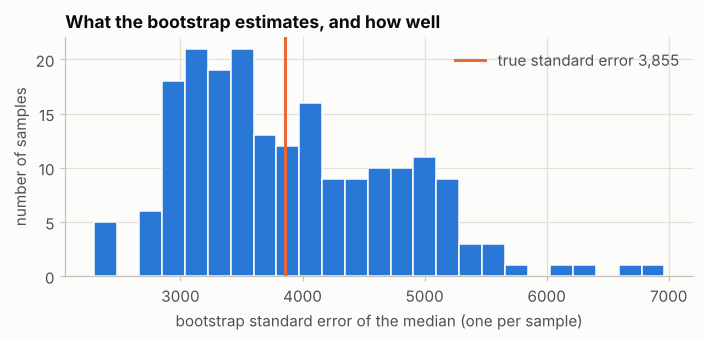

In [17]:
# EXTRA (c): bootstrap standard errors of the median of 100 incomes, over 200 different samples
rng = np.random.default_rng(12)
true_medians = np.median(rng.choice(income, size=(10_000, 100)), axis=1)
true_se = true_medians.std(ddof=1)

boot_se = []
for _ in range(200):
    one_sample = rng.choice(income, size=100)
    boot_se.append(np.median(one_sample[rng.integers(0, 100, size=(500, 100))], axis=1).std(ddof=1))
boot_se = np.array(boot_se)
print(f"true standard error of the median of 100 incomes (10,000 fresh samples): {true_se:,.0f}")
print(f"bootstrap estimates over 200 samples: mean {boot_se.mean():,.0f}, sd {boot_se.std(ddof=1):,.0f}, "
      f"5% / 50% / 95% quantiles {np.quantile(boot_se, 0.05):,.0f} / {np.median(boot_se):,.0f} / {np.quantile(boot_se, 0.95):,.0f}")
print(f"share of the samples whose bootstrap estimate lies within 20% of the true value: {np.mean(np.abs(boot_se / true_se - 1) < 0.2):.0%}")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(boot_se, bins=25, color=PALETTE[0], edgecolor=SURFACE)
ax.axvline(true_se, color=PALETTE[1], lw=2, label=f"true standard error {true_se:,.0f}")
ax.set_xlabel("bootstrap standard error of the median (one per sample)"); ax.set_ylabel("number of samples")
ax.set_title("What the bootstrap estimates, and how well")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis of extra (c).**

* The true standard error of the median of 100 incomes, from 10,000 fresh samples, is 3,855.
* The bootstrap estimates from 200 different samples average 3,914, 1.5% above the truth, so the bootstrap is right *on average*. But a single estimate is noisy: the standard deviation of the 200 estimates is 871 (22% of the true value), the middle 90% of them lies between 2,833 and 5,316, and only 60% are within 20% of the truth.
* The reason is the one that was given in the theory: the bootstrap does not add information. With 100 observations, the estimate of the variation is itself based on 100 observations, and a sample that happens to be tight or spread out gives a bootstrap distribution that is tight or spread out.

**(d) When the bootstrap fails: the maximum.** A sample of 100 values from the uniform distribution on $(0, 1)$ has a maximum that is close to 1. The cell compares the true sampling distribution of the maximum (from 10,000 samples) with the bootstrap distribution of one sample's maximum (10,000 resamples), and measures the share of resamples whose maximum equals the sample maximum.

sample maximum 0.9904
true sampling distribution of the maximum: 10,000 distinct values in 10,000 samples; mean 0.9901, sd 0.0098
bootstrap distribution: 9 distinct values in 10,000 resamples; mean 0.9858, sd 0.0085
share of resamples whose maximum equals the sample maximum: 0.634 (theory 1 - (1 - 1/n)^n = 0.634)


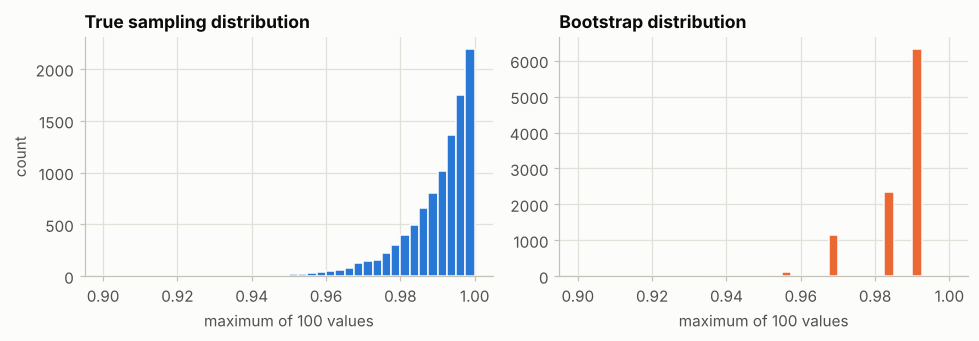

In [18]:
# EXTRA (d): the bootstrap distribution of a maximum
rng = np.random.default_rng(13)
n = 100
true_max = rng.random((10_000, n)).max(axis=1)
one_sample = rng.random(n)
boot_max = one_sample[rng.integers(0, n, size=(10_000, n))].max(axis=1)
print(f"sample maximum {one_sample.max():.4f}")
print(f"true sampling distribution of the maximum: {len(np.unique(true_max)):,} distinct values in 10,000 samples; mean {true_max.mean():.4f}, sd {true_max.std(ddof=1):.4f}")
print(f"bootstrap distribution: {len(np.unique(boot_max))} distinct values in 10,000 resamples; mean {boot_max.mean():.4f}, sd {boot_max.std(ddof=1):.4f}")
print(f"share of resamples whose maximum equals the sample maximum: {np.mean(boot_max == one_sample.max()):.3f} (theory 1 - (1 - 1/n)^n = {1 - (1 - 1 / n) ** n:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharex=True)
bins = np.linspace(0.9, 1, 41)
axes[0].hist(true_max, bins=bins, color=PALETTE[0], edgecolor=SURFACE)
axes[0].set_title("True sampling distribution")
axes[1].hist(boot_max, bins=bins, color=PALETTE[1], edgecolor=SURFACE)
axes[1].set_title("Bootstrap distribution")
for ax in axes:
    ax.set_xlabel("maximum of 100 values")
axes[0].set_ylabel("count")
plt.tight_layout()
plt.show()

**Analysis of extra (d).**

* The **true** sampling distribution of the maximum of 100 uniform values is continuous (10,000 different values in 10,000 samples) with mean 0.9901 and standard deviation 0.0098, and a long tail to the left.
* The **bootstrap** distribution takes only 9 different values in 10,000 resamples; 63.4% of the resamples have the sample maximum (0.9904) as their maximum, as $1 - (1 - 1/n)^n = 63.4\%$ predicts, and the next most frequent values are the second, third, ... largest observations. Its standard deviation (0.0085) and shape are wrong.
* The statistic depends on a single observation, so it is not a smooth function of the data. The same applies to any extreme: the bootstrap is a good method for means, medians, trimmed means, correlations, regression coefficients, and a poor one for the largest and the smallest value.

---
## 5. Confidence intervals

*Book section: "Confidence Intervals". The code of the script builds a 90% and a 95% bootstrap interval for the mean of a sample of 20 incomes.*

### Summary

* A **point estimate** (a sample mean) says nothing about its own uncertainty. A **confidence interval** adds it: a range around the estimate that is meant to contain the true value with a stated probability, the **confidence level** (90%, 95%, 99%). Every interval has two **endpoints**.
* The level is a statement about the *procedure*: if the whole study were repeated many times, the intervals computed in this way would contain the true value in about 90% (or 95%) of the repetitions. It is not the probability that a particular, already computed interval contains it.
* A higher level gives a wider interval (a surer statement is a less precise one), and a larger sample gives a narrower one.
* The bootstrap gives an interval without a formula: draw many resamples, compute the statistic on each, and cut off the same share of the bootstrap distribution at each end: for 90%, 5% at each end. The endpoints are the 5th and 95th percentiles of the resampled statistics.
* The script takes a random sample of 20 incomes (without replacement) from the 50,000, bootstraps its mean 500 times, and draws the 90% and the 95% intervals on the histogram of the bootstrap means.

### Theory

**Coverage.** A procedure that returns an interval $[L, U]$ from the data has *coverage* $1 - \alpha$ if $P(L \le \theta \le U) = 1 - \alpha$ over repeated samples; $\theta$ is fixed and $L, U$ are random. For a particular realized interval the statement "$\theta$ lies in it" is true or false, not probable. A procedure whose actual coverage is lower than the nominal level is called *liberal* or anti-conservative.

**The classical interval for a mean.** If the data are normal, $(\bar X - \mu)/(s/\sqrt{n})$ has Student's $t$ distribution with $n - 1$ degrees of freedom (section 8) and the interval is
$$\bar X \;\pm\; t_{n-1,\,1-\alpha/2}\; \frac{s}{\sqrt{n}} .$$
For non-normal data it is approximate; the approximation improves with $n$ (central limit theorem) and is worse for skewed data.

**The percentile bootstrap interval** is $[\hat\theta^*_{\alpha/2}, \hat\theta^*_{1-\alpha/2}]$, the quantiles of the bootstrap distribution. Its limitations: its standard error uses the divisor $n$ and so is too small by $\sqrt{(n-1)/n}$, it does not widen to account for estimating the scale from a small sample (the reason for the $t$ quantiles), and it inherits the skewness of the sample. As a result, for small $n$ it **under-covers** (extra 5(a)). Improvements exist: the *basic* bootstrap interval reflects the bootstrap quantiles around the estimate, the *bootstrap-$t$* interval studentizes each resample, and the **BCa** interval (bias-corrected and accelerated; Efron, 1987) corrects the percentiles for bias and skewness.

**Width.** For the mean, the width is about $2\, q \,s/\sqrt{n}$ with $q$ the normal or $t$ quantile (1.645 for 90%, 1.960 for 95%, 2.576 for 99%): it is proportional to $1/\sqrt{n}$ and to the multiplier of the level. Going from 90% to 99% widens an interval by 57%; halving the width costs four times the data.

### Book code

First the official code for the 90% interval. It prints the mean of the whole population, takes the sample of 20 (the script sets the seed 3), and bootstraps its mean 500 times.

68760.51844
55734.1


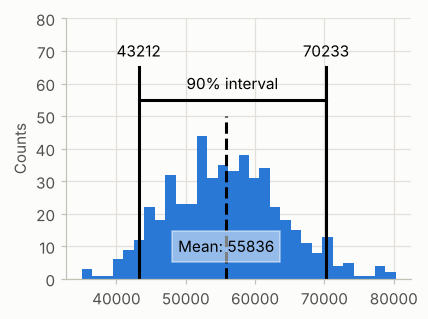

In [19]:
# BOOK CODE (Confidence Intervals): the 90% bootstrap interval for the mean of a sample of 20 incomes
print(loans_income.mean())
np.random.seed(seed=3)
# create a sample of 20 loan income data
sample20 = resample(loans_income, n_samples=20, replace=False)
print(sample20.mean())
results = []
for nrepeat in range(500):
    sample = resample(sample20)
    results.append(sample.mean())
results = pd.Series(results)

confidence_interval = list(results.quantile([0.05, 0.95]))
ax = results.plot.hist(bins=30, figsize=(4, 3))
ax.plot(confidence_interval, [55, 55], color='black')
for x in confidence_interval:
    ax.plot([x, x], [0, 65], color='black')
    ax.text(x, 70, f'{x:.0f}',
            horizontalalignment='center', verticalalignment='center')
ax.text(sum(confidence_interval) / 2, 60, '90% interval',
        horizontalalignment='center', verticalalignment='center')

meanIncome = results.mean()
ax.plot([meanIncome, meanIncome], [0, 50], color='black', linestyle='--')
ax.text(meanIncome, 10, f'Mean: {meanIncome:.0f}',
        bbox=dict(facecolor='white', edgecolor='white', alpha=0.5),
        horizontalalignment='center', verticalalignment='center')
ax.set_ylim(0, 80)
ax.set_ylabel('Counts')

plt.tight_layout()
plt.show()

The second block of the script repeats the computation (with the same seed, so with the same resamples) and draws the 90% and the 95% intervals in two separate figures. The script comments out the last `plt.show()`; in a notebook the figures appear at the end of the cell.

Text(0, 0.5, 'Counts')

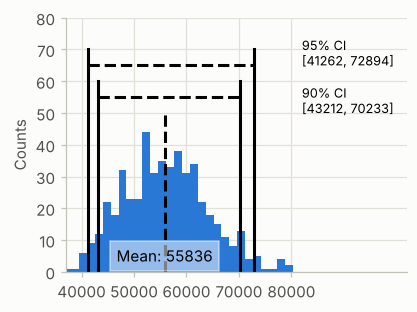

In [20]:
# BOOK CODE (Confidence Intervals): the 90% and the 95% intervals, in two figures
np.random.seed(seed=3)
# create a sample of 20 loan income data
sample20 = resample(loans_income, n_samples=20, replace=False)

results = []
for nrepeat in range(500):
    sample = resample(sample20)
    results.append(sample.mean())
results = pd.Series(results)

confidence_interval = list(results.quantile([0.05, 0.95]))
ax = results.plot.hist(bins=30, figsize=(4, 3), color='C1')
ax.plot(confidence_interval, [55, 55], color='black', linestyle='--')
for x in confidence_interval:
    ax.plot([x, x], [0, 60], color='black')
ax.text(82000, 50,
        f'90% CI\n[{confidence_interval[0]:.0f}, {confidence_interval[1]:.0f}]',
       fontsize='small')

confidence_interval = list(results.quantile([0.025, 0.975]))
ax = results.plot.hist(bins=30, figsize=(4, 3))
ax.plot(confidence_interval, [65, 65], color='black', linestyle='--')
for x in confidence_interval:
    ax.plot([x, x], [0, 70], color='black')
ax.text(82000, 65,
        f'95% CI\n[{confidence_interval[0]:.0f}, {confidence_interval[1]:.0f}]',
       fontsize='small')
# ax.text(sum(confidence_interval) / 2, 264, '95 % interval',
#         horizontalalignment='center', verticalalignment='center')

meanIncome = results.mean()
ax.plot([meanIncome, meanIncome], [0, 50], color='black', linestyle='--')
ax.text(meanIncome, 5, f'Mean: {meanIncome:.0f}',
        bbox=dict(facecolor='white', edgecolor='white', alpha=0.5),
        horizontalalignment='center', verticalalignment='center')
ax.set_ylim(0, 80)
ax.set_xlim(37000, 102000)
ax.set_xticks([40000, 50000, 60000, 70000, 80000])
ax.set_ylabel('Counts')

# plt.tight_layout()
# plt.show()

**Output analysis.**

* **The numbers.** The mean of all 50,000 incomes is 68,760.5; the sample of 20 incomes has a mean of 55,734.1, 19% below it. This is sampling error: with 20 values the mean can be far from the truth. The bootstrap interval is built around the sample, not around the population.
* **The first figure** shows the bootstrap distribution of the mean of 500 resamples, centred near 55,800 ("Mean: 55836", the mean of the bootstrap means, 100 above the sample mean), and the 90% interval, from 43,212 to 70,233, whose ends are the 5th and 95th percentiles. It is not symmetric around the mean (12,600 below, 14,400 above), because the data are right-skewed. The upper end happens to be just above the population mean, so this interval contains it.
* **The second block** reuses the same seed and so the same sample and the same resamples. It draws the 90% interval [43,212, 70,233] and the 95% interval [41,262, 72,894] on one histogram. The 95% interval is 17% wider than the 90% one, the ratio of the multipliers 1.96/1.645 = 1.19 in numbers. In the notebook the cell displays one figure: the second `plot.hist` call appears to draw on the same axes as the first, so the first histogram of the block (orange in the code) lies under the blue one, which has the same data.
* The line `Text(0, 0.5, 'Counts')` under the figure is the value of the last statement of the cell (the `set_ylabel` call), which the notebook prints because the script's `plt.show()` is commented out.

### Extra experiments

**(a) The actual coverage.** The population is the 50,000 incomes, whose mean is known. For sample sizes 10, 20, 50 and 200, the cell draws 1,500 samples and builds, for each, a 90% interval in three ways: the percentile bootstrap (500 resamples), the classical $t$ interval, and the interval with the normal quantile $\bar x \pm 1.645\,s/\sqrt{n}$. It reports the share of intervals that contain the population mean, how the misses split between the two sides, and the mean width.

In [21]:
# EXTRA (a): coverage of three 90% intervals for the mean, samples from a right-skewed population
rng = np.random.default_rng(20)
mu = income.mean()
repetitions, B, level = 1500, 500, 0.90
q_t_all = {n: stats.t.ppf(1 - (1 - level) / 2, n - 1) for n in (10, 20, 50, 200)}
z = stats.norm.ppf(1 - (1 - level) / 2)
rows = []
for n in (10, 20, 50, 200):
    result = {name: {"hit": 0, "low": 0, "high": 0, "width": 0.0} for name in ("percentile bootstrap", "t interval", "normal interval")}
    for _ in range(repetitions):
        x = rng.choice(income, size=n, replace=False)
        m, s = x.mean(), x.std(ddof=1)
        boot = x[rng.integers(0, n, size=(B, n))].mean(axis=1)
        intervals = {"percentile bootstrap": np.quantile(boot, [(1 - level) / 2, 1 - (1 - level) / 2]),
                     "t interval": m + np.array([-1, 1]) * q_t_all[n] * s / np.sqrt(n),
                     "normal interval": m + np.array([-1, 1]) * z * s / np.sqrt(n)}
        for name, (lo, hi) in intervals.items():
            r = result[name]
            r["hit"] += lo <= mu <= hi
            r["low"] += hi < mu          # the interval lies entirely below the true mean
            r["high"] += lo > mu         # the interval lies entirely above the true mean
            r["width"] += hi - lo
    for name, r in result.items():
        rows.append({"n": n, "interval": name, "coverage": r["hit"] / repetitions, "misses below": r["low"] / repetitions,
                     "misses above": r["high"] / repetitions, "mean width": r["width"] / repetitions})
print(f"nominal level {level:.0%}; population mean {mu:,.0f}; with 1,500 samples the standard error of a coverage near 0.9 is {np.sqrt(0.9 * 0.1 / repetitions):.3f}")
print(pd.DataFrame(rows).round(3).to_string(index=False))

nominal level 90%; population mean 68,761; with 1,500 samples the standard error of a coverage near 0.9 is 0.008
  n             interval  coverage  misses below  misses above  mean width
 10 percentile bootstrap     0.821         0.126         0.053   30766.464
 10           t interval     0.876         0.099         0.025   36352.280
 10      normal interval     0.844         0.117         0.039   32618.928
 20 percentile bootstrap     0.859         0.092         0.049   22830.320
 20           t interval     0.883         0.086         0.031   24771.599
 20      normal interval     0.870         0.093         0.037   23564.213
 50 percentile bootstrap     0.879         0.071         0.049   14894.356
 50           t interval     0.895         0.069         0.035   15454.555
 50      normal interval     0.888         0.074         0.038   15162.368
200 percentile bootstrap     0.901         0.051         0.048    7559.793
200           t interval     0.909         0.049         0.041

**Analysis of extra (a).**

* **None of the three intervals reaches 90% for small samples.** The coverage of the percentile bootstrap interval is 82.1% for $n = 10$, 85.9% for 20, 87.9% for 50 and 90.1% for 200; the $t$ interval gives 87.6%, 88.3%, 89.5% and 90.9%; the normal interval 84.4%, 87.0%, 88.8% and 90.7%. With 1,500 samples the standard error of a coverage near 0.9 is 0.008, so the shortfall is clear for $n \le 20$ and fades by $n = 200$.
* **The percentile bootstrap is the most liberal** for $n \le 50$, and the $t$ interval the least. The bootstrap intervals are also the shortest (22,830 against 24,772 for $t$ at $n = 20$): they use the divisor $n$ (a factor $\sqrt{19/20} = 0.975$ on the standard deviation) and no allowance for estimating the scale (the $t$ multiplier 1.73 against 1.645).
* **The misses are lopsided.** For $n = 20$ and the $t$ interval, 8.6% of the intervals lie entirely below the population mean and 3.1% entirely above it. With a right-skewed population most samples have a mean below the population mean and a small standard deviation, so their intervals are short exactly when they are placed too low.
* The lesson is not that the bootstrap is bad but that no interval is exact for a small, skewed sample: for $n = 10$ the nominal 90% interval of the bootstrap is a 82% interval.

**(b) Width against sample size and level.** The sample sizes are 20, 80, 320 and 1,280 (each four times the previous one) and the levels 80%, 90%, 95% and 99%. For each size the cell draws 200 samples, computes the percentile bootstrap interval ($B = 500$) at the four levels and reports the mean width.

In [22]:
# EXTRA (b): width of the percentile bootstrap interval against n and the confidence level
rng = np.random.default_rng(21)
levels = [0.80, 0.90, 0.95, 0.99]
rows = []
for n in (20, 80, 320, 1280):
    widths = {lv: [] for lv in levels}
    for _ in range(200):
        x = rng.choice(income, size=n, replace=False)
        boot = x[rng.integers(0, n, size=(500, n))].mean(axis=1)
        for lv in levels:
            lo, hi = np.quantile(boot, [(1 - lv) / 2, 1 - (1 - lv) / 2])
            widths[lv].append(hi - lo)
    rows.append({"n": n, **{f"{lv:.0%}": np.mean(widths[lv]) for lv in levels}})
table = pd.DataFrame(rows).set_index("n")
print(table.round(0).to_string())
print("\nratio of the width to the width for the previous (four times smaller) n")
print((table / table.shift(1)).dropna().round(2).to_string())
print("\nratio of the width at each level to the width at 90%")
print((table.T / table["90%"]).T.round(2).drop(columns="90%").mean().round(2).to_string())
print(f"normal multipliers 1.282, 1.645, 1.960, 2.576 give the ratios {1.282 / 1.645:.2f}, 1, {1.960 / 1.645:.2f}, {2.576 / 1.645:.2f}")

          80%      90%      95%      99%
n                                       
20    18170.0  23182.0  27473.0  35238.0
80     9149.0  11736.0  13965.0  17963.0
320    4676.0   5981.0   7079.0   9122.0
1280   2347.0   3016.0   3581.0   4624.0

ratio of the width to the width for the previous (four times smaller) n
       80%   90%   95%   99%
n                           
80    0.50  0.51  0.51  0.51
320   0.51  0.51  0.51  0.51
1280  0.50  0.50  0.51  0.51

ratio of the width at each level to the width at 90%
80%    0.78
95%    1.19
99%    1.53
normal multipliers 1.282, 1.645, 1.960, 2.576 give the ratios 0.78, 1, 1.19, 1.57


**Analysis of extra (b).**

* Each factor of 4 in $n$ divides the width by 2 (ratios 0.50 to 0.51 in every column), the square-root law again: for the 90% interval the width is 23,182 for $n = 20$, 11,736 for 80, 5,981 for 320 and 3,016 for 1,280.
* The width grows with the level, in proportion to the multiplier: relative to the 90% interval the 80% interval is 0.78 as wide, the 95% interval 1.19 and the 99% interval 1.53, against the normal multipliers 0.78, 1.19 and 1.57. The 99% interval is slightly too narrow because with 500 resamples its ends are the 2nd and 3rd most extreme values, which are noisy and tend to be too close to the centre; intervals with a high level need many more resamples.
* The cost of precision: a 99% interval from 1,280 incomes (4,624) is narrower than a 90% interval from 320 (5,981), by a factor of 0.77: four times the data more than pays for the step from 90% to 99%.

**(c) What does "90%" mean?** 100 samples of 50 incomes are drawn and a 90% $t$ interval for the mean is computed from each. The figure draws the 100 intervals; those that miss the population mean are in orange.

14 of the 100 intervals miss the population mean 68,761: 9 lie below it and 5 above it


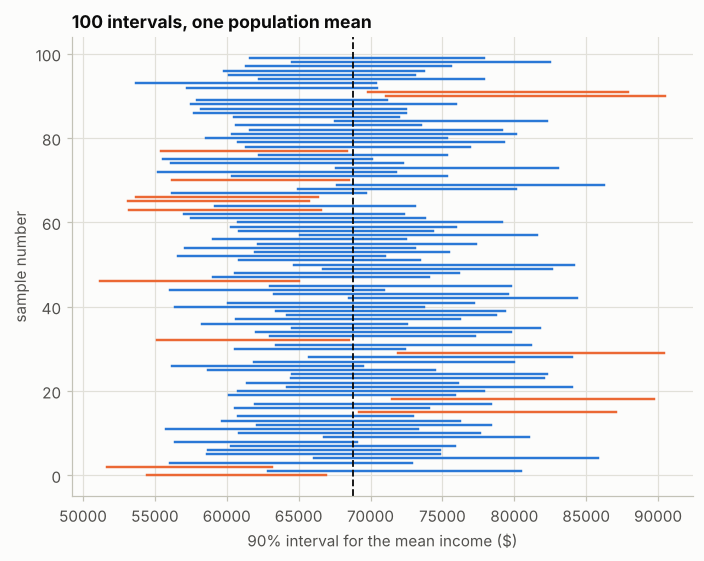

In [23]:
# EXTRA (c): 100 intervals from 100 samples; the level is a property of the procedure, not of one interval
rng = np.random.default_rng(22)
n, level = 50, 0.90
q = stats.t.ppf(1 - (1 - level) / 2, n - 1)
intervals = []
for _ in range(100):
    x = rng.choice(income, size=n, replace=False)
    half = q * x.std(ddof=1) / np.sqrt(n)
    intervals.append((x.mean() - half, x.mean() + half))
intervals = np.array(intervals)
miss = (intervals[:, 1] < mu) | (intervals[:, 0] > mu)
print(f"{int(miss.sum())} of the 100 intervals miss the population mean {mu:,.0f}: "
      f"{int((intervals[:, 1] < mu).sum())} lie below it and {int((intervals[:, 0] > mu).sum())} above it")

fig, ax = plt.subplots(figsize=(6.5, 5.2))
for i, ((lo, hi), missed) in enumerate(zip(intervals, miss)):
    ax.plot([lo, hi], [i, i], color=PALETTE[1] if missed else PALETTE[0], lw=1.6)
ax.axvline(mu, color=INK, lw=1.2, ls="--")
ax.set_xlabel("90% interval for the mean income ($)"); ax.set_ylabel("sample number")
ax.set_title("100 intervals, one population mean")
plt.tight_layout()
plt.show()

**Analysis of extra (c).**

* Of 100 intervals, 14 miss the population mean (9 lie below it and 5 above it). With a nominal level of 90%, 10 misses are expected, and the standard deviation of the count is 3, so 14 is not unusual; another 100 samples would give another number.
* The figure shows what the level means: every sample gives a different interval, with a different centre and a slightly different length, and the level is the long-run share of intervals that contain the fixed population mean (the dashed line). It is not the probability that *this* interval contains the mean: each interval does or does not.
* Misses on the low side outnumber those on the high side again (9 to 5), as in extra 5(a).

**(d) Other bootstrap intervals.** For the book's sample of 20 incomes (the same `sample20`), the cell computes with `scipy.stats.bootstrap` the percentile, the basic and the BCa intervals (9,999 resamples, 90%) for the mean and for the median, together with the classical $t$ interval for the mean.

In [24]:
# EXTRA (d): percentile, basic and BCa intervals for the mean and the median of the book's sample of 20
from scipy.stats import bootstrap

x20 = sample20.to_numpy(float)
rows = []
for stat_name, stat in (("mean", np.mean), ("median", np.median)):
    for method in ("percentile", "basic", "BCa"):
        ci = bootstrap((x20,), stat, n_resamples=9999, confidence_level=0.90, method=method, random_state=np.random.default_rng(5)).confidence_interval
        rows.append({"statistic": stat_name, "interval": method, "lower": ci.low, "upper": ci.high, "width": ci.high - ci.low})
half = stats.t.ppf(0.95, 19) * x20.std(ddof=1) / np.sqrt(20)
rows.append({"statistic": "mean", "interval": "t interval", "lower": x20.mean() - half, "upper": x20.mean() + half, "width": 2 * half})
print(f"sample of 20: mean {x20.mean():,.0f}, median {np.median(x20):,.0f}; skewness {stats.skew(x20, bias=False):.2f}; population mean {income.mean():,.0f}, median {np.median(income):,.0f}")
print(pd.DataFrame(rows).round(0).to_string(index=False))

sample of 20: mean 55,734, median 50,500; skewness 1.32; population mean 68,761, median 62,000
statistic   interval   lower   upper   width
     mean percentile 42961.0 69744.0 26783.0
     mean      basic 41724.0 68507.0 26783.0
     mean        BCa 44576.0 72164.0 27588.0
   median percentile 30000.0 60000.0 30000.0
   median      basic 41000.0 71000.0 30000.0
   median        BCa 30500.0 65500.0 35000.0
     mean t interval 41236.0 70233.0 28997.0


**Analysis of extra (d).**

* **The mean.** The sample of 20 has mean 55,734, median 50,500 and skewness 1.32. The 90% percentile interval is [42,961, 69,744], the basic one [41,724, 68,507], the BCa one [44,576, 72,164] and the $t$ interval [41,236, 70,233]. The basic interval is the percentile interval reflected around the estimate; BCa moves it to the right, which is the direction of the skewness, and its upper end is the one that leaves the most room above the population mean (68,761).
* **The median.** The percentile interval is [30,000, 60,000], the basic [41,000, 71,000] and the BCa [30,500, 65,500]. They differ much more than for the mean, because with 20 observations the bootstrap distribution of the median is lumpy (its values are values of the sample) and skewed. The population median, 62,000, is outside the percentile interval and inside the other two. This is one sample, so it does not rank the methods, but it shows that the choice matters for a median and for small $n$.
* The $t$ interval is the only one with a closed form and a theory behind it; for the median it does not exist, and the bootstrap intervals, especially BCa, are what is left.

---
## 6. Normal distribution

*Book section: "Normal Distribution" (with "Standard Normal and QQ-Plots"). The code of the script draws a QQ-plot of a normal sample.*

### Summary

* The **normal distribution**, the symmetric bell curve described by its mean and its standard deviation, is the best known of all distributions. About 68% of the values lie within one standard deviation of the mean, about 95% within two (1.96 for exactly 95%) and 99.7% within three.
* To **standardize** a value, subtract the mean and divide by the standard deviation. The result, a **$z$-score**, counts how many standard deviations the value is from the mean. A variable with mean 0 and standard deviation 1 follows the **standard normal** distribution if the original one was normal.
* The normal distribution has a central place in the classical theory, but raw data are rarely normal. What is often close to normal is the *sampling distribution* of a mean or of another statistic computed from a reasonably large sample (section 3), and that is where the normal distribution is used.
* A **QQ-plot** (quantile-quantile plot) shows whether data follow the normal distribution: the sorted values, standardized, are plotted against the quantiles of the standard normal distribution. Points close to the diagonal mean a good match; systematic departures show what is different.
* The script draws the QQ-plot of 100 values from the standard normal distribution, with the diagonal that stands for a perfect match.

### Theory

**Density, standardization, closure.** The normal distribution with mean $\mu$ and standard deviation $\sigma$ has density
$$f(x) = \frac{1}{\sigma\sqrt{2\pi}}\exp\!\Bigl(-\frac{(x-\mu)^2}{2\sigma^2}\Bigr),$$
and $Z = (X - \mu)/\sigma$ has the standard normal density $\varphi(z) = e^{-z^2/2}/\sqrt{2\pi}$ and distribution function $\Phi$. A sum or a linear combination of independent normal variables is again normal, which is one reason for its role in theory. The probabilities within $k$ standard deviations are $P(|Z| < k) = 2\Phi(k) - 1$: 0.683 for $k=1$, 0.954 for $k=2$, 0.997 for $k=3$; the value $k = 1.96$ gives 0.95 and $k = 1.645$ gives 0.90 (two-sided).

**The QQ-plot.** For a sample of $n$ values sorted as $x_{(1)} \le \dots \le x_{(n)}$, the $i$th value is plotted against the theoretical quantile $\Phi^{-1}(p_i)$ at a plotting position $p_i$ that is close to $i/n$ but avoids 0 and 1: $(i - 0.5)/n$, $i/(n+1)$, $(i - 3/8)/(n + 1/4)$ and the medians of the uniform order statistics, which `scipy` uses (Filliben, 1975), are in common use and differ only in the extremes. If the data come from a normal distribution with mean $\mu$ and standard deviation $\sigma$, the points lie on the straight line $y = \mu + \sigma q$; after standardizing, on the diagonal $y = x$.

**How departures look.** On standardized data: *heavy tails* (more extreme values than the normal) bend the ends away from the diagonal in an S shape, the lowest points below it and the highest above it; *light tails* give the opposite S; a *right-skewed* distribution gives a convex curve (the sorted values rise faster than the normal quantiles at the upper end), a left-skewed one a concave curve; a *bimodal* distribution shows a step in the middle. With few observations, a certain amount of wobble is to be expected, so a QQ-plot is read for systematic curvature, not for single points.

**Normality tests.** Tests such as Shapiro-Wilk (1965) or Anderson-Darling answer "is there evidence against normality?". With a large sample they reject for departures that do not matter, and with a small one they have little power; a QQ-plot shows *how* the data differ, which a p-value cannot.

### Book code

The script draws 100 values of the standard normal distribution (the cell adds a seed, because the script has none) and the QQ-plot with `scipy.stats.probplot`. The argument `fit=False` switches off the least-squares line that `probplot` would draw through the points; the grey diagonal is drawn instead.

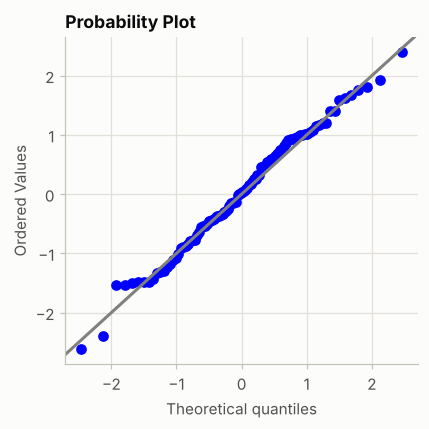

In [25]:
# BOOK CODE (Standard Normal and QQ-Plots): the QQ-plot of a sample of 100 standard normal values
np.random.seed(2024)  # NOT IN THE BOOK: the book's sample has no seed

fig, ax = plt.subplots(figsize=(4, 4))

norm_sample = stats.norm.rvs(size=100)
# Use fit=False to disable the default fitting of a line to the sample data (least-squares regression).
stats.probplot(norm_sample, plot=ax, fit=False)
# Plot the diagonal representing the standardized normal distribution.
ax.axline((0, 0), (1, 1), color='grey')

plt.tight_layout()
plt.show()

**Output analysis.**

* The points lie close to the grey diagonal, as they should for 100 values of the standard normal distribution, which the diagonal ($y = x$) describes exactly because the data are already standardized.
* There is some wobble: the two lowest values lie below the line, and a group of five or six values of about $-1.5$ forms a flat run; this is chance. A sample of 100 values is never perfectly on the line, and a QQ-plot is read for a systematic curve, not for individual points.
* The title "Probability Plot" and the axis labels come from `scipy.stats.probplot`; the figure of the book has its own.

### Extra experiments

**(a) The 68-95-99.7 rule, and the rule for skewed data.** The cell computes $P(|Z|<k)$ from the distribution function, checks it with one million simulated standard normal values, and compares it with the share of the 50,000 loan incomes that lie within $k$ standard deviations of their own mean.

In [26]:
# EXTRA (a): the share of the values within k standard deviations of the mean
rng = np.random.default_rng(31)
simulated = rng.normal(size=1_000_000)
income = loans_income.to_numpy(float)
z_income = (income - income.mean()) / income.std()
rows = []
for k in (1, 1.645, 1.96, 2, 2.576, 3):
    rows.append({"k": k, "exact 2 Phi(k) - 1": 2 * stats.norm.cdf(k) - 1, "simulated normal": np.mean(np.abs(simulated) < k), "loan incomes": np.mean(np.abs(z_income) < k)})
print(pd.DataFrame(rows).round(4).to_string(index=False))
print(f"\nskewness of the incomes {stats.skew(income):.2f}; largest z-score {z_income.max():.2f}, smallest {z_income.min():.2f}")
print(f"incomes with a z-score above 3: {(z_income > 3).sum()}; below -3: {(z_income < -3).sum()}; a normal sample of 50,000 would have about {50_000 * stats.norm.sf(3):.0f} on each side")

    k  exact 2 Phi(k) - 1  simulated normal  loan incomes
1.000              0.6827            0.6821        0.7269
1.645              0.9000            0.8998        0.9225
1.960              0.9500            0.9500        0.9494
2.000              0.9545            0.9546        0.9500
2.576              0.9900            0.9901        0.9766
3.000              0.9973            0.9973        0.9866

skewness of the incomes 1.05; largest z-score 3.96, smallest -1.97
incomes with a z-score above 3: 669; below -3: 0; a normal sample of 50,000 would have about 67 on each side


**Analysis of extra (a).**

* The exact shares within $k$ standard deviations of the mean are 68.27%, 90.00%, 95.00%, 95.45%, 99.00% and 99.73% for $k = 1, 1.645, 1.96, 2, 2.576, 3$, and one million simulated values agree to four decimals.
* The loan incomes (skewness 1.05) do not follow the rule: 72.7% are within one standard deviation (68.3% for a normal variable), 95.0% within 1.96 and 98.7% within 3 (99.7% for the normal), more in the centre and more beyond three standard deviations. 669 incomes (1.3%) have a $z$-score above 3 and none is below $-3$, because the incomes cannot fall far below the mean (the smallest $z$-score is $-1.97$); a normal sample of 50,000 would have about 67 on each side.
* A skewed variable puts all its extreme values on one side. The percentages of the rule are a property of the normal distribution and should not be used for data without checking.

**(b) A QQ-plot built by hand.** The cell builds the points of the QQ-plot of the book's sample from the definition, with the plotting positions of Filliben that `scipy` uses, and compares them with the points that `probplot` returns. It also shows how much the other plotting positions differ.

In [27]:
# EXTRA (b): the QQ-plot points from the definition
(theoretical, ordered) = stats.probplot(norm_sample, fit=False)       # what scipy computes
n = len(norm_sample)
i = np.arange(1, n + 1)
filliben = (i - 0.3175) / (n + 0.365)
filliben[-1] = 0.5 ** (1 / n)                                         # the first and the last positions are special cases
filliben[0] = 1 - filliben[-1]
by_hand = stats.norm.ppf(filliben)
print(f"largest difference between my quantiles and those of scipy: {np.max(np.abs(by_hand - theoretical)):.2e}")
print(f"the plotted values are the sorted data: {np.array_equal(ordered, np.sort(norm_sample))}")

positions = {"Filliben (scipy)": filliben, "(i - 0.5) / n": (i - 0.5) / n, "i / (n + 1)": i / (n + 1), "(i - 3/8) / (n + 1/4)": (i - 3 / 8) / (n + 1 / 4)}
rows = []
for name, p in positions.items():
    q = stats.norm.ppf(p)
    rows.append({"plotting position": name, "smallest quantile": q[0], "largest quantile": q[-1], "largest difference from scipy": np.max(np.abs(q - theoretical)),
                 "difference in the middle 80%": np.max(np.abs(q - theoretical)[10:-10])})
print(pd.DataFrame(rows).round(4).to_string(index=False))

largest difference between my quantiles and those of scipy: 0.00e+00
the plotted values are the sorted data: True
    plotting position  smallest quantile  largest quantile  largest difference from scipy  difference in the middle 80%
     Filliben (scipy)            -2.4620            2.4620                         0.0000                        0.0000
        (i - 0.5) / n            -2.5758            2.5758                         0.1138                        0.0079
          i / (n + 1)            -2.3301            2.3301                         0.1320                        0.0134
(i - 3/8) / (n + 1/4)            -2.4986            2.4986                         0.0366                        0.0025


**Analysis of extra (b).**

* The positions of Filliben, computed from the definition, give exactly the quantiles that `scipy` plots (largest difference 0), and the plotted values are the sorted data.
* The other conventions give the same middle of the plot (differences below 0.014 in the middle 80% of the points) and differ at the ends: the smallest and the largest quantile are $\pm 2.576$ for $(i - 0.5)/n$, $\pm 2.330$ for $i/(n+1)$, $\pm 2.499$ for $(i - 3/8)/(n + 1/4)$ and $\pm 2.462$ for Filliben, so the extreme points move by 0.04 to 0.13 depending on the convention.
* The choice of plotting position matters only for the first and the last few points, and these are exactly the points that are read for evidence of long tails; a reading that depends on 0.1 in the extreme quantile is not strong evidence.

**(c) How different shapes look in a QQ-plot.** Six samples of 300 values are drawn: normal, uniform (light tails), $t$ with 3 degrees of freedom (heavy tails), exponential (skewed to the right), the negative of an exponential (skewed to the left) and a mixture of two normal distributions (two modes). Each is standardized and plotted against the standard normal quantiles, with the diagonal. The table gives the skewness, the excess kurtosis and the p-value of the Shapiro-Wilk test.

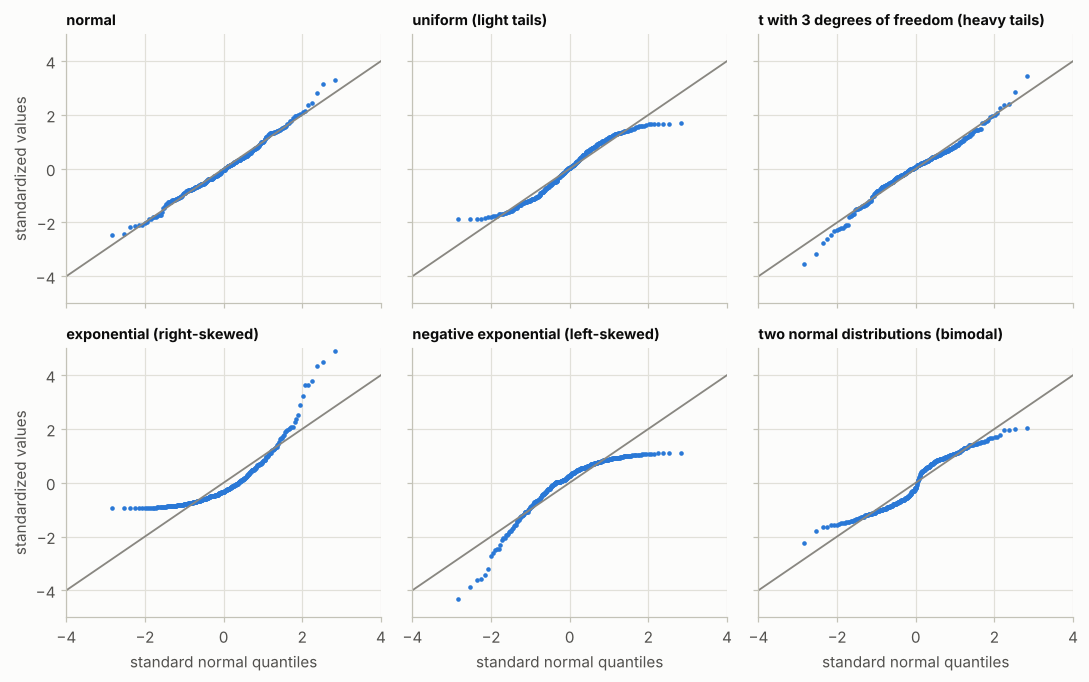

                                   sample  skewness  excess kurtosis  Shapiro-Wilk p-value
                                   normal     0.273            0.242                 0.105
                    uniform (light tails)    -0.105           -1.129                 0.000
t with 3 degrees of freedom (heavy tails)    -0.279            1.077                 0.001
               exponential (right-skewed)     2.027            5.094                 0.000
       negative exponential (left-skewed)    -1.549            2.628                 0.000
       two normal distributions (bimodal)     0.080           -1.314                 0.000


In [28]:
# EXTRA (c): a gallery of QQ-plots of standardized samples
rng = np.random.default_rng(32)
n = 300
samples = {
    "normal": rng.normal(size=n),
    "uniform (light tails)": rng.random(n),
    "t with 3 degrees of freedom (heavy tails)": rng.standard_t(3, size=n),
    "exponential (right-skewed)": rng.exponential(size=n),
    "negative exponential (left-skewed)": -rng.exponential(size=n),
    "two normal distributions (bimodal)": np.where(rng.random(n) < 0.5, rng.normal(-2, 1, n), rng.normal(2, 1, n)),
}
rows = []
fig, axes = plt.subplots(2, 3, figsize=(10, 6.3), sharex=True, sharey=True)
for ax, (name, x) in zip(axes.ravel(), samples.items()):
    z = (x - x.mean()) / x.std(ddof=1)
    q, ordered = stats.probplot(z, fit=False)
    ax.plot(q, ordered, ".", color=PALETTE[0], ms=4)
    ax.axline((0, 0), (1, 1), color=MUTED, lw=1.2)
    ax.set_title(name, fontsize=9.5)
    ax.set_xlim(-4, 4); ax.set_ylim(-5, 5)
    rows.append({"sample": name, "skewness": stats.skew(x), "excess kurtosis": stats.kurtosis(x), "Shapiro-Wilk p-value": stats.shapiro(x).pvalue})
for ax in axes[1]:
    ax.set_xlabel("standard normal quantiles")
for ax in axes[:, 0]:
    ax.set_ylabel("standardized values")
plt.tight_layout()
plt.show()
print(pd.DataFrame(rows).round(3).to_string(index=False))

**Analysis of extra (c).**

* **Normal.** The points follow the diagonal (skewness 0.27, excess kurtosis 0.24 by chance; Shapiro-Wilk p = 0.105, no rejection).
* **Uniform (light tails).** An S that is flat at both ends: the lowest points lie above the diagonal and the highest below, because a uniform sample has no values beyond $\pm 1.73$ standard deviations; excess kurtosis $-1.13$.
* **$t$ with 3 degrees of freedom (heavy tails).** The opposite S: the lowest points below the diagonal and the highest above it; with 300 values the effect is visible but modest (excess kurtosis 1.08), and the Shapiro-Wilk test rejects (p = 0.001).
* **Exponential (right-skewed).** A strongly convex curve: the lower end is flat (the values cannot be below 0) and the upper end rises steeply (skewness 2.03). **The negative exponential** is its mirror image, concave.
* **Mixture of two normal distributions.** A step in the middle, where there are few values between the two modes, and flat runs at the two modes (excess kurtosis $-1.31$).
* The Shapiro-Wilk test rejects normality for all five departures (p at most 0.001) and does not reject for the normal sample, but it only says "not normal". The QQ-plot says *how*: light or heavy tails, skew, or two groups.

---
## 7. Long-tailed distributions

*Book section: "Long-Tailed Distributions". The code of the script draws a QQ-plot for the daily series of the stock Netflix (`NFLX`).*

### Summary

* Real data are often **long-tailed**: values far from the centre occur much more often than the normal distribution allows. The **tail** is the long, narrow part of a frequency distribution where the extreme values lie; a **skewed** distribution has a longer tail on one side.
* In a QQ-plot of standardized data, a long-tailed distribution shows as an S: the points at the low end lie below the diagonal and the points at the high end above it. The data have more extreme values than a normal sample of the same size would.
* The consequence is practical. If extreme events are assumed to be as rare as the normal distribution says, their probability is greatly underestimated, which is the risk behind the "black swan" events of finance. Even when the data are long-tailed, the *means* of large samples are close to normal, so the formulas for means (section 3) can still be used; what must not be done is to treat the data themselves as normal.
* The script computes, from the column `NFLX`, a series that it plots in a QQ-plot against the standard normal distribution; the point of the figure is the S shape.

### Theory

**What makes a tail "long".** A distribution is *light-tailed* if its tail probabilities decrease at least as fast as an exponential, like the normal ($P(|Z| > x) \approx e^{-x^2/2}$), and *heavy-tailed* if they decrease more slowly, for instance like a power: for Student's $t$ with $\nu$ degrees of freedom $P(|T| > x) \sim x^{-\nu}$. The **excess kurtosis** $\kappa = E\bigl[(X-\mu)^4\bigr]/\sigma^4 - 3$ summarizes the weight of the tails (it is 0 for the normal distribution, $6/(\nu - 4)$ for $t_\nu$ with $\nu > 4$, 3 for the Laplace distribution, 6 for the exponential). It is a number built on fourth powers, and so is itself very sensitive to a few extreme values.

**Moments need not exist.** A power-law tail with exponent $\nu$ has finite moments only below the order $\nu$: the $t$ distribution with $\nu = 1$ (the **Cauchy** distribution) has no mean, and with $\nu = 2$ no variance. For such data the central limit theorem does not apply: the mean of $n$ Cauchy values has *exactly the same distribution* as a single value, so averaging does not help (extra 7(c)). For $1 < \nu \le 2$ the mean exists but the sample mean converges slowly and its standard error cannot be estimated from the sample standard deviation.

**Stock changes.** The daily changes of stock prices have heavier tails than the normal distribution, and their variance is not constant: calm periods alternate with turbulent ones (volatility clustering). A normal model fitted to such data underestimates the probability of a large move by orders of magnitude (extra 7(b)).

**What the data of the book contain.** The file `sp500_data.csv.gz` holds, for 517 symbols, the daily **change of the price** (positive, zero and negative values, as the first chapter shows), not the price itself. A zero is also used for the days before a stock was listed. These facts matter for the code of the script, as extra 7(a) shows.

### Book code

The script reads the data, takes the column `NFLX`, keeps the positive values, takes their logarithm and then the differences, and draws a QQ-plot of the result. The notebook reads the file with the book's call, `pd.read_csv` without `index_col`, so the dates form the first column (`Unnamed: 0`).

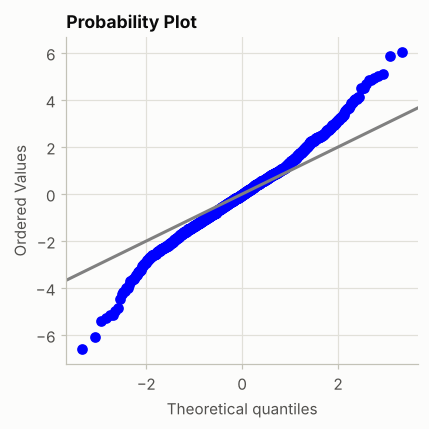

In [29]:
# BOOK CODE (Long-Tailed Distributions): the QQ-plot of the series derived from NFLX
sp500_px = pd.read_csv(SP500_DATA_CSV)

nflx = sp500_px.NFLX
nflx = np.diff(np.log(nflx[nflx>0]))

fig, ax = plt.subplots(figsize=(4, 4))
# Use fit=False to disable the default fitting of a line to the sample data (least-squares regression).
stats.probplot(nflx, plot=ax, fit=False)
# Plot the diagonal representing the standardized normal distribution.
ax.axline((0, 0), (1, 1), color='grey')

plt.tight_layout()
plt.show()

**Output analysis.**

* The points make an S: the lowest values (down to about $-6.6$, at quantiles near $-3.3$) lie far below the diagonal and the highest (about 6.0) far above it, while the middle of the cloud is flatter than the diagonal. This is the shape of a long-tailed distribution, with more extreme values than a normal sample has and a more concentrated centre.
* The diagonal $y = x$ is the right reference only for standardized data. The series of the script has a standard deviation of 1.49 (extra 7(a)); a normal sample with that standard deviation would lie along a line of slope 1.49, not 1. The conclusion "S-shaped, so long tails" holds (the excess kurtosis of the series is 1.2), but the diagonal is not an exact reference.
* More important: what is plotted is not a series of returns of the stock. Extra 7(a) shows what the code does to the column.

### Extra experiments

**(a) What does the book's code compute?** The cell inspects the column `NFLX` (how many values are zero, positive and negative, where the zeros are, the range of the values) and the series that the script builds from it.

In [30]:
# EXTRA (a): what the book's transformation of the column NFLX does
column = sp500_px["NFLX"]
first_change = np.flatnonzero(column.to_numpy() != 0)[0]
print(f"{len(column):,} rows, dates {sp500_px.iloc[0, 0]} to {sp500_px.iloc[-1, 0]}")
print(f"values: {int((column > 0).sum())} positive, {int((column == 0).sum())} zero, {int((column < 0).sum())} negative; minimum {column.min():.2f}, maximum {column.max():.2f}")
print(f"the first non-zero value is on row {first_change} ({sp500_px.iloc[first_change, 0]}); all {first_change} values before it are zero: {bool((column.iloc[:first_change] == 0).all())}; "
      f"after it there are {int((column.iloc[first_change:] == 0).sum())} zeros among {len(column) - first_change}")
print(f"\nthe series of the script: {len(nflx):,} values (the logarithm of the {int((column > 0).sum())} positive values, differenced); "
      f"mean {nflx.mean():.3f}, standard deviation {nflx.std(ddof=1):.3f}, minimum {nflx.min():.2f}, maximum {nflx.max():.2f}")
print(f"skewness {stats.skew(nflx):.3f}, excess kurtosis {stats.kurtosis(nflx):.3f}; the first five values: {np.round(nflx[:5], 3).tolist()}")

5,647 rows, dates 1993-01-29 to 2015-07-01
values: 1613 positive, 2363 zero, 1671 negative; minimum -9.33, maximum 4.29
the first non-zero value is on row 2347 (2002-05-23); all 2347 values before it are zero: True; after it there are 16 zeros among 3300

the series of the script: 1,612 values (the logarithm of the 1613 positive values, differenced); mean 0.002, standard deviation 1.489, minimum -6.61, maximum 6.04
skewness 0.074, excess kurtosis 1.225; the first five values: [0.194, -0.288, -0.125, -0.405, 0.624]


**Analysis of extra (a).**

* **The column holds changes, not prices.** It has 1,613 positive values, 1,671 negative ones and 2,363 zeros, with a minimum of $-9.33$ and a maximum of 4.29. A price is never negative or zero; these are daily changes of a price. The 2,347 zeros come before 2002-05-23, which matches the stock's flotation in May 2002: the file seems to fill the days before the first trading with zeros. After that date only 16 of 3,300 days are zero.
* **What the script computes.** `nflx[nflx>0]` keeps only the 1,613 *positive* changes (29% of the rows), `np.log` takes their logarithms, and `np.diff` subtracts consecutive ones. The result has 1,612 values, with mean 0.002, standard deviation 1.49, minimum $-6.61$, maximum 6.04, skewness 0.07 and excess kurtosis 1.2. These numbers are differences of the logarithms of the sizes of *rises*, taken between rises that are not on consecutive days. They are not returns of the stock and do not describe how it behaves.
* The transformation `diff(log(price))` is the log return of a *price series*; applied to a column of price changes it measures something else. The figure of the book still illustrates the S shape of a long-tailed variable, but it should not be read as a statement about stock returns.
* Extras 7(b) and 7(d) use the price changes themselves, which is what the column contains.

**(b) The tails of daily price changes, and a normal model.** The daily price changes of the exchange-traded fund `SPY` (a fund on the S&P 500 index) from July 2012 to July 2015 are standardized. The cell counts the days beyond 3 and 4 standard deviations and compares them with the normal distribution, fits a normal and a Student $t$ distribution by maximum likelihood, and draws the QQ-plots against both.

754 days; mean 0.034, standard deviation 1.018 price units; skewness -0.51, excess kurtosis 1.57; largest |z| = 3.96
threshold  days  share of the days  normal model  expected days (normal)
  |z| > 2    49             0.0650        0.0455                 34.3072
  |z| > 3    10             0.0133        0.0027                  2.0356
  |z| > 4     0             0.0000        0.0001                  0.0478
probability of a day beyond 4.0 standard deviations under a normal model: 7.6e-05 (one day in 13,183)

t model fitted by maximum likelihood: 3.94 degrees of freedom, location 0.096, scale 0.750
log-likelihood: normal -1082.6, t -1054.4 (the t model has one parameter more)
expected days beyond 4 sample standard deviations: normal 0.05, fitted t 4.40; observed 0


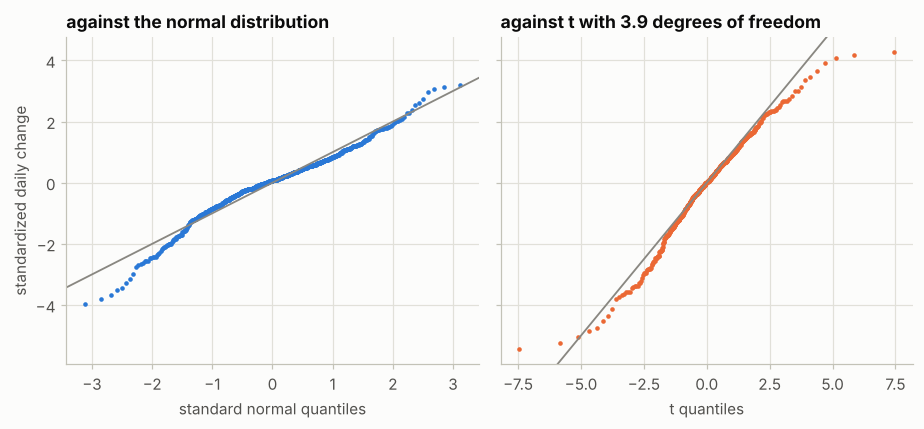

In [31]:
# EXTRA (b): tails of the daily changes of SPY, July 2012 to July 2015, against a normal and a t model
sp500_dates = pd.read_csv(SP500_DATA_CSV, index_col=0)
spy = sp500_dates.loc[sp500_dates.index > "2012-07-01", "SPY"].to_numpy()
z = (spy - spy.mean()) / spy.std(ddof=1)
n = len(spy)
rows = []
for k in (2, 3, 4):
    rows.append({"threshold": f"|z| > {k}", "days": int(np.sum(np.abs(z) > k)), "share of the days": np.mean(np.abs(z) > k),
                 "normal model": 2 * stats.norm.sf(k), "expected days (normal)": n * 2 * stats.norm.sf(k)})
print(f"{n} days; mean {spy.mean():.3f}, standard deviation {spy.std(ddof=1):.3f} price units; skewness {stats.skew(spy):.2f}, excess kurtosis {stats.kurtosis(spy):.2f}; largest |z| = {np.abs(z).max():.2f}")
print(pd.DataFrame(rows).round(4).to_string(index=False))
print(f"probability of a day beyond {np.abs(z).max():.1f} standard deviations under a normal model: {2 * stats.norm.sf(np.abs(z).max()):.1e} (one day in {1 / (2 * stats.norm.sf(np.abs(z).max())):,.0f})")

nu, loc, scale = stats.t.fit(spy)
ll_normal = stats.norm.logpdf(spy, spy.mean(), spy.std()).sum()
ll_t = stats.t.logpdf(spy, nu, loc, scale).sum()
print(f"\nt model fitted by maximum likelihood: {nu:.2f} degrees of freedom, location {loc:.3f}, scale {scale:.3f}")
print(f"log-likelihood: normal {ll_normal:.1f}, t {ll_t:.1f} (the t model has one parameter more)")
print(f"expected days beyond 4 sample standard deviations: normal {n * 2 * stats.norm.sf(4):.2f}, fitted t {n * 2 * stats.t.sf(4 * spy.std(ddof=1) / scale, nu):.2f}; observed {int(np.sum(np.abs(z) > 4))}")

fig, axes = plt.subplots(1, 2, figsize=(8.5, 4), sharey=True)
q, ordered = stats.probplot(z, fit=False)
axes[0].plot(q, ordered, ".", color=PALETTE[0], ms=4)
axes[0].axline((0, 0), (1, 1), color=MUTED, lw=1.2)
axes[0].set_title("against the normal distribution")
axes[0].set_xlabel("standard normal quantiles"); axes[0].set_ylabel("standardized daily change")
q, ordered = stats.probplot((spy - loc) / scale, dist=stats.t, sparams=(nu,), fit=False)
axes[1].plot(q, ordered, ".", color=PALETTE[1], ms=4)
axes[1].axline((0, 0), (1, 1), color=MUTED, lw=1.2)
axes[1].set_title(f"against t with {nu:.1f} degrees of freedom")
axes[1].set_xlabel("t quantiles")
plt.tight_layout()
plt.show()

**Analysis of extra (b).**

* **Days beyond 2, 3 and 4 standard deviations.** For the 754 days of the fund `SPY` the daily price changes have a standard deviation of 1.018 price units, skewness $-0.51$ and excess kurtosis 1.57. There are 49 days beyond 2 standard deviations (34 expected under the normal model), 10 beyond 3 (2.0 expected: five times as many) and none beyond 4 (0.05 expected; the largest $|z|$ is 3.96).
* **A normal and a $t$ model.** Fitted by maximum likelihood, the $t$ distribution has 3.94 degrees of freedom and a log-likelihood of $-1054.4$, against $-1082.6$ for the normal: it fits better by 28 units of log-likelihood for one more parameter. The QQ-plot against the normal distribution shows the S shape (the lowest points of about $-3.9$ lie below the line); against the $t$ distribution the middle follows the diagonal.
* **The far tail is not determined by 754 days.** The fitted $t$ expects 4.4 days beyond 4 sample standard deviations, the normal model 0.05, and none was observed. In the QQ-plot against $t$ the highest points fall below the diagonal: the $t$ model with these degrees of freedom overstates the extreme tail of this series. Between the two models the truth is somewhere, and the data of three years cannot say where.
* So: a normal model underestimates the frequency of the 3-standard-deviation days of this fund by a factor of 5; for the days beyond 4 the answer depends on the model.

**(c) A mean that does not converge.** Samples of up to 100,000 values are drawn from the normal distribution, from $t$ with 3 degrees of freedom and from the Cauchy distribution. For 1,000 independent sequences of each kind, the cell reports the width of the interval that contains the middle 50% of the sample means at several sample sizes. The figure shows the running mean of five sequences of each kind.

width of the interval holding the middle 50% of 1,000 sample means
           distribution  n = 10  n = 100  n = 1,000  n = 10,000  n = 100,000
                 normal   0.401    0.140      0.043       0.014        0.004
t, 3 degrees of freedom   0.639    0.233      0.072       0.022        0.007
                 Cauchy   2.163    2.174      2.026       2.106        2.045


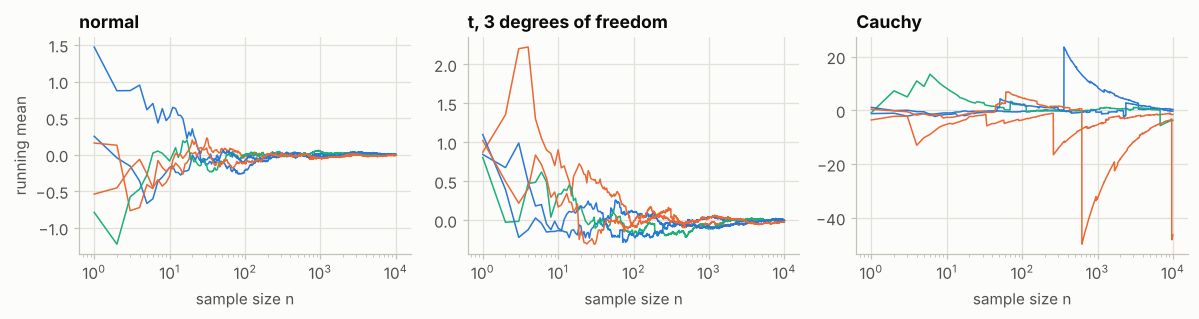

In [32]:
# EXTRA (c): sample means of normal, t(3) and Cauchy samples
rng = np.random.default_rng(33)
checkpoints = [10, 100, 1000, 10_000, 100_000]
draws = {"normal": lambda size: rng.normal(size=size), "t, 3 degrees of freedom": lambda size: rng.standard_t(3, size=size), "Cauchy": lambda size: rng.standard_cauchy(size=size)}
rows = []
for name, draw in draws.items():
    means = np.empty((1000, len(checkpoints)))
    for j, n in enumerate(checkpoints):
        means[:, j] = draw((1000, n)).mean(axis=1) if n <= 10_000 else np.mean([draw((1000, 10_000)).mean(axis=1) for _ in range(10)], axis=0)
    iqr = np.subtract(*np.percentile(means, [75, 25], axis=0))
    rows.append({"distribution": name, **{f"n = {n:,}": v for n, v in zip(checkpoints, iqr)}})
print("width of the interval holding the middle 50% of 1,000 sample means")
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharex=True)
steps = np.arange(1, 10_001)
for ax, (name, draw) in zip(axes, draws.items()):
    for _ in range(5):
        ax.plot(steps, np.cumsum(draw(10_000)) / steps, lw=1)
    ax.set_xscale("log")
    ax.set_title(name)
    ax.set_xlabel("sample size n")
axes[0].set_ylabel("running mean")
plt.tight_layout()
plt.show()

**Analysis of extra (c).**

* **Normal and $t$ with 3 degrees of freedom.** The width of the middle 50% of the sample means falls as $1/\sqrt{n}$: for the normal distribution from 0.401 ($n = 10$) to 0.140, 0.043, 0.014 and 0.004; for $t_3$, which has a finite variance, from 0.639 to 0.233, 0.072, 0.022 and 0.007, larger by a factor of 1.6 but with the same rate.
* **Cauchy.** The width does not shrink: 2.163, 2.174, 2.026, 2.106, 2.045, which is the width of the middle 50% of *one* Cauchy value (exactly 2). The mean of 100,000 values is as variable as a single value.
* The running means in the figure show it: those of the normal and the $t_3$ samples settle down to 0, those of the Cauchy samples keep jumping (by tens of units) whenever an extreme value arrives, even after thousands of observations.
* For data with infinite variance the central limit theorem does not apply and a mean is not a stable summary. Real data are rarely this extreme, but the experiment shows what "heavy tails" can mean in the limit.

**(d) Long tails in many stocks.** For the 511 stocks and funds of the file that were traded throughout the same three years (July 2012 to July 2015), the cell standardizes the daily changes of each and reports the distribution of the excess kurtosis and the share of days beyond 3 and 4 standard deviations, next to the values of the normal distribution.

In [33]:
# EXTRA (d): excess kurtosis and extreme days of the daily changes of the 511 stocks over three years
window = sp500_dates.loc[sp500_dates.index > "2012-07-01"]
rows = []
for symbol in window.columns:
    y = window[symbol]
    if (y == 0).mean() > 0.5 or y.std() == 0:
        continue                                   # a column that is mostly zero is not a traded series in this window
    z_stock = (y - y.mean()) / y.std(ddof=1)
    rows.append({"symbol": symbol, "excess kurtosis": stats.kurtosis(y), "skewness": stats.skew(y), "beyond 3": (z_stock.abs() > 3).mean(), "beyond 4": (z_stock.abs() > 4).mean()})
survey = pd.DataFrame(rows).set_index("symbol")
print(f"{len(survey)} series of {len(window.columns)} columns, {len(window)} days each")
print(survey.describe().loc[["mean", "min", "25%", "50%", "75%", "max"]].round(4).to_string())
print(f"\nshare of the series with an excess kurtosis above 1: {(survey['excess kurtosis'] > 1).mean():.0%}; above 3: {(survey['excess kurtosis'] > 3).mean():.0%}")
print(f"normal distribution: beyond 3 = {2 * stats.norm.sf(3):.4f}, beyond 4 = {2 * stats.norm.sf(4):.6f}")
print(f"mean share of days beyond 4 standard deviations is {survey['beyond 4'].mean() / (2 * stats.norm.sf(4)):.0f} times the normal value")

511 series of 517 columns, 754 days each
      excess kurtosis  skewness  beyond 3  beyond 4
mean           4.7014   -0.0506    0.0113    0.0030
min            0.3194   -4.5310    0.0027    0.0000
25%            1.4857   -0.3129    0.0093    0.0013
50%            2.3200   -0.1310    0.0119    0.0027
75%            3.8464    0.0709    0.0133    0.0040
max          132.0053    7.3917    0.0279    0.0106

share of the series with an excess kurtosis above 1: 91%; above 3: 36%
normal distribution: beyond 3 = 0.0027, beyond 4 = 0.000063
mean share of days beyond 4 standard deviations is 47 times the normal value


**Analysis of extra (d).**

* **Kurtosis.** Of the 511 series, 91% have an excess kurtosis above 1 and 36% above 3, against 0 for a normal distribution. The median is 2.32 (the middle half between 1.49 and 3.85) and the mean 4.70, pulled up by a few extreme series (the largest is 132).
* **Extreme days.** The median share of days beyond 3 standard deviations is 1.19%, 4.4 times the 0.27% of the normal distribution. The mean share beyond 4 is 0.30%, 47 times the 0.0063% of the normal distribution. A fund or a stock that moves by more than 4 standard deviations about once in 330 days would do so about once in 16,000 days if it were normal.
* **Skewness** is slightly negative on the whole (median $-0.13$), with large values in both directions for a few series.
* A caution: these are price changes in the units of the price and not returns, so a series whose price level changed a lot over the three years has a changing scale, which inflates the kurtosis; the effect is modest over three years for most series. The conclusion, that the daily changes of stocks have heavier tails than a normal distribution, is the same as in the literature on returns.

---
## 8. Student's $t$-distribution

*Book section: "Student's t-Distribution". The section has no code.*

### Summary

* The **$t$-distribution** is a family of bell-shaped distributions, similar to the normal but a little flatter and with thicker tails, whose shape depends on the **degrees of freedom**, which for a sample of $n$ values are $n-1$. With more degrees of freedom the $t$-distribution approaches the normal distribution; with $n$ in the dozens the two are close.
* It was introduced to describe the distribution of a sample mean that has been standardized with the *estimated* standard deviation of a *small* sample: the quantity $(\bar x - \mu)/(s/\sqrt{n})$.
* It is the distribution behind the classical confidence intervals and tests of means, and it is the one that statistical software uses for coefficients in regression output. The chapter's point is that it is a tool that data scientists meet in software output; with the bootstrap and with large samples they rarely have to compute with it by hand.

### Theory

**Definition.** If $Z \sim N(0,1)$ and $V \sim \chi^2_\nu$ are independent (section 10), then
$$T = \frac{Z}{\sqrt{V/\nu}} \sim t_\nu .$$
For a sample $X_1, \dots, X_n$ from a normal population, $\bar X$ and $s^2$ are independent, $\sqrt{n}(\bar X - \mu)/\sigma \sim N(0, 1)$ and $(n-1)s^2/\sigma^2 \sim \chi^2_{n-1}$, so that $T = (\bar X - \mu)/(s/\sqrt{n})$ has exactly the $t_{n-1}$ distribution. The sampling error of $s$ makes the denominator random, which is where the heavier tails come from: a sample that happens to have a small $s$ makes the statistic large.

**Properties.** The distribution is symmetric about 0. Its variance is $\nu/(\nu - 2)$ for $\nu > 2$ (larger than 1), it is the Cauchy distribution for $\nu = 1$, and $t_\nu \to N(0,1)$ as $\nu \to \infty$. Tail probabilities are polynomial, $P(|T| > x) \sim x^{-\nu}$ (section 7). The quantile $t_{\nu, 0.975}$ is 12.71 for $\nu = 1$, 2.78 for $\nu = 4$, 2.09 for $\nu = 19$, and approaches 1.96.

**The interval for a mean** is $\bar X \pm t_{n-1, 1-\alpha/2}\, s/\sqrt{n}$ (section 5). It has exact coverage $1-\alpha$ if the data are normal, and is approximate otherwise. The name comes from the pseudonym "Student" of W. S. Gosset, who derived the distribution for small samples in 1908 (Student, 1908).

### Extra experiments

This section has no code in the book. The experiments below compare the $t$-distribution with the normal one.

**(a) Quantiles.** The cell lists the two-sided 90%, 95% and 99% quantiles of $t_\nu$ for several $\nu$, next to those of the normal distribution, and draws the densities of $t_1$, $t_3$ and $t_{10}$ against the normal density.

two-sided quantiles t(df, 1 - alpha/2) for the levels 90%, 95% and 99%
degrees of freedom   90%    95%    99%
                 1 6.314 12.706 63.657
                 2 2.920  4.303  9.925
                 3 2.353  3.182  5.841
                 5 2.015  2.571  4.032
                10 1.812  2.228  3.169
                20 1.725  2.086  2.845
                30 1.697  2.042  2.750
                60 1.671  2.000  2.660
               120 1.658  1.980  2.617
              1000 1.646  1.962  2.581
            normal 1.645  1.960  2.576

variance of t(df) = df / (df - 2): df = 3: 3.00, df = 5: 1.67, df = 10: 1.25, df = 30: 1.071


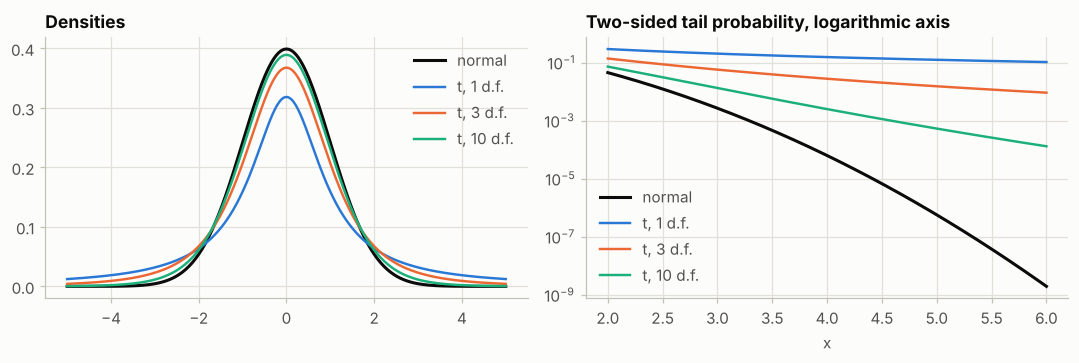

In [34]:
# EXTRA (a): quantiles of the t-distribution against the normal distribution
dfs = [1, 2, 3, 5, 10, 20, 30, 60, 120, 1000]
rows = [{"degrees of freedom": df, **{f"{lv:.0%}": stats.t.ppf(1 - (1 - lv) / 2, df) for lv in (0.90, 0.95, 0.99)}} for df in dfs]
rows.append({"degrees of freedom": "normal", **{f"{lv:.0%}": stats.norm.ppf(1 - (1 - lv) / 2) for lv in (0.90, 0.95, 0.99)}})
print("two-sided quantiles t(df, 1 - alpha/2) for the levels 90%, 95% and 99%")
print(pd.DataFrame(rows).round(3).to_string(index=False))
print(f"\nvariance of t(df) = df / (df - 2): df = 3: {3 / 1:.2f}, df = 5: {5 / 3:.2f}, df = 10: {10 / 8:.2f}, df = 30: {30 / 28:.3f}")

grid = np.linspace(-5, 5, 400)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(grid, stats.norm.pdf(grid), color=INK, lw=2, label="normal")
for df, color in zip((1, 3, 10), PALETTE):
    axes[0].plot(grid, stats.t.pdf(grid, df), color=color, lw=1.6, label=f"t, {df} d.f.")
axes[0].set_title("Densities"); axes[0].legend()
tail = np.linspace(2, 6, 200)
axes[1].semilogy(tail, 2 * stats.norm.sf(tail), color=INK, lw=2, label="normal")
for df, color in zip((1, 3, 10), PALETTE):
    axes[1].semilogy(tail, 2 * stats.t.sf(tail, df), color=color, lw=1.6, label=f"t, {df} d.f.")
axes[1].set_title("Two-sided tail probability, logarithmic axis"); axes[1].set_xlabel("x"); axes[1].legend()
plt.tight_layout()
plt.show()

**Analysis of extra (a).**

* The 95% two-sided multiplier is 12.71 for 1 degree of freedom, 4.30 for 2, 3.18 for 3, 2.57 for 5, 2.23 for 10, 2.09 for 20, 2.04 for 30, 2.00 for 60 and 1.96 for 1,000. At 30 degrees of freedom it is still 4% above the normal one, at 10 it is 14% above and at 5 it is 31% above. For the 99% level the multipliers are 63.7 for 1 degree of freedom and 2.58 for 1,000.
* The variance of $t_\nu$ is $\nu/(\nu-2)$: 3.00 for 3 degrees of freedom, 1.67 for 5, 1.25 for 10 and 1.07 for 30.
* The densities in the left panel are close in the centre and differ in the tails; on the logarithmic scale on the right the difference is large: the normal tail probability drops by orders of magnitude between 2 and 6, while those of the $t$ distributions with 1 and 3 degrees of freedom decay slowly, and even $t_{10}$ keeps a probability of about $10^{-4}$ at 6, where the normal has $2 \times 10^{-9}$.

**(b) Why the standardized mean has heavy tails.** Samples of $n = 5$ values are drawn from a normal population (200,000 of them). The cell standardizes each sample mean twice: with the true $\sigma$ (which gives a standard normal variable) and with the sample's own $s$ (which gives $t_4$), and compares the probability of exceeding $\pm 1.96$ and $\pm 3$ in the two cases.

    threshold  sigma known (normal)  normal, exact  s estimated  t with 4 d.f., exact
|stat| > 1.96                0.0490         0.0500       0.1210                0.1216
   |stat| > 3                0.0028         0.0027       0.0395                0.0399
standard deviation of the statistics: with sigma 0.999, with s 1.413 (theory sqrt(4 / 2) = 1.414)
Kolmogorov-Smirnov distance to t with 4 d.f.: 0.0029; to the standard normal: 0.0375


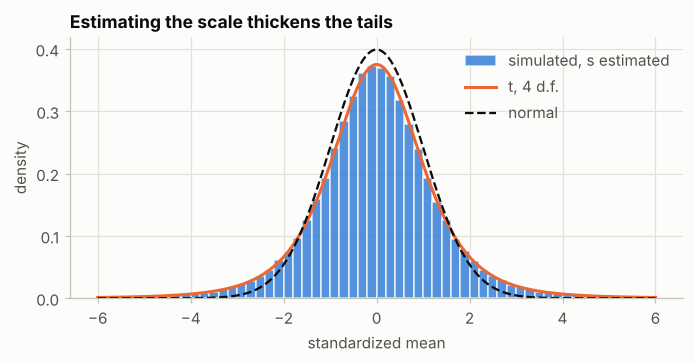

In [35]:
# EXTRA (b): the mean standardized with the true sigma and with the estimated s, samples of 5 from a normal population
rng = np.random.default_rng(41)
n, repetitions = 5, 200_000
x = rng.normal(loc=10, scale=2, size=(repetitions, n))
z_stat = (x.mean(axis=1) - 10) / (2 / np.sqrt(n))
t_stat = (x.mean(axis=1) - 10) / (x.std(axis=1, ddof=1) / np.sqrt(n))
rows = []
for k in (1.96, 3):
    rows.append({"threshold": f"|stat| > {k}", "sigma known (normal)": np.mean(np.abs(z_stat) > k), "normal, exact": 2 * stats.norm.sf(k),
                 "s estimated": np.mean(np.abs(t_stat) > k), "t with 4 d.f., exact": 2 * stats.t.sf(k, n - 1)})
print(pd.DataFrame(rows).round(4).to_string(index=False))
print(f"standard deviation of the statistics: with sigma {z_stat.std():.3f}, with s {t_stat.std():.3f} (theory sqrt(4 / 2) = {np.sqrt(4 / 2):.3f})")
print(f"Kolmogorov-Smirnov distance to t with 4 d.f.: {stats.kstest(t_stat, 't', args=(n - 1,)).statistic:.4f}; to the standard normal: {stats.kstest(t_stat, 'norm').statistic:.4f}")

grid = np.linspace(-6, 6, 300)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(t_stat[np.abs(t_stat) < 6], bins=np.linspace(-6, 6, 61), density=True, color=PALETTE[0], edgecolor=SURFACE, alpha=0.8, label="simulated, s estimated")
ax.plot(grid, stats.t.pdf(grid, n - 1), color=PALETTE[1], lw=2, label="t, 4 d.f.")
ax.plot(grid, stats.norm.pdf(grid), color=INK, lw=1.5, ls="--", label="normal")
ax.set_xlabel("standardized mean"); ax.set_ylabel("density")
ax.set_title("Estimating the scale thickens the tails")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis of extra (b).**

* Standardizing the sample mean with the true $\sigma$ gives a standard normal variable: 4.9% of the values exceed 1.96 in absolute value (exact 5.0%) and 0.28% exceed 3 (0.27%).
* Standardizing with the sample's own $s$ gives a variable with 12.1% beyond 1.96 and 3.95% beyond 3, in agreement with the exact values of $t_4$ (12.2% and 3.99%) and very different from the normal ones; the standard deviation is 1.413 (theory $\sqrt{2} = 1.414$). A test with the cut-off 1.96 would give a false positive in 12% of the samples instead of 5%, and the cut-off 3 would be exceeded 14 times more often than a normal variable says.
* The histogram is the $t_4$ density (Kolmogorov-Smirnov distance 0.003; to the standard normal 0.038). The heavy tails come from the denominator: a sample of 5 values that happens to have a small standard deviation makes the standardized mean large.

**(c) Coverage of the $z$ and the $t$ interval.** For normal data, and for sample sizes 3, 5, 10, 30 and 100, the cell draws 100,000 samples and computes the 95% interval for the mean in two ways: with the normal multiplier $1.96$ and with the $t$ multiplier $t_{n-1,0.975}$, both with the estimated $s$.

In [36]:
# EXTRA (c): coverage of the 95% intervals with the normal multiplier and with the t multiplier, normal data
rng = np.random.default_rng(42)
rows = []
for n in (3, 5, 10, 30, 100):
    x = rng.normal(loc=0, scale=1, size=(100_000, n))
    m, s = x.mean(axis=1), x.std(axis=1, ddof=1)
    z_half, t_half = 1.96 * s / np.sqrt(n), stats.t.ppf(0.975, n - 1) * s / np.sqrt(n)
    rows.append({"n": n, "coverage with 1.96": np.mean(np.abs(m) <= z_half), "coverage with t": np.mean(np.abs(m) <= t_half),
                 "t multiplier": stats.t.ppf(0.975, n - 1), "mean width, 1.96": 2 * z_half.mean(), "mean width, t": 2 * t_half.mean()})
print(pd.DataFrame(rows).round(4).to_string(index=False))
print("with 100,000 samples the standard error of a coverage near 0.95 is 0.0007")

  n  coverage with 1.96  coverage with t  t multiplier  mean width, 1.96  mean width, t
  3              0.8099           0.9498        4.3027            2.0050         4.4015
  5              0.8780           0.9494        2.7764            1.6481         2.3346
 10              0.9173           0.9491        2.2622            1.2052         1.3910
 30              0.9410           0.9503        2.0452            0.7092         0.7401
100              0.9473           0.9503        1.9842            0.3910         0.3958
with 100,000 samples the standard error of a coverage near 0.95 is 0.0007


**Analysis of extra (c).**

* **The interval with 1.96 under-covers in small samples.** Its coverage is 81.0% for $n = 3$, 87.8% for 5, 91.7% for 10, 94.1% for 30 and 94.7% for 100. The $t$ interval has coverage of 94.9% to 95.0% in every row, as exact theory for normal data says (the simulation error is 0.07%).
* **The price is length.** For $n = 5$ the average width of the $t$ interval is 2.33 against 1.65, 42% more; for $n = 3$ it is 4.40 against 2.01, more than twice. From $n = 30$ the difference is below 5% and for $n = 100$ it is 1.2%.
* Using the normal multiplier with an estimated standard deviation is acceptable for samples of a few dozen and misleading for samples of a handful; and the $t$ interval is exact only if the data are normal, which section 5 shows to be a limitation for skewed data.

---
## 9. Binomial distribution

*Book section: "Binomial Distribution". The code of the script computes two binomial probabilities.*

### Summary

* A **trial** is an event with two possible outcomes, a *success* and a *failure* (a click or no click, a purchase or none, a coin that lands heads or tails). A **binomial trial** (a *Bernoulli trial*) is a trial whose probability of success $p$ is known and the same each time. The **binomial distribution** is the distribution of the **number of successes in $n$ independent trials**. The mean number of successes is $np$ and the variance is $np(1-p)$.
* Software computes its probabilities directly: the probability of exactly $k$ successes (the *probability mass function*) and of at most $k$ successes (the *cumulative distribution function*).
* When $n$ is large and $p$ is not very close to 0 or 1, the binomial distribution is well approximated by the normal distribution with the same mean and variance; the usual condition is that both $np$ and $n(1-p)$ are at least about 10.
* The script computes, for 5 trials with a success probability of 0.1, the probability of exactly 2 successes and the probability of at most 2.

### Theory

**Mass function.** If $X$ is the number of successes in $n$ independent trials with success probability $p$,
$$P(X = k) = \binom{n}{k}p^k(1-p)^{n-k}, \qquad k = 0, 1, \dots, n .$$
The binomial coefficient counts the arrangements of the $k$ successes among the $n$ trials. $X$ is the sum of $n$ independent Bernoulli variables, each with mean $p$ and variance $p(1-p)$, which gives $E X = np$ and $\operatorname{Var} X = np(1-p)$. The variance is largest at $p = 1/2$. The distribution is symmetric if $p = 1/2$ and skewed otherwise, with skewness $(1-2p)/\sqrt{np(1-p)}$, which goes to zero as $n$ grows.

**Normal approximation.** By the central limit theorem, $X$ is approximately $N(np, np(1-p))$. For a discrete variable the approximation is better with a *continuity correction*: $P(X \le k) \approx \Phi\bigl((k + 0.5 - np)/\sqrt{np(1-p)}\bigr)$. The approximation is poor when $np$ or $n(1-p)$ is small, because the binomial distribution is then skewed; for a small $p$ the Poisson distribution (section 12) is the better approximation.

**Intervals for a proportion.** The estimate of $p$ is $\hat p = X/n$. The simple (Wald) interval $\hat p \pm z\sqrt{\hat p(1-\hat p)/n}$ is the normal approximation applied to $\hat p$, and its true coverage can be far below the nominal level when $n$ is small or $p$ is near 0 or 1 (Brown, Cai and DasGupta, 2001). Two alternatives are the *Wilson* interval (1927), which solves the normal approximation for $p$ instead of plugging $\hat p$ into the variance, and the *exact* interval of Clopper and Pearson (1934), which inverts the binomial distribution itself and never undercovers (it is conservative: its coverage is above the nominal level).

### Book code

The script computes the probability that 2 of 5 independent trials with success probability 0.1 are successes, and the probability that at most 2 are.

In [37]:
# BOOK CODE (Binomial Distribution): the probability of exactly 2 and of at most 2 successes in 5 trials
print(stats.binom.pmf(2, n=5, p=0.1))

print(stats.binom.cdf(2, n=5, p=0.1))

0.07289999999999992
0.99144


**Output analysis.**

* The probability of exactly 2 successes in 5 trials with $p = 0.1$ is 0.0729 (printed as 0.07289999999999992, a floating-point rounding of 0.0729): $\binom{5}{2}\,0.1^2\,0.9^3 = 10 \times 0.01 \times 0.729$.
* The probability of at most 2 successes is 0.99144, the sum of $P(0) = 0.59049$, $P(1) = 0.32805$ and $P(2) = 0.0729$. So the probability of 3 or more successes is only 0.86%.

### Extra experiments

**(a) The distribution by hand.** The cell writes the probabilities of 5 trials with $p = 0.1$ from the formula, checks them against `scipy`, shows the cumulative and survival probabilities, and compares them with the frequencies of one million simulated experiments.

In [38]:
# EXTRA (a): the binomial distribution of 5 trials with p = 0.1, by formula, by scipy and by simulation
from math import comb

n, p = 5, 0.1
rng = np.random.default_rng(51)
simulated = rng.binomial(n, p, size=1_000_000)
rows = []
for k in range(n + 1):
    by_formula = comb(n, k) * p ** k * (1 - p) ** (n - k)
    rows.append({"k": k, "formula": by_formula, "scipy pmf": stats.binom.pmf(k, n, p), "simulated": np.mean(simulated == k),
                 "cdf P(X <= k)": stats.binom.cdf(k, n, p), "sf P(X > k)": stats.binom.sf(k, n, p)})
print(pd.DataFrame(rows).round(5).to_string(index=False))
print(f"\nsum of the probabilities {sum(r['formula'] for r in rows):.6f}; mean {n * p} (simulated {simulated.mean():.4f}); variance {n * p * (1 - p):.3f} (simulated {simulated.var():.4f})")
print(f"probability of at least one success: 1 - 0.9^5 = {1 - 0.9 ** 5:.5f}; P(X >= 1) from scipy {stats.binom.sf(0, n, p):.5f}")
print(f"smallest k with P(X <= k) >= 0.95 (the 95% quantile): {int(stats.binom.ppf(0.95, n, p))}")

 k  formula  scipy pmf  simulated  cdf P(X <= k)  sf P(X > k)
 0  0.59049    0.59049    0.59009        0.59049      0.40951
 1  0.32805    0.32805    0.32846        0.91854      0.08146
 2  0.07290    0.07290    0.07280        0.99144      0.00856
 3  0.00810    0.00810    0.00822        0.99954      0.00046
 4  0.00045    0.00045    0.00042        0.99999      0.00001
 5  0.00001    0.00001    0.00001        1.00000      0.00000

sum of the probabilities 1.000000; mean 0.5 (simulated 0.5004); variance 0.450 (simulated 0.4501)
probability of at least one success: 1 - 0.9^5 = 0.40951; P(X >= 1) from scipy 0.40951
smallest k with P(X <= k) >= 0.95 (the 95% quantile): 2


**Analysis of extra (a).**

* The formula, `scipy` and the simulation of one million experiments agree: 0.59049 for no success, 0.32805 for one, 0.07290 for two, 0.00810, 0.00045 and 0.00001 for three, four and five. The probabilities add up to 1, the mean is 0.5 and the variance 0.45, as $np$ and $np(1-p)$ say.
* The cumulative probability of at most 2 is 0.99144, and the survival function $P(X > 2) = 0.00856$ is its complement. The probability of at least one success is $1 - 0.9^5 = 0.40951$: with five 10% chances, the chance that at least one succeeds is 41%, not 50%.
* The 95% quantile is 2, the smallest $k$ with $P(X \le k) \ge 0.95$, since $P(X \le 1) = 0.919$.

**(b) The normal approximation.** For $p = 0.1$ and $n = 5, 20, 100, 1000$, the cell computes the largest difference between the binomial distribution function and the normal approximation, with and without the continuity correction, together with the skewness and the product $np$. The figure compares the probabilities for $n = 20$ and $n = 100$ with the normal density.

   n    np  skewness  error without correction  error with correction
   5   0.5    1.1926                    0.3625                 0.0905
  20   2.0    0.5963                    0.1769                 0.0371
 100  10.0    0.2667                    0.0832                 0.0175
1000 100.0    0.0843                    0.0266                 0.0056


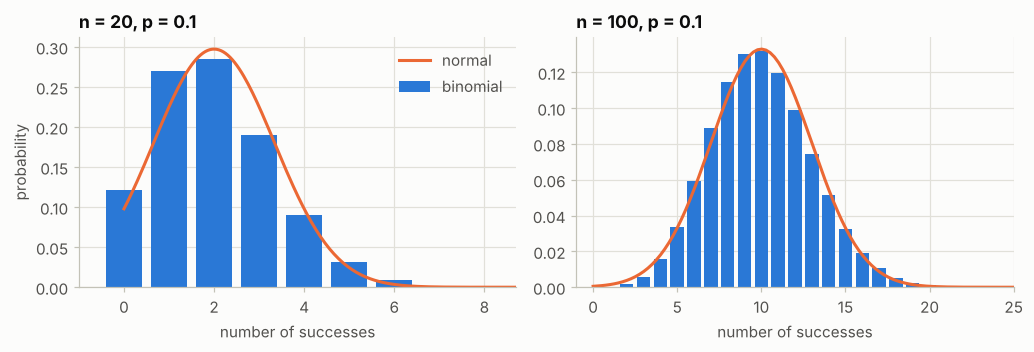

In [39]:
# EXTRA (b): the largest error of the normal approximation to the binomial distribution function, p = 0.1
p = 0.1
rows = []
for n in (5, 20, 100, 1000):
    k = np.arange(0, n + 1)
    exact = stats.binom.cdf(k, n, p)
    mean, sd = n * p, np.sqrt(n * p * (1 - p))
    plain = stats.norm.cdf((k - mean) / sd)
    corrected = stats.norm.cdf((k + 0.5 - mean) / sd)
    rows.append({"n": n, "np": mean, "skewness": (1 - 2 * p) / sd, "error without correction": np.max(np.abs(exact - plain)), "error with correction": np.max(np.abs(exact - corrected))})
print(pd.DataFrame(rows).round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.3))
for ax, n in zip(axes, (20, 100)):
    k = np.arange(0, n + 1)
    mean, sd = n * p, np.sqrt(n * p * (1 - p))
    ax.bar(k, stats.binom.pmf(k, n, p), color=PALETTE[0], width=0.8, label="binomial")
    x = np.linspace(0, n, 400)
    ax.plot(x, stats.norm.pdf(x, mean, sd), color=PALETTE[1], lw=2, label="normal")
    ax.set_xlim(-1, mean + 5 * sd); ax.set_title(f"n = {n}, p = {p}"); ax.set_xlabel("number of successes")
axes[0].set_ylabel("probability"); axes[0].legend()
plt.tight_layout()
plt.show()

**Analysis of extra (b).**

* The error of the normal approximation of the distribution function for $p = 0.1$ is 0.363 for $n = 5$, 0.177 for 20, 0.083 for 100 and 0.027 for 1,000. With the continuity correction it is 4 to 5 times smaller (0.091, 0.037, 0.018, 0.006), and for $n = 100$, where $np = 10$ and the rule of thumb is met, it is still 0.018.
* The skewness of the binomial distribution (1.19, 0.60, 0.27, 0.084) is what the normal curve does not have; it falls as $1/\sqrt{n}$, so the error falls at the same rate.
* In the figure, for $n = 20$ the normal curve puts probability on negative numbers and misses the shape of the bars; for $n = 100$ the bars follow the curve closely. For rare events with small $np$ the Poisson distribution is the better approximation (section 12).

**(c) Intervals for a proportion.** For $n = 30$ and $n = 100$ and for true proportions 0.02, 0.1, 0.3 and 0.5, the cell computes the *exact* coverage of three 95% intervals, the Wald, the Wilson and the exact (Clopper-Pearson) interval. No simulation is needed: for each possible number of successes $k$ the interval is built, and the coverage is the sum of the binomial probabilities of the values of $k$ whose interval contains the true $p$.

In [40]:
# EXTRA (c): exact coverage of three 95% intervals for a proportion
def interval(method, k, n):
    if method == "Wald":
        phat = k / n
        half = 1.96 * np.sqrt(phat * (1 - phat) / n)
        return phat - half, phat + half
    ci = stats.binomtest(k, n).proportion_ci(confidence_level=0.95, method="exact" if method == "Clopper-Pearson" else "wilson")
    return ci.low, ci.high


rows = []
for n in (30, 100):
    ks = np.arange(0, n + 1)
    for method in ("Wald", "Wilson", "Clopper-Pearson"):
        bounds = np.array([interval(method, k, n) for k in ks])
        for p in (0.02, 0.1, 0.3, 0.5):
            pmf = stats.binom.pmf(ks, n, p)
            covered = (bounds[:, 0] <= p) & (p <= bounds[:, 1])
            rows.append({"n": n, "method": method, "p": p, "coverage": pmf[covered].sum(), "expected width": np.sum(pmf * (bounds[:, 1] - bounds[:, 0]))})
table = pd.DataFrame(rows)
print(table.pivot_table(index=["n", "method"], columns="p", values="coverage").round(3).to_string())
print("\nexpected width")
print(table.pivot_table(index=["n", "method"], columns="p", values="expected width").round(3).to_string())

p                     0.02   0.10   0.30   0.50
n   method                                     
30  Clopper-Pearson  0.978  0.992  0.974  0.957
    Wald             0.454  0.809  0.953  0.957
    Wilson           0.978  0.974  0.930  0.957
100 Clopper-Pearson  0.985  0.956  0.963  0.965
    Wald             0.866  0.932  0.950  0.943
    Wilson           0.949  0.936  0.937  0.943

expected width
p                     0.02   0.10   0.30   0.50
n   method                                     
30  Clopper-Pearson  0.147  0.236  0.340  0.368
    Wald             0.065  0.201  0.321  0.352
    Wilson           0.140  0.215  0.307  0.332
100 Clopper-Pearson  0.065  0.126  0.186  0.202
    Wald             0.049  0.116  0.179  0.195
    Wilson           0.063  0.118  0.176  0.191


**Analysis of extra (c).**

* **The Wald interval can be very poor.** For $n = 30$ and a true proportion of 0.02 its coverage is 45.4%, for 0.1 it is 80.9%; for $n = 100$ it is 86.6% for 0.02. Only for $p = 0.3$ and $0.5$ is it close to 95%. Its width for $p = 0.02$ and $n = 30$ is 0.065, less than half the width of the other two intervals: a short interval that is wrong more than half the time.
* **Clopper-Pearson is conservative.** Its coverage is never below 95.6% in the table, and up to 99.2% (for $p = 0.1$, $n = 30$), and its intervals are the longest.
* **Wilson is a good compromise.** Coverage between 93.0% and 97.8% for $n = 30$ and between 93.6% and 94.9% for $n = 100$, with intervals that are shorter than Clopper-Pearson's.
* The coverage of a binomial interval is not a smooth function of $p$, because there are only $n + 1$ possible intervals: it jumps with $p$ and depends on $n$ in a way that is not monotone. This is the "chaotic" behaviour of the Wald interval that Brown, Cai and DasGupta described.

---
## 10. Chi-square distribution

*Book section: "Chi-Square Distribution". The section has no code.*

### Summary

* The **chi-square statistic** measures how far observed counts are from the counts expected under a hypothesis (for instance the hypothesis that two variables are independent, or that a die is fair). The **chi-square distribution** is the reference distribution of that statistic when the hypothesis is true. Its shape depends on the degrees of freedom, and it is skewed to the right.
* A large observed statistic, in the far tail of the distribution, is evidence that the counts do not follow the hypothesis. The chapter keeps the treatment short and points to the tests of Chapter 3, where the statistic is used for tables of counts.
* The distribution is the one that software uses behind the scenes for tests on counts and tables; with resampling methods a data scientist often does not need the formula, but still meets the term in output.

### Theory

**Definition.** If $Z_1, \dots, Z_k$ are independent standard normal variables, then $Q = Z_1^2 + \dots + Z_k^2$ has the chi-square distribution with $k$ degrees of freedom, $\chi^2_k$. It has mean $k$, variance $2k$ and skewness $\sqrt{8/k}$; the sum of independent chi-square variables is chi-square with the sum of the degrees of freedom, and $\chi^2_1 = Z^2$. For large $k$ it is close to a normal distribution.

**The sample variance.** For a sample of $n$ values from a normal population with variance $\sigma^2$,
$$\frac{(n-1)s^2}{\sigma^2} \sim \chi^2_{n-1},$$
which explains the $n-1$ degrees of freedom: the deviations from $\bar x$ satisfy one linear constraint. It gives the interval for the variance
$$\left[\frac{(n-1)s^2}{\chi^2_{n-1,\,1-\alpha/2}},\;\frac{(n-1)s^2}{\chi^2_{n-1,\,\alpha/2}}\right],$$
which depends strongly on the assumption of normality: for data with heavy tails the variance of $s^2$ is larger than the formula assumes, and the coverage falls (extra 10(b)).

**Pearson's chi-square statistic** (Pearson, 1900). For counts $O_i$ in $k$ categories with expected counts $E_i$ under the hypothesis,
$$\chi^2 = \sum_{i=1}^{k}\frac{(O_i - E_i)^2}{E_i}$$
is approximately $\chi^2_{k-1-m}$ if the hypothesis is true, where $m$ is the number of parameters estimated from the data. The approximation rests on each $O_i$ being nearly normal, which needs the expected counts not to be small; a common rule of thumb asks for at least 5 in every category. For tables of counts the statistic and the distribution are those of extra 8(g) of Chapter 1 and of Chapter 3.

### Extra experiments

This section has no code in the book. The experiments below build the distribution, apply it to a sample variance and to a die, and test the rule for small counts.

**(a) A sum of squares of normal variables.** For $k = 1, 2, 5, 10, 30$ the cell draws 100,000 sums of $k$ squared standard normal variables and compares their mean, variance and skewness with the chi-square distribution, and the distribution with a Kolmogorov-Smirnov distance.

 k   mean  theory k  variance  theory 2k  skewness  theory sqrt(8/k)  KS distance
 1  0.997         1     1.994          2     2.806             2.828        0.003
 2  2.000         2     3.984          4     1.978             2.000        0.002
 5  4.975         5     9.981         10     1.261             1.265        0.005
10 10.019        10    19.849         20     0.878             0.894        0.005
30 29.972        30    59.252         60     0.525             0.516        0.004


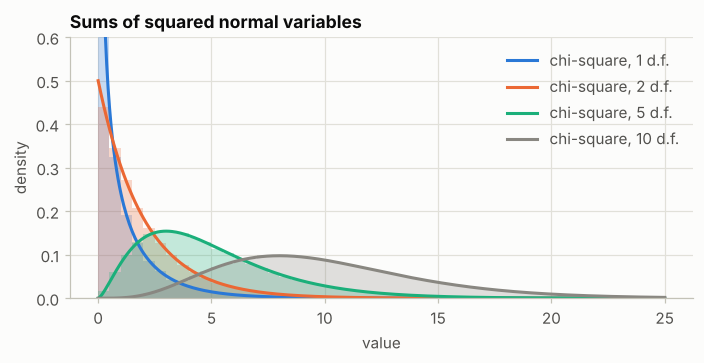

In [41]:
# EXTRA (a): sums of k squared standard normal variables against the chi-square distribution
rng = np.random.default_rng(61)
rows, sims = [], {}
for k in (1, 2, 5, 10, 30):
    q = (rng.normal(size=(100_000, k)) ** 2).sum(axis=1)
    sims[k] = q
    rows.append({"k": k, "mean": q.mean(), "theory k": k, "variance": q.var(ddof=1), "theory 2k": 2 * k, "skewness": stats.skew(q), "theory sqrt(8/k)": np.sqrt(8 / k),
                 "KS distance": stats.kstest(q, "chi2", args=(k,)).statistic})
print(pd.DataFrame(rows).round(3).to_string(index=False))

grid = np.linspace(0, 25, 400)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for k, color in zip((1, 2, 5, 10), PALETTE + [MUTED]):
    ax.hist(sims[k][sims[k] < 25], bins=np.linspace(0, 25, 51), density=True, color=color, alpha=0.25)
    ax.plot(grid, stats.chi2.pdf(grid, k), color=color, lw=2, label=f"chi-square, {k} d.f.")
ax.set_ylim(0, 0.6); ax.set_xlabel("value"); ax.set_ylabel("density")
ax.set_title("Sums of squared normal variables")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis of extra (a).**

* The means (0.997, 2.000, 4.975, 10.019, 29.972) and variances (1.994, 3.984, 9.981, 19.849, 59.252) of the sums of $k$ squared standard normal values agree with $k$ and $2k$ for $k = 1, 2, 5, 10, 30$. The skewness (2.806, 1.978, 1.261, 0.878, 0.525) agrees with $\sqrt{8/k}$ (2.828, 2.000, 1.265, 0.894, 0.516), and the Kolmogorov-Smirnov distance to the chi-square distribution is at most 0.005.
* The figure shows the shapes: for 1 degree of freedom the density is unbounded at 0, for 2 it is an exponential, and as $k$ grows the distribution moves to the right and becomes more symmetric, approaching a normal one.
* The chi-square distribution is *the distribution of a sum of squared deviations*; the statistics of this section and of Chapter 3 are all of this form.

**(b) The distribution of the sample variance, and the interval for a variance.** Samples of 10 values are drawn from a normal population and, for comparison, from an exponential population (whose excess kurtosis is 6). For each, 50,000 samples are drawn and the 95% interval for the variance from the chi-square distribution is computed. The cell reports the coverage, and, for the normal case, the agreement of $(n-1)s^2/\sigma^2$ with $\chi^2_9$.

In [42]:
# EXTRA (b): (n - 1) s^2 / sigma^2 and the chi-square interval for a variance, normal and exponential data
rng = np.random.default_rng(62)
n, repetitions = 10, 50_000
lo_q, hi_q = stats.chi2.ppf([0.025, 0.975], n - 1)
rows = []
for name, draw, variance in (("normal", lambda: rng.normal(0, 2, size=(repetitions, n)), 4.0),
                             ("exponential", lambda: rng.exponential(2, size=(repetitions, n)), 4.0)):
    x = draw()
    s2 = x.var(axis=1, ddof=1)
    stat = (n - 1) * s2 / variance
    lower, upper = (n - 1) * s2 / hi_q, (n - 1) * s2 / lo_q
    rows.append({"data": name, "excess kurtosis": {"normal": 0, "exponential": 6}[name], "coverage of the 95% interval": np.mean((lower <= variance) & (variance <= upper)),
                 "KS distance to chi-square 9": stats.kstest(stat, "chi2", args=(n - 1,)).statistic, "mean of the statistic": stat.mean(), "variance of the statistic": stat.var(ddof=1)})
print(pd.DataFrame(rows).round(4).to_string(index=False))
print(f"theory for chi-square with {n - 1} degrees of freedom: mean {n - 1}, variance {2 * (n - 1)}")

       data  excess kurtosis  coverage of the 95% interval  KS distance to chi-square 9  mean of the statistic  variance of the statistic
     normal                0                        0.9507                       0.0038                 8.9847                    17.9763
exponential                6                        0.7661                       0.1997                 8.9915                    66.7072
theory for chi-square with 9 degrees of freedom: mean 9, variance 18


**Analysis of extra (b).**

* **Normal data.** The statistic $(n-1)s^2/\sigma^2$ follows $\chi^2_9$ (mean 8.985 and variance 17.98 against 9 and 18; Kolmogorov-Smirnov distance 0.004), and the 95% interval for the variance covers the true value in 95.1% of the samples.
* **Exponential data (excess kurtosis 6).** The statistic still has the mean 9 (the sample variance is unbiased), but its variance is 66.7, 3.7 times as large as for the chi-square distribution; this is the value $(n-1)^2\bigl(2/(n-1) + \kappa/n\bigr) = 66.6$ of the general formula, in which the kurtosis $\kappa = 6$ enters. The chi-square distribution is wrong by a wide margin (distance 0.20), and the interval covers only 76.6%, instead of 95%.
* The interval for a mean is protected by the central limit theorem; the interval for a variance is not, because the variance of $s^2$ depends on the fourth moment of the data. For a variance, check the normality of the data first or use a bootstrap interval.

**(c) A goodness-of-fit test of a die.** A die is rolled 60 times. The statistic $\chi^2 = \sum (O - E)^2/E$ with $E = 10$ is compared with the chi-square distribution with 5 degrees of freedom. The cell shows one experiment, then simulates the statistic for 100,000 experiments with a fair die, to see its distribution and the rate of false alarms at the 5% level, and for a loaded die (the six has probability 0.25, the other faces 0.15) to see how often the test detects it.

one experiment with a fair die: counts [7, 14, 13, 12, 4, 10], statistic 7.40, p-value 0.193
critical value of chi-square(5) at 5%: 11.070
fair die: mean of the statistic 5.003 (theory 5), rejection rate 0.0481 (nominal 0.05), KS distance to chi-square 5 0.0212
loaded die: mean of the statistic 7.96, share of the experiments in which the test rejects the fair die 0.219


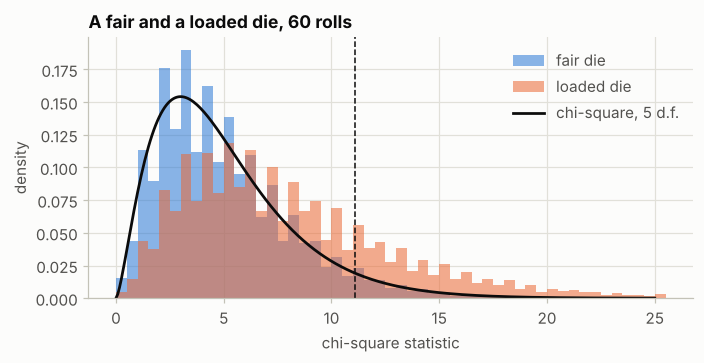

In [43]:
# EXTRA (c): chi-square goodness-of-fit test for a die rolled 60 times
rng = np.random.default_rng(63)
rolls = 60
one = np.bincount(rng.integers(0, 6, rolls), minlength=6)
result = stats.chisquare(one)
print(f"one experiment with a fair die: counts {one.tolist()}, statistic {result.statistic:.2f}, p-value {result.pvalue:.3f}")

critical = stats.chi2.ppf(0.95, 5)
fair = rng.multinomial(rolls, [1 / 6] * 6, size=100_000)
loaded = rng.multinomial(rolls, [0.15] * 5 + [0.25], size=100_000)
stat_fair = ((fair - 10) ** 2 / 10).sum(axis=1)
stat_loaded = ((loaded - 10) ** 2 / 10).sum(axis=1)
print(f"critical value of chi-square(5) at 5%: {critical:.3f}")
print(f"fair die: mean of the statistic {stat_fair.mean():.3f} (theory 5), rejection rate {np.mean(stat_fair > critical):.4f} (nominal 0.05), KS distance to chi-square 5 {stats.kstest(stat_fair, 'chi2', args=(5,)).statistic:.4f}")
print(f"loaded die: mean of the statistic {stat_loaded.mean():.2f}, share of the experiments in which the test rejects the fair die {np.mean(stat_loaded > critical):.3f}")

grid = np.linspace(0, 25, 300)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(stat_fair, bins=np.arange(0, 26, 0.5), density=True, color=PALETTE[0], alpha=0.55, label="fair die")
ax.hist(stat_loaded, bins=np.arange(0, 26, 0.5), density=True, color=PALETTE[1], alpha=0.55, label="loaded die")
ax.plot(grid, stats.chi2.pdf(grid, 5), color=INK, lw=1.8, label="chi-square, 5 d.f.")
ax.axvline(critical, color=INK, ls="--", lw=1)
ax.set_xlabel("chi-square statistic"); ax.set_ylabel("density")
ax.set_title("A fair and a loaded die, 60 rolls")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis of extra (c).**

* **One experiment.** The counts of 60 rolls were 7, 14, 13, 12, 4 and 10, with a statistic of 7.40 and a p-value of 0.193: no evidence against a fair die (one face came up only 4 times against 10 expected, and the test says that this is within chance).
* **A fair die.** Over 100,000 experiments the statistic has mean 5.003 (theory 5), rejects the fair die in 4.81% of the experiments (nominal 5%) and is close to $\chi^2_5$ (distance 0.021, partly an effect of the statistic taking a limited number of values).
* **A loaded die** (the six with probability 0.25 and each other face 0.15): the mean of the statistic is 7.96, which matches $5 + \lambda$ with the non-centrality $\lambda = n\sum(p_i - p_{0i})^2/p_{0i} = 3.0$, and the test rejects the fair die in only 21.9% of the experiments (the non-central chi-square distribution gives 22.2%). With 60 rolls a die that rolls a six one time in four is not reliably detected; more rolls would be needed.

**(d) Small expected counts.** A fair die is rolled $n$ times, with $n = 6, 12, 30, 60, 300$ (expected counts of 1, 2, 5, 10 and 50 per face). For each $n$, 100,000 experiments are simulated and the cell reports how often the 5% chi-square test falsely rejects the fair die, and how many different values the statistic takes.

In [44]:
# EXTRA (d): the false rejection rate of the 5% chi-square test when the expected counts are small
rng = np.random.default_rng(64)
critical = stats.chi2.ppf(0.95, 5)
rows = []
for rolls in (6, 12, 30, 60, 300):
    counts = rng.multinomial(rolls, [1 / 6] * 6, size=100_000)
    stat = ((counts - rolls / 6) ** 2 / (rolls / 6)).sum(axis=1)
    rows.append({"rolls": rolls, "expected count per face": rolls / 6, "false rejection rate": np.mean(stat > critical), "distinct values of the statistic": len(np.unique(np.round(stat, 9))),
                 "mean of the statistic": stat.mean()})
print(f"nominal rate 0.05; with 100,000 experiments the standard error of a rate near 0.05 is {np.sqrt(0.05 * 0.95 / 100_000):.4f}")
print(pd.DataFrame(rows).round(4).to_string(index=False))

nominal rate 0.05; with 100,000 experiments the standard error of a rate near 0.05 is 0.0007
 rolls  expected count per face  false rejection rate  distinct values of the statistic  mean of the statistic
     6                      1.0                0.0575                                 9                 5.0006
    12                      2.0                0.0326                                28                 4.9830
    30                      5.0                0.0487                                72                 5.0034
    60                     10.0                0.0470                               131                 4.9903
   300                     50.0                0.0504                               576                 5.0017


**Analysis of extra (d).**

* The false rejection rate of the 5% test is 5.75% with 1 expected roll per face, 3.26% with 2, 4.87% with 5, 4.70% with 10 and 5.04% with 50 (the standard error is 0.07%).
* With very small expected counts the statistic takes few values (9 different values for 6 rolls, 28 for 12), so the true rate cannot be 5% and is either above or below it. The jump from 3.3% (2 per face) to 4.9% (5 per face) is a property of the lattice of values, not a trend.
* In this experiment the six outcomes are equally likely, which is the favourable case; with unequal probabilities some categories have small expected counts even when the total is large, and the rule "at least 5 in each category" is about those.

---
## 11. $F$-distribution

*Book section: "F-Distribution". The section has no code.*

### Summary

* The **$F$-distribution** is the reference distribution for a **ratio of two variances** (or of two mean squares). It is used in the **analysis of variance (ANOVA)**, which compares the means of several groups by asking whether the variation *between* the groups is large compared with the variation *within* them (Chapter 3), and in regression, to ask whether a set of coefficients is useful (Chapter 4).
* The **$F$-statistic** is the observed ratio; it is compared with the $F$-distribution that would arise if the groups did not differ. The distribution has two parameters, the degrees of freedom of the numerator and of the denominator, and is skewed to the right.
* As for the chi-square distribution, data scientists meet it mostly in software output; the book's treatment is brief, and the permutation version of the test in Chapter 3 avoids the need for the table.

### Theory

**Definition.** If $V_1 \sim \chi^2_{d_1}$ and $V_2 \sim \chi^2_{d_2}$ are independent, then
$$F = \frac{V_1/d_1}{V_2/d_2} \sim F_{d_1, d_2}.$$
Its mean is $d_2/(d_2 - 2)$ for $d_2 > 2$ and it is skewed to the right. For two independent samples of sizes $n_1$ and $n_2$ from normal populations with the same variance, the ratio of the sample variances $s_1^2/s_2^2$ has the $F_{n_1 - 1, n_2 - 1}$ distribution.

**Relations.** The square of a $t$ variable with $\nu$ degrees of freedom has the $F_{1,\nu}$ distribution, so a two-sided $t$ test and an $F$ test with one degree of freedom in the numerator are the same test. When the denominator degrees of freedom grow, $d_1 F_{d_1, d_2}$ approaches $\chi^2_{d_1}$.

**Analysis of variance.** For $g$ groups with $N$ observations in all, the mean square between groups $\mathrm{MSB} = \mathrm{SSB}/(g-1)$ and the mean square within groups $\mathrm{MSW} = \mathrm{SSW}/(N-g)$ have the same expected value if the group means are equal, and then $F = \mathrm{MSB}/\mathrm{MSW} \sim F_{g-1,N-g}$ under normality. Differences between the means inflate the numerator only, so a large $F$ is evidence against equal means.

**A warning.** The $F$ test for the equality of two variances relies strongly on normality: with heavy-tailed or skewed data its false rejection rate is far above the nominal level (Box, 1953), which is why it is replaced in practice by tests such as that of Levene (1960) and the variant of Brown and Forsythe (1974) (extra 11(c)).

### Extra experiments

This section has no code in the book.

**(a) A ratio of variances.** Two independent samples of sizes 8 and 12 are drawn from the same normal population, 200,000 times. The cell compares the distribution of $s_1^2/s_2^2$ with $F_{7,11}$ by a table of quantiles and a Kolmogorov-Smirnov distance.

 level  simulated quantile  F(7, 11) quantile
  0.05               0.278              0.278
  0.25               0.594              0.593
  0.50               0.967              0.964
  0.75               1.545              1.542
  0.95               3.016              3.012
  0.99               4.897              4.886

KS distance to F(7, 11): 0.0021; mean 1.225 (theory 1.222)
share of the ratios above the 5% critical value 3.012: 0.0502


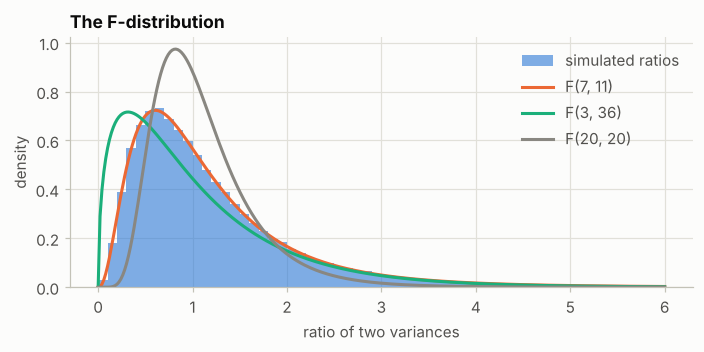

In [45]:
# EXTRA (a): the ratio of two sample variances against the F-distribution
rng = np.random.default_rng(71)
n1, n2, repetitions = 8, 12, 200_000
ratio = rng.normal(size=(repetitions, n1)).var(axis=1, ddof=1) / rng.normal(size=(repetitions, n2)).var(axis=1, ddof=1)
levels = [0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
print(pd.DataFrame({"level": levels, "simulated quantile": np.quantile(ratio, levels), "F(7, 11) quantile": stats.f.ppf(levels, n1 - 1, n2 - 1)}).round(3).to_string(index=False))
print(f"\nKS distance to F(7, 11): {stats.kstest(ratio, 'f', args=(n1 - 1, n2 - 1)).statistic:.4f}; mean {ratio.mean():.3f} (theory {(n2 - 1) / (n2 - 3):.3f})")
print(f"share of the ratios above the 5% critical value {stats.f.ppf(0.95, n1 - 1, n2 - 1):.3f}: {np.mean(ratio > stats.f.ppf(0.95, n1 - 1, n2 - 1)):.4f}")

grid = np.linspace(0, 6, 300)
fig, ax = plt.subplots(figsize=(6.5, 3.3))
ax.hist(ratio[ratio < 6], bins=np.linspace(0, 6, 61), density=True, color=PALETTE[0], alpha=0.6, label="simulated ratios")
for (d1, d2), color in zip(((7, 11), (3, 36), (20, 20)), (PALETTE[1], PALETTE[2], MUTED)):
    ax.plot(grid, stats.f.pdf(grid, d1, d2), color=color, lw=2, label=f"F({d1}, {d2})")
ax.set_xlabel("ratio of two variances"); ax.set_ylabel("density")
ax.set_title("The F-distribution")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis of extra (a).**

* The simulated quantiles of the ratio of two sample variances (sizes 8 and 12, same variance) agree with those of $F_{7,11}$ to the third decimal (0.278, 0.594, 0.967, 1.545, 3.016, 4.897 against 0.278, 0.593, 0.964, 1.542, 3.012, 4.886); the Kolmogorov-Smirnov distance is 0.002, the mean 1.225 (theory $11/9 = 1.222$) and 5.02% of the ratios exceed the 5% critical value.
* The distribution is skewed to the right and its mean is above 1 even though the two variances are equal. The figure also shows $F_{3,36}$ and $F_{20,20}$: more degrees of freedom concentrate the distribution around 1.

**(b) Links with $t$ and with the chi-square distribution.** The cell checks numerically that $F_{1,\nu}$ is the square of $t_\nu$ (the 95% quantile of $F_{1,\nu}$ against the square of the 97.5% quantile of $t_\nu$), and that $d_1 F_{d_1, d_2}$ approaches $\chi^2_{d_1}$ as $d_2$ grows.

In [46]:
# EXTRA (b): F(1, v) = t(v)^2, and d1 * F(d1, d2) -> chi-square(d1)
rows = [{"v": v, "F(1, v) 95% quantile": stats.f.ppf(0.95, 1, v), "t(v) 97.5% quantile squared": stats.t.ppf(0.975, v) ** 2} for v in (3, 10, 30, 100)]
print(pd.DataFrame(rows).round(4).to_string(index=False))

rows = [{"d2": d2, "3 * F(3, d2) 95% quantile": 3 * stats.f.ppf(0.95, 3, d2)} for d2 in (5, 10, 30, 100, 1000, 100_000)]
rows.append({"d2": "infinity", "3 * F(3, d2) 95% quantile": stats.chi2.ppf(0.95, 3)})
print("\nthe 95% quantile of chi-square with 3 degrees of freedom is the limit")
print(pd.DataFrame(rows).round(4).to_string(index=False))

rng = np.random.default_rng(72)
t_sq = rng.standard_t(10, size=200_000) ** 2
print(f"\nsimulated: P(t(10)^2 > F(1, 10) 95% quantile) = {np.mean(t_sq > stats.f.ppf(0.95, 1, 10)):.4f}")

  v  F(1, v) 95% quantile  t(v) 97.5% quantile squared
  3               10.1280                      10.1280
 10                4.9646                       4.9646
 30                4.1709                       4.1709
100                3.9361                       3.9361

the 95% quantile of chi-square with 3 degrees of freedom is the limit
      d2  3 * F(3, d2) 95% quantile
       5                    16.2284
      10                    11.1248
      30                     8.7668
     100                     8.0866
    1000                     7.8414
  100000                     7.8150
infinity                     7.8147

simulated: P(t(10)^2 > F(1, 10) 95% quantile) = 0.0504


**Analysis of extra (b).**

* The 95% quantile of $F_{1,\nu}$ equals the square of the 97.5% quantile of $t_\nu$ to four decimals for $\nu = 3, 10, 30, 100$ (10.128, 4.965, 4.171, 3.936), and in the simulation 5.04% of the values of $t_{10}^2$ exceed the 95% quantile of $F_{1,10}$.
* The limit: $3 F_{3,d_2}$ at the 95% level is 16.23 for $d_2 = 5$, 11.12 for 10, 8.77 for 30, 8.09 for 100, 7.84 for 1,000 and 7.815 for 100,000, approaching 7.8147, the quantile of $\chi^2_3$.
* So a two-sided $t$ test and an $F$ test with one numerator degree of freedom are the same test, and with many denominator degrees of freedom the $F$ test becomes a chi-square test.

**(c) The fragility of the variance-ratio test.** Two samples of 20 values are drawn from the *same* distribution, so that the variances are equal and every rejection is a false alarm. For four distributions (normal, uniform, $t$ with 5 degrees of freedom, exponential), 100,000 pairs are drawn and two tests at the 5% level are applied: the two-sided $F$ test and the Brown-Forsythe version of Levene's test, which compares the absolute deviations from the median. The cell checks that the Brown-Forsythe computation agrees with `scipy.stats.levene` and reports the false rejection rates.

In [47]:
# EXTRA (c): false rejection rates of the F test for two variances and of the Brown-Forsythe test, equal variances
rng = np.random.default_rng(73)
n, repetitions = 20, 100_000
distributions = {
    "normal": lambda size: rng.normal(size=size),
    "uniform (excess kurtosis -1.2)": lambda size: rng.random(size),
    "t with 5 degrees of freedom (excess kurtosis 6)": lambda size: rng.standard_t(5, size=size),
    "exponential (excess kurtosis 6)": lambda size: rng.exponential(size=size),
}


def brown_forsythe(x1, x2):
    """F statistic of a one-way analysis of variance on the absolute deviations from the group medians (two groups, rows are samples)."""
    z1, z2 = np.abs(x1 - np.median(x1, axis=1, keepdims=True)), np.abs(x2 - np.median(x2, axis=1, keepdims=True))
    m1, m2 = z1.mean(axis=1), z2.mean(axis=1)
    grand = (m1 + m2) / 2
    ssb = x1.shape[1] * ((m1 - grand) ** 2 + (m2 - grand) ** 2)
    ssw = ((z1 - m1[:, None]) ** 2).sum(axis=1) + ((z2 - m2[:, None]) ** 2).sum(axis=1)
    return ssb / (ssw / (2 * x1.shape[1] - 2))


check_1, check_2 = rng.exponential(size=(1, n)), rng.exponential(size=(1, n))
print(f"my Brown-Forsythe statistic {brown_forsythe(check_1, check_2)[0]:.6f}; scipy.stats.levene(center='median') {stats.levene(check_1[0], check_2[0], center='median').statistic:.6f}")

f_lo, f_hi = stats.f.ppf([0.025, 0.975], n - 1, n - 1)
bf_critical = stats.f.ppf(0.95, 1, 2 * n - 2)
rows = []
for name, draw in distributions.items():
    x1, x2 = draw((repetitions, n)), draw((repetitions, n))
    ratio = x1.var(axis=1, ddof=1) / x2.var(axis=1, ddof=1)
    rows.append({"distribution": name, "F test: false rejections": np.mean((ratio < f_lo) | (ratio > f_hi)), "Brown-Forsythe: false rejections": np.mean(brown_forsythe(x1, x2) > bf_critical)})
print(f"nominal rate 0.05; the standard error of a rate near 0.05 is {np.sqrt(0.05 * 0.95 / repetitions):.4f}")
print(pd.DataFrame(rows).round(4).to_string(index=False))

my Brown-Forsythe statistic 0.162184; scipy.stats.levene(center='median') 0.162184
nominal rate 0.05; the standard error of a rate near 0.05 is 0.0007
                                   distribution  F test: false rejections  Brown-Forsythe: false rejections
                                         normal                    0.0512                            0.0405
                 uniform (excess kurtosis -1.2)                    0.0052                            0.0332
t with 5 degrees of freedom (excess kurtosis 6)                    0.1598                            0.0410
                exponential (excess kurtosis 6)                    0.2659                            0.0475


**Analysis of extra (c).**

* With **normal** data the two tests keep their levels: false rejections of 5.12% for the $F$ test and 4.05% for Brown-Forsythe (a little conservative for $n = 20$).
* With **heavy-tailed or skewed** data the $F$ test fails: 16.0% for $t_5$ and 26.6% for the exponential distribution, 3 and 5 times the nominal rate. With **light tails** (uniform) it rejects far too rarely, 0.5%, so it would have almost no power. The Brown-Forsythe test stays between 3.3% and 4.8% in all four cases.
* The $F$ test is a test of normality as much as of equal variances. For means the corresponding tests are more forgiving (the central limit theorem), but variances do not have this protection, which was the point of Box (1953).
* My Brown-Forsythe statistic agrees with `scipy.stats.levene(center='median')` (0.162184 for both).

**(d) The $F$-statistic of an analysis of variance.** Four groups of 10 values are drawn from the same normal population (no difference) 50,000 times, and then with a difference between the group means. The cell computes the statistic $\mathrm{MSB}/\mathrm{MSW}$ by hand, checks it against `scipy.stats.f_oneway`, and compares its distribution with $F_{3,36}$ and its rejection rate with the nominal 5%.

In [48]:
# EXTRA (d): the F statistic of a one-way analysis of variance, no difference and a difference
rng = np.random.default_rng(74)
groups, size, repetitions = 4, 10, 50_000


def anova_f(data):
    """data: repetitions x groups x size."""
    group_means = data.mean(axis=2)
    grand = data.mean(axis=(1, 2))
    ssb = size * ((group_means - grand[:, None]) ** 2).sum(axis=1)
    ssw = ((data - group_means[:, :, None]) ** 2).sum(axis=(1, 2))
    return (ssb / (groups - 1)) / (ssw / (groups * size - groups))


null = rng.normal(size=(repetitions, groups, size))
shifted = null + np.array([0.0, 0.0, 0.0, 1.0])[None, :, None]       # one group has a mean one standard deviation higher
check = rng.normal(size=(1, groups, size))
print(f"my F statistic {anova_f(check)[0]:.6f}; scipy.stats.f_oneway {stats.f_oneway(*check[0]).statistic:.6f}")
critical = stats.f.ppf(0.95, groups - 1, groups * size - groups)
f_null, f_shifted = anova_f(null), anova_f(shifted)
print(f"critical value of F(3, 36) at 5%: {critical:.3f}")
print(f"no difference: mean of F {f_null.mean():.3f} (theory {36 / 34:.3f}), KS distance to F(3, 36) {stats.kstest(f_null, 'f', args=(3, 36)).statistic:.4f}, rejection rate {np.mean(f_null > critical):.4f}")
print(f"one group one standard deviation higher: mean of F {f_shifted.mean():.3f}, rejection rate (power) {np.mean(f_shifted > critical):.3f}")

my F statistic 1.460547; scipy.stats.f_oneway 1.460547
critical value of F(3, 36) at 5%: 2.866
no difference: mean of F 1.064 (theory 1.059), KS distance to F(3, 36) 0.0065, rejection rate 0.0513
one group one standard deviation higher: mean of F 3.717, rejection rate (power) 0.577


**Analysis of extra (d).**

* The statistic computed by hand agrees with `scipy.stats.f_oneway` (1.460547). When there is no difference its mean is 1.064 (theory $36/34 = 1.059$), it follows $F_{3,36}$ (distance 0.0065) and the 5% test rejects in 5.13% of the experiments.
* When one of the four groups has a mean one standard deviation higher, the mean of $F$ is 3.72 and the test finds the difference in 57.7% of the experiments (its power). With 10 observations per group a shift of one standard deviation in one group of four is detected a little more than half of the time.

---
## 12. Poisson and related distributions

*Book section: "Poisson and Related Distributions" (Poisson distributions, exponential distribution, estimating the failure rate, Weibull distribution). The code of the script draws a sample from the Poisson, the exponential and the Weibull distribution and plots its histogram.*

### Summary

* Many processes produce events at a roughly constant average **rate** over time or space: customers who arrive, calls that come in, defects along a length of cable, failures of a machine. The **Poisson distribution** gives the number of events in an interval of fixed length when the average number is $\lambda$; its mean and its variance are both equal to $\lambda$.
* The **exponential distribution** describes the *time between* events for such a process, with the same rate $\lambda$; its mean is $1/\lambda$.
* To **estimate a rate** the number of events is divided by the total time (or space) in which they could have been observed; with failures, the rate of failure can be estimated from the observed lifetimes. The estimate is only useful if the rate is constant.
* The **Weibull distribution** generalizes the exponential one for the case where the **rate of events changes over time**: a shape parameter below 1 means that events become rarer over time (early failures), equal to 1 a constant rate (the exponential case) and above 1 an increasing rate (wear-out). It is the usual model for the time to failure of a component.
* The script draws 100 values from a Poisson distribution with $\lambda = 2$, from an exponential distribution with scale 5 and from a Weibull distribution with shape 1.5 and scale 5,000, and plots a histogram of each.

### Theory

**Poisson.** $P(X = k) = e^{-\lambda}\lambda^k/k!$ for $k = 0, 1, 2, \dots$, with $E X = \operatorname{Var} X = \lambda$. The sum of independent Poisson variables is Poisson with the sum of the rates. It is the limit of the binomial distribution when $n \to \infty$ and $p \to 0$ with $np = \lambda$, which makes it the natural model for *rare events among many opportunities*.

**The Poisson process.** If the gaps between consecutive events are independent exponential variables with rate $\lambda$, the number of events in any interval of length $t$ is Poisson with mean $\lambda t$, and counts in disjoint intervals are independent; the two distributions describe the same process from two sides (counts and gaps).

**Exponential.** Density $f(x) = \lambda e^{-\lambda x}$ for $x \ge 0$, survival function $P(X > x) = e^{-\lambda x}$, mean $1/\lambda$, standard deviation $1/\lambda$. It is **memoryless**: $P(X > s + t \mid X > s) = P(X > t)$, so a component that has survived $s$ units is as good as new, and its hazard (the instantaneous failure rate) is constant. If $x_1, \dots, x_n$ are independent exponential lifetimes the maximum likelihood estimate of the rate is $\hat\lambda = 1/\bar x$, and $2n\lambda/\hat\lambda \sim \chi^2_{2n}$ gives the exact interval $\bigl[\hat\lambda\,\chi^2_{2n,\alpha/2}/(2n),\ \hat\lambda\,\chi^2_{2n,1-\alpha/2}/(2n)\bigr]$. The estimate $\hat\lambda$ is biased upward, $E\hat\lambda = n\lambda/(n-1)$; $(n-1)/\sum x_i$ is unbiased.

**Weibull.** With shape $\beta$ and scale $\eta$, the survival function is $\exp\bigl(-(x/\eta)^\beta\bigr)$, the density $\frac{\beta}{\eta}(x/\eta)^{\beta-1}e^{-(x/\eta)^\beta}$ and the hazard $h(x) = \frac{\beta}{\eta}(x/\eta)^{\beta - 1}$: decreasing for $\beta < 1$, constant for $\beta = 1$ (exponential) and increasing for $\beta > 1$. The mean is $\eta\,\Gamma(1 + 1/\beta)$. In `scipy` the distribution is `weibull_min` with the shape as first argument and `scale` $= \eta$. The parameters are estimated by numerical maximum likelihood.

**Overdispersion.** Real counts often have a variance larger than the mean, because the rate itself varies (busy and quiet hours, customers who differ). A Poisson variable whose rate is gamma-distributed is negative binomial, with variance larger than the mean; a Poisson model fitted to such counts understates the probability of large counts. The ratio variance/mean, the **index of dispersion**, is a first check.

### Book code

The script draws one sample of each distribution and plots a histogram of it with `pandas`. The cells below add a seed (the script has none).

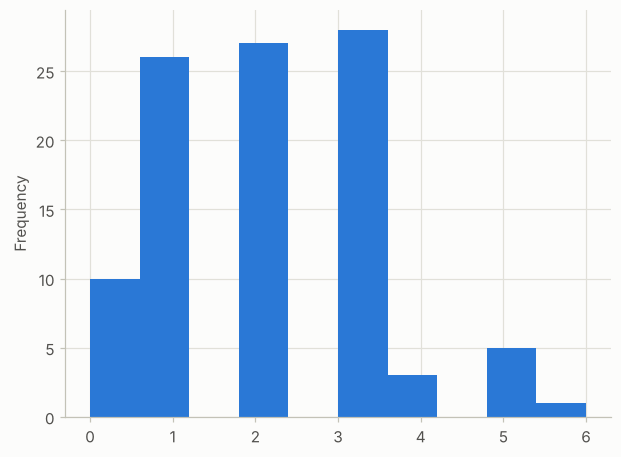

In [49]:
# BOOK CODE (Poisson Distributions): 100 values of a Poisson distribution with lambda = 2
np.random.seed(2024)  # NOT IN THE BOOK: the book's sample has no seed

sample = stats.poisson.rvs(2, size=100)

pd.Series(sample).plot.hist()
plt.show()

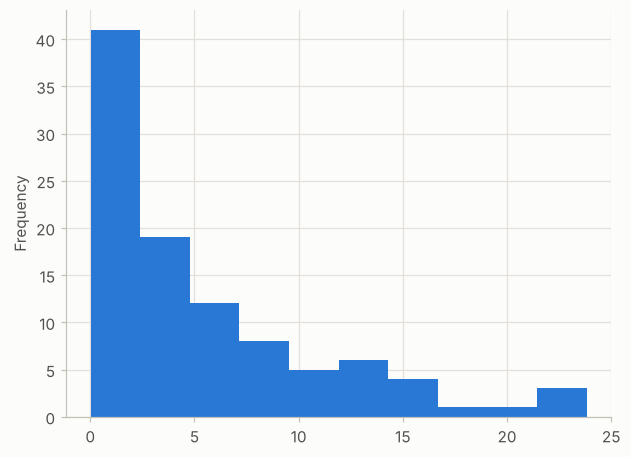

In [50]:
# BOOK CODE (Exponential Distribution): 100 values with scale 5, that is a rate of 0.2 events per unit of time
np.random.seed(2025)  # NOT IN THE BOOK: the book's sample has no seed

sample = stats.expon.rvs(scale=5, size=100)

pd.Series(sample).plot.hist()
plt.show()

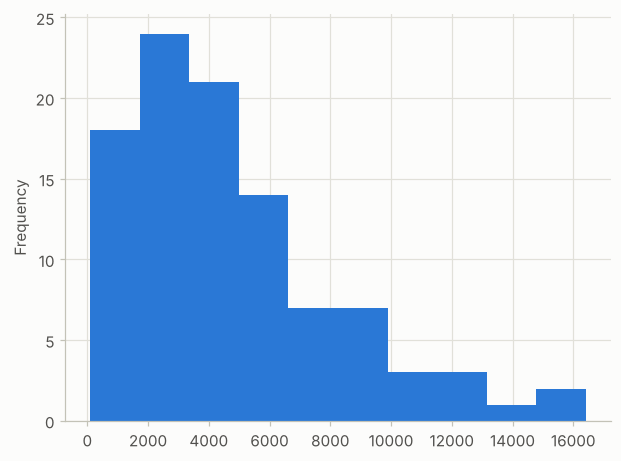

In [51]:
# BOOK CODE (Weibull Distribution): 100 values with shape 1.5 and scale 5000
np.random.seed(2026)  # NOT IN THE BOOK: the book's sample has no seed

sample = stats.weibull_min.rvs(1.5, scale=5000, size=100)

pd.Series(sample).plot.hist()
plt.show()

**Output analysis.**

* **Poisson with $\lambda = 2$.** The 100 values range from 0 to 6, with the counts 10, 26, 27, 28, 3, 5, 1 for the values 0 to 6 (extra 12(a) prints them). The histogram has 10 bins of the same width for integer values, so some bins are empty and the bars have uneven heights; for a discrete variable a bar chart of the count of each integer would be clearer. This particular sample has 28 threes (18 expected) and 3 fours (9 expected), a reminder that a sample of 100 can differ visibly from its distribution.
* **Exponential with scale 5.** A decreasing histogram with a long right tail: many short times and a few long ones; the sample has mean 5.42 and standard deviation 5.70, close to the 5 and 5 of the distribution (mean equal to standard deviation is a trait of the exponential distribution).
* **Weibull with shape 1.5 and scale 5,000.** A histogram whose highest bars are at about 1,600 to 4,900 and a right tail that reaches 16,400; the sample has mean 4,686 against 4,514 for the distribution. With a shape above 1 there are fewer very short lifetimes than for the exponential distribution.

### Extra experiments

**(a) The Poisson distribution, and its limit of the binomial.** The cell compares the probabilities of the Poisson distribution with $\lambda = 2$ with the frequencies in one million simulated values, checks that mean and variance are equal and that the sum of two independent Poisson variables is Poisson, and measures how close the binomial distribution with $np = 2$ is to it for $n = 10, 100, 1000$ (the total variation distance, half the sum of the absolute differences of the probabilities).

In [52]:
# EXTRA (a): the Poisson distribution with lambda = 2, a sum of two, and the limit of the binomial distribution
# the three samples of the book cells, rebuilt with their seeds, against the values of their distributions
book_samples = {
    "Poisson, lambda 2 (seed 2024)": (stats.poisson.rvs(2, size=100, random_state=np.random.RandomState(2024)), 2.0, np.sqrt(2.0)),
    "exponential, scale 5 (seed 2025)": (stats.expon.rvs(scale=5, size=100, random_state=np.random.RandomState(2025)), 5.0, 5.0),
    "Weibull, shape 1.5, scale 5000 (seed 2026)": (stats.weibull_min.rvs(1.5, scale=5000, size=100, random_state=np.random.RandomState(2026)),
                                                   stats.weibull_min.mean(1.5, scale=5000), stats.weibull_min.std(1.5, scale=5000)),
}
print(pd.DataFrame({name: {"sample mean": x.mean(), "mean of the distribution": m, "sample sd": x.std(ddof=1), "sd of the distribution": s, "minimum": x.min(), "maximum": x.max()}
                    for name, (x, m, s) in book_samples.items()}).T.round(2).to_string())
print("counts of the Poisson sample for 0, 1, 2, ...:", np.bincount(book_samples["Poisson, lambda 2 (seed 2024)"][0]).tolist(), "\n")

rng = np.random.default_rng(81)
lam = 2
big = rng.poisson(lam, size=1_000_000)
k = np.arange(0, 9)
print(pd.DataFrame({"k": k, "probability": stats.poisson.pmf(k, lam), "simulated": [np.mean(big == j) for j in k], "cdf": stats.poisson.cdf(k, lam)}).round(5).to_string(index=False))
small = rng.poisson(lam, 100)
print(f"\nmean {big.mean():.4f}, variance {big.var():.4f}, index of dispersion {big.var() / big.mean():.3f}; one sample of 100: mean {small.mean():.2f}, variance {small.var(ddof=1):.2f}")

total = rng.poisson(2, size=1_000_000) + rng.poisson(3, size=1_000_000)
print(f"Poisson(2) + Poisson(3): mean {total.mean():.3f}, variance {total.var():.3f}; KS-type distance to Poisson(5): {np.max(np.abs(np.cumsum(np.bincount(total, minlength=30)[:30]) / total.size - stats.poisson.cdf(np.arange(30), 5))):.4f}")

rows = []
support = np.arange(0, 60)
for n in (10, 100, 1000):
    tv = 0.5 * np.sum(np.abs(stats.binom.pmf(support, n, lam / n) - stats.poisson.pmf(support, lam)))
    rows.append({"n": n, "p = 2 / n": lam / n, "total variation distance to Poisson(2)": tv})
print("\nbinomial distribution with np = 2 against Poisson(2)")
print(pd.DataFrame(rows).round(4).to_string(index=False))

                                            sample mean  mean of the distribution  sample sd  sd of the distribution  minimum   maximum
Poisson, lambda 2 (seed 2024)                      2.07                      2.00       1.30                    1.41     0.00      6.00
exponential, scale 5 (seed 2025)                   5.42                      5.00       5.70                    5.00     0.02     23.82
Weibull, shape 1.5, scale 5000 (seed 2026)      4686.35                   4513.73    3484.28                 3064.68    89.63  16420.83
counts of the Poisson sample for 0, 1, 2, ...: [10, 26, 27, 28, 3, 5, 1] 

 k  probability  simulated     cdf
 0      0.13534    0.13550 0.13534
 1      0.27067    0.27060 0.40601
 2      0.27067    0.27074 0.67668
 3      0.18045    0.18058 0.85712
 4      0.09022    0.09019 0.94735
 5      0.03609    0.03610 0.98344
 6      0.01203    0.01185 0.99547
 7      0.00344    0.00337 0.99890
 8      0.00086    0.00084 0.99976

mean 1.9987, variance 1.9953, 

**Analysis of extra (a).**

* **The three book samples** are close to their distributions, with the sampling error that 100 values bring: the Poisson sample has mean 2.07 and standard deviation 1.30 (distribution: 2 and 1.41), the exponential one 5.42 and 5.70 (5 and 5), the Weibull one 4,686 and 3,484 (4,514 and 3,065).
* **Poisson with $\lambda = 2$.** The probabilities of 0 to 8 events are 0.135, 0.271, 0.271, 0.180, 0.090, 0.036, 0.012, 0.003 and 0.001 and the simulation agrees; mean 1.999 and variance 1.995 (index of dispersion 0.998). A single sample of 100 has variance 1.60, which is 20% below 2 by chance. The sum of Poisson(2) and Poisson(3) has mean 4.999 and variance 5.004 and is within 0.0005 of Poisson(5) in distribution function.
* **The binomial limit.** The total variation distance between the binomial distribution with $np = 2$ and Poisson(2) is 0.052 for $n = 10$, 0.0046 for 100 and 0.0005 for 1,000, a factor of 10 for each factor of 10 in $n$: for rare events among many opportunities the two distributions are practically the same.

**(b) One process, two distributions.** Events occur with a rate of 2 per unit of time, simulated by independent exponential gaps over 20,000 time units. The cell counts the events in each unit of time and tests the counts against the Poisson distribution with $\lambda = 2$, tests the gaps against the exponential distribution, and checks the memoryless property.

In [53]:
# EXTRA (b): exponential gaps give Poisson counts
rng = np.random.default_rng(82)
rate, horizon = 2.0, 20_000
gaps = rng.exponential(1 / rate, size=int(rate * horizon * 1.2))
times = np.cumsum(gaps)
times = times[times < horizon]
counts = np.bincount(times.astype(int), minlength=horizon)
print(f"{len(times):,} events in {horizon:,} units of time; mean gap {gaps[:len(times)].mean():.4f} (theory {1 / rate}); KS distance of the gaps to the exponential distribution {stats.kstest(gaps[:len(times)], 'expon', args=(0, 1 / rate)).statistic:.4f}")
print(f"counts per unit of time: mean {counts.mean():.3f}, variance {counts.var():.3f}")
observed = np.bincount(counts, minlength=9)[:9]
categories = np.arange(0, 9)
expected = stats.poisson.pmf(categories, rate) * horizon
expected[-1] += stats.poisson.sf(8, rate) * horizon               # the last category is "8 or more"
observed[-1] += np.sum(counts > 8)
test = stats.chisquare(observed, expected, ddof=0)
print(pd.DataFrame({"events in a unit of time": [*categories[:-1], "8 or more"], "observed": observed, "expected (Poisson, 2)": expected.round(1)}).to_string(index=False))
print(f"chi-square statistic {test.statistic:.2f} with {len(observed) - 1} degrees of freedom, p-value {test.pvalue:.3f}")

s, t = 0.5, 0.3
long_gaps = gaps[:len(times)]
print(f"\nmemoryless property: P(gap > {s} + {t} | gap > {s}) = {np.mean(long_gaps > s + t) / np.mean(long_gaps > s):.4f}; P(gap > {t}) = {np.mean(long_gaps > t):.4f}; theory exp(-{rate} * {t}) = {np.exp(-rate * t):.4f}")

40,068 events in 20,000 units of time; mean gap 0.4991 (theory 0.5); KS distance of the gaps to the exponential distribution 0.0037
counts per unit of time: mean 2.003, variance 2.001
events in a unit of time  observed  expected (Poisson, 2)
                       0      2677                 2706.7
                       1      5400                 5413.4
                       2      5478                 5413.4
                       3      3598                 3608.9
                       4      1777                 1804.5
                       5       745                  721.8
                       6       226                  240.6
                       7        70                   68.7
               8 or more        29                   21.9
chi-square statistic 5.51 with 8 degrees of freedom, p-value 0.702

memoryless property: P(gap > 0.5 + 0.3 | gap > 0.5) = 0.5487; P(gap > 0.3) = 0.5507; theory exp(-2.0 * 0.3) = 0.5488


**Analysis of extra (b).**

* 40,068 events occur in 20,000 time units (rate 2.003). The gaps have a mean of 0.4991 (theory 0.5) and are at a Kolmogorov-Smirnov distance of 0.004 from the exponential distribution.
* The counts per time unit have mean 2.003 and variance 2.001, and a chi-square test of the table against Poisson(2) gives 5.51 with 8 degrees of freedom and a p-value of 0.702: the counts are consistent with the Poisson distribution, which the construction implies.
* The memoryless property: after a gap of 0.5 has passed, the probability that it lasts 0.3 more is 0.5487; the probability that a new gap lasts 0.3 is 0.5507; the theory says $e^{-0.6} = 0.5488$ for both. The process has no memory of how long it has waited.

**(c) Overdispersion.** Counts are drawn from a Poisson distribution whose rate varies from one interval to the next (gamma distributed with mean 2 and variance 2), which gives a negative binomial distribution with the same mean as Poisson(2) but twice its variance. The cell compares the index of dispersion, the chi-square statistic against a Poisson distribution with the same mean, and the probability of large counts, with those of a Poisson variable.

In [54]:
# EXTRA (c): counts with a varying rate are overdispersed
rng = np.random.default_rng(83)
size = 200_000
steady = rng.poisson(2, size=size)
varying_rate = rng.gamma(shape=2.0, scale=1.0, size=size)        # mean 2, variance 2
mixed = rng.poisson(varying_rate)
rows = []
for name, x in (("steady rate 2", steady), ("rate varies, mean 2", mixed)):
    categories = np.arange(0, 10)
    observed = np.bincount(np.minimum(x, 9), minlength=10)
    expected = stats.poisson.pmf(categories, x.mean()) * size
    expected[-1] = stats.poisson.sf(8, x.mean()) * size
    gof = stats.chisquare(observed, expected, ddof=1)
    rows.append({"counts": name, "mean": x.mean(), "variance": x.var(), "index of dispersion": x.var() / x.mean(), "chi-square against Poisson": gof.statistic,
                 "P(count >= 6)": np.mean(x >= 6), "Poisson with the same mean": stats.poisson.sf(5, x.mean()), "P(count = 0)": np.mean(x == 0), "Poisson P(0)": stats.poisson.pmf(0, x.mean())})
print(pd.DataFrame(rows).round(4).to_string(index=False))
print(f"\nthe negative binomial distribution has variance 2 + 2 = 4 here; P(count >= 6) = {stats.nbinom.sf(5, 2, 1 / 2):.4f}")

             counts   mean  variance  index of dispersion  chi-square against Poisson  P(count >= 6)  Poisson with the same mean  P(count = 0)  Poisson P(0)
      steady rate 2 2.0039    2.0230               1.0095                     12.7995         0.0173                      0.0167        0.1359        0.1348
rate varies, mean 2 1.9953    3.9836               1.9965                 149019.2951         0.0620                      0.0164        0.2513        0.1360

the negative binomial distribution has variance 2 + 2 = 4 here; P(count >= 6) = 0.0625


**Analysis of extra (c).**

* **Steady rate.** Counts from Poisson(2) have an index of dispersion of 1.01, and a chi-square test against the Poisson distribution with their mean gives 12.8 (8 degrees of freedom, no rejection).
* **Varying rate.** Counts with the same mean (1.995) have a variance of 3.98, an index of dispersion of 2.0, and a chi-square statistic against the Poisson distribution of 149,019. The chance of 6 or more events is 6.2% (the negative binomial theory gives 6.25%), 3.8 times the 1.6% of the Poisson distribution with the same mean; the chance of no event is 25.1% against 13.6%. Both ends are heavier: more empty intervals and more very busy ones.
* A Poisson model fitted to such counts through their mean would underestimate the chance of a busy period by a factor of almost 4, which is the type of error that makes capacity plans too tight. A variance well above the mean is the sign to look for a varying rate.

**(d) Estimating a failure rate.** Lifetimes are exponential with a mean of 5, so the true failure rate is 0.2. For samples of 5, 10, 20 and 50 lifetimes, 4,000 samples of each size are drawn. The cell reports the bias of the estimate $1/\bar x$ and of the corrected estimate $(n-1)/\sum x_i$, and the coverage of three 95% intervals: the exact interval of the theory block, the percentile bootstrap (500 resamples) and the normal-theory interval $\hat\lambda(1 \pm 1.96/\sqrt{n})$.

In [55]:
# EXTRA (d): estimating the rate of exponential lifetimes, 4,000 samples for each size
rng = np.random.default_rng(84)
true_rate, repetitions = 0.2, 4000
rows = []
for n in (5, 10, 20, 50):
    x = rng.exponential(1 / true_rate, size=(repetitions, n))
    mle = 1 / x.mean(axis=1)
    corrected = (n - 1) / x.sum(axis=1)
    exact_lo, exact_hi = mle * stats.chi2.ppf(0.025, 2 * n) / (2 * n), mle * stats.chi2.ppf(0.975, 2 * n) / (2 * n)
    wald_lo, wald_hi = mle * (1 - 1.96 / np.sqrt(n)), mle * (1 + 1.96 / np.sqrt(n))
    boot = np.empty((repetitions, 2))
    for i in range(repetitions):
        means = x[i][rng.integers(0, n, size=(500, n))].mean(axis=1)
        boot[i] = 1 / np.quantile(means, [0.975, 0.025])
    cover = lambda lo, hi: np.mean((lo <= true_rate) & (true_rate <= hi))
    rows.append({"n": n, "mean of 1 / mean": mle.mean(), "theory n * rate / (n - 1)": n * true_rate / (n - 1), "mean of (n - 1) / sum": corrected.mean(),
                 "coverage, exact": cover(exact_lo, exact_hi), "coverage, bootstrap": cover(boot[:, 0], boot[:, 1]), "coverage, normal theory": cover(wald_lo, wald_hi)})
print(f"true rate {true_rate}; with 4,000 samples the standard error of a coverage near 0.95 is {np.sqrt(0.95 * 0.05 / repetitions):.4f}")
print(pd.DataFrame(rows).round(4).to_string(index=False))

true rate 0.2; with 4,000 samples the standard error of a coverage near 0.95 is 0.0034
 n  mean of 1 / mean  theory n * rate / (n - 1)  mean of (n - 1) / sum  coverage, exact  coverage, bootstrap  coverage, normal theory
 5            0.2481                     0.2500                 0.1985           0.9498               0.7830                   0.9578
10            0.2230                     0.2222                 0.2007           0.9552               0.8505                   0.9552
20            0.2115                     0.2105                 0.2009           0.9465               0.8888                   0.9505
50            0.2039                     0.2041                 0.1999           0.9480               0.9265                   0.9488


**Analysis of extra (d).**

* **Bias.** The estimate $1/\bar x$ is biased upward: its average is 0.248 for $n = 5$ (theory $n\lambda/(n-1) = 0.25$), 0.223 for 10, 0.212 for 20 and 0.204 for 50, against the true 0.2. The corrected estimate $(n-1)/\sum x_i$ averages 0.1985, 0.2007, 0.2009 and 0.1999.
* **Coverage of 95% intervals.** The exact interval gives 94.7% to 95.5%, within the simulation error (0.34%) for all $n$. The percentile bootstrap under-covers: 78.3% for $n = 5$, 85.1% for 10, 88.9% for 20 and 92.7% for 50. The normal-theory interval $\hat\lambda(1 \pm 1.96/\sqrt{n})$ covers 94.9% to 95.8%, but not for the right reason: for $n = 5$ its limits are $0.12\,\hat\lambda$ and $1.88\,\hat\lambda$, against $0.32\,\hat\lambda$ and $2.05\,\hat\lambda$ for the exact interval, a lower limit that is far too low.
* With few failures, a rate estimate should be given with the exact interval, and a bootstrap interval should not be trusted for fewer than 50 failures.

**(e) The Weibull hazard, and estimating the parameters.** The figure draws the hazard function of Weibull distributions with shape 0.5, 1, 1.5 and 3 (scale 1). The cell then draws samples from the distribution of the book (shape 1.5, scale 5,000) with sizes 50, 100, 1,000 and 10,000, 200 samples of each, fits the shape and the scale by maximum likelihood with the location fixed at 0, and reports the average and the spread of the estimates.

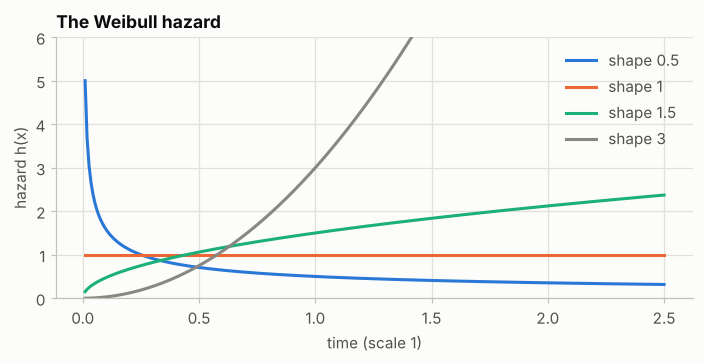

true shape 1.5, true scale 5000
    n  mean shape  sd shape  mean scale  sd scale
   50       1.545     0.166    4999.114   472.274
  100       1.534     0.114    5028.530   341.098
 1000       1.498     0.036    5004.428   106.256
10000       1.501     0.012    5000.410    35.641

mean of the distribution: scale * Gamma(1 + 1/shape) = 4,513.7 (scipy: 4,513.7); median 3,916.1


In [56]:
# EXTRA (e): the hazard of the Weibull distribution, and maximum likelihood estimates of its parameters
x = np.linspace(0.01, 2.5, 300)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for beta, color in zip((0.5, 1, 1.5, 3), PALETTE + [MUTED]):
    ax.plot(x, beta * x ** (beta - 1), color=color, lw=2, label=f"shape {beta}")
ax.set_ylim(0, 6); ax.set_xlabel("time (scale 1)"); ax.set_ylabel("hazard h(x)")
ax.set_title("The Weibull hazard")
ax.legend()
plt.tight_layout()
plt.show()

rng = np.random.default_rng(85)
rows = []
for n in (50, 100, 1000, 10_000):
    fits = np.array([stats.weibull_min.fit(stats.weibull_min.rvs(1.5, scale=5000, size=n, random_state=rng), floc=0)[::2] for _ in range(200)])
    rows.append({"n": n, "mean shape": fits[:, 0].mean(), "sd shape": fits[:, 0].std(ddof=1), "mean scale": fits[:, 1].mean(), "sd scale": fits[:, 1].std(ddof=1)})
print("true shape 1.5, true scale 5000")
print(pd.DataFrame(rows).round(3).to_string(index=False))
from math import gamma
print(f"\nmean of the distribution: scale * Gamma(1 + 1/shape) = {5000 * gamma(1 + 1 / 1.5):,.1f} (scipy: {stats.weibull_min.mean(1.5, scale=5000):,.1f}); median {5000 * np.log(2) ** (1 / 1.5):,.1f}")

**Analysis of extra (e).**

* **The hazard.** For shape 0.5 the hazard falls (infinite at 0): the longer a component has lasted, the less likely it is to fail soon (early failures weed out the weak ones). For shape 1 it is constant (the exponential distribution). For shape 1.5 it rises linearly, and for shape 3 it rises as the square of time: wear-out.
* **Estimation.** The maximum likelihood estimates recover the parameters of the book's distribution (shape 1.5, scale 5,000) with a spread that falls as $1/\sqrt{n}$: for $n = 100$ the shape is estimated as 1.534 with a standard deviation of 0.114 and the scale as 5,029 (341); for 1,000 it is 1.498 (0.036) and 5,004 (106); for 10,000 it is 1.501 (0.012) and 5,000 (36). The shape has a small upward bias for small samples (1.545 for $n = 50$).
* A sample of 100 lifetimes cannot tell a shape of 1.5 from 1.3 or 1.7 (two standard deviations are 0.23), so the question "is the hazard increasing?" can be answered, but the degree of wear-out is imprecise.
* The mean of the distribution, $\eta\,\Gamma(1 + 1/\beta)$, is 4,513.7 (the same value with `scipy`) and the median $\eta (\ln 2)^{1/\beta}$ is 3,916.1; the mean is above the median because the distribution is skewed to the right.

---
## Which distribution, which tool? A decision guide

| Question or data | Tool | `scipy.stats` / `pandas` | Notes from this chapter |
|---|---|---|---|
| How uncertain is a mean? | standard error $s/\sqrt{n}$, a $t$ interval, or the bootstrap | `t.ppf`, `sklearn.utils.resample`, `bootstrap` | the error shrinks as $1/\sqrt{n}$ (3(a)); small skewed samples give intervals that are too narrow (5(a)) |
| How uncertain is a median, a trimmed mean, a ratio? | the bootstrap | `bootstrap`, `resample` | 1,000 resamples are enough for a standard error (4(b)); do not use it for a maximum (4(d)) |
| Is the sample representative? | think about how it was selected, stratify, hold out data | - | a biased sample does not improve with size (1(b)); selected winners regress (2(a), 2(b)) |
| Are the data normal? | a QQ-plot of the standardized values | `probplot` | S shapes are long tails, curves are skew (6(c)); tests alone do not show how (6(c)) |
| Extreme values more frequent than expected | heavy-tailed models such as $t$; do not use the normal model for the tail | `t.fit` | stock changes beyond 4 standard deviations are far more frequent than the normal model says (7(b), 7(d)) |
| A mean standardized with an estimated $s$, small $n$ | Student's $t$ | `t.ppf`, `t.sf` | with $n = 5$ the normal multiplier covers well below 95% (8(c)) |
| Number of successes in $n$ independent trials | binomial | `binom.pmf`, `binom.cdf` | normal approximation if $np$ and $n(1-p)$ are large (9(b)); use Wilson or exact intervals for a proportion (9(c)) |
| Counts of events in an interval | Poisson | `poisson.pmf` | check the index of dispersion; a varying rate gives variance above the mean (12(c)) |
| Time between events, constant rate | exponential | `expon` | memoryless; the estimate $1/\bar x$ is biased up for small $n$ (12(d)) |
| Time to failure, rate that changes | Weibull | `weibull_min` | the shape tells whether the hazard falls, is constant or rises (12(e)) |
| Departure of counts from expected counts | chi-square | `chisquare`, `chi2.sf` | expected counts of 5 or more; very small ones distort the rate of false alarms (10(d)) |
| Variance of a sample | chi-square | `chi2.ppf` | exact only for normal data (10(b)) |
| Ratio of variances, ANOVA | $F$ | `f.sf`, `f_oneway` | the two-variance $F$ test is not robust; prefer Brown-Forsythe (11(c)) |

---
## Chapter summary

Statistics starts from the fact that the data are a **sample**. The first questions are about how it was selected, because a sample that is selected in a way that depends on what is measured is biased, and no amount of data repairs that. If the sample is random, every statistic computed from it has a **sampling distribution**, whose spread is the **standard error**; for a mean it shrinks as $1/\sqrt{n}$, and for a large enough sample the distribution is close to normal whatever the data look like (the central limit theorem). The standard error and the **confidence interval** can be found by a formula when one exists, and by the **bootstrap**, which resamples the data, when it does not; both have limits that the experiments of this notebook make visible (small, skewed samples; extremes). The rest of the chapter is a small library of distributions: the **normal** and its **long-tailed** alternatives, read through QQ-plots; Student's **$t$** for means with an estimated scale; the **binomial** for counts of successes; the **chi-square** and **$F$** distributions for variances, counts and ANOVA; and the **Poisson**, **exponential** and **Weibull** family for events and lifetimes.

### Key takeaways

1. **Size does not repair quality.** A sample whose chance of inclusion rises with the income has an error of 14,600 to 15,700 dollars (21% to 23% of the mean) for every size from 50 to 5,000, while the error of a random sample falls as $1/\sqrt{n}$ (1(b)).
2. **Selection can manufacture findings.** The best of 1,000 useless predictors has a correlation of about 0.52 with the outcome (0.13 on new data); extreme players regress to the mean by the factor $1 - $ reliability (2(a), 2(b)).
3. **The standard error shrinks as $1/\sqrt{n}$:** four times the data for half the error (3(a)). The distribution of a mean is nearly normal for $n$ of a few dozen, but the speed depends on the skewness of the data (3(b)).
4. **Every statistic has its own sampling distribution.** The mean, the median and the maximum of the same samples have very different spreads and shapes (3(d)).
5. **The bootstrap needs about 1,000 resamples for a standard error,** estimates the sampling distribution of the sample, not of the population, and fails for a maximum (4(b), 4(c), 4(d)).
6. **A "90% interval" describes the procedure.** For a skewed population and 20 values the percentile bootstrap interval covers 86% of the time and the $t$ interval 88% (5(a), 5(c)).
7. **Use a QQ-plot to see how data differ from normal,** not only whether (6(c)). The book's NFLX series is not a series of returns, because the column holds price changes (7(a)).
8. **Tails are heavier than normal in real data.** Across 511 stocks, days beyond four standard deviations are on average 47 times as frequent as a normal model says, and the mean of Cauchy data never converges (7(b), 7(c), 7(d)).
9. **Estimating the scale matters in small samples:** with $n = 5$ a 95% interval with the normal multiplier covers only about 88% of the time, while the $t$ interval is exact for normal data (8(c)); tests on variances (chi-square, $F$) are far less forgiving of non-normal data than tests on means (10(b), 11(c)).
10. **The distributions of events are one family.** Exponential gaps give Poisson counts, a varying rate makes counts overdispersed, and the Weibull shape says whether the hazard falls, stays constant or rises (12(b), 12(c), 12(e)).

### Book vs. library notes

The official code of the chapter ran in this notebook with the versions printed by the setup cell and without changes, apart from the data path and the seeds (below). Everything else, in particular what the plots look like, may differ in other versions of the libraries.

* **Paths.** The official script reads its data from a folder next to the code. Here `DATA` comes from the setup cell, which also downloads the files from the official repository if they are missing.
* **Seeds.** The official script sets a seed only for the first figure and for the confidence-interval cells. All other cells that draw random numbers (the sampling distribution, the bootstrap, the QQ-plot, the three samples at the end) start here with `np.random.seed(...)  # NOT IN THE BOOK`. The three samples of section 12 use different seeds (2024, 2025, 2026): with the same seed the three functions use the same uniform random numbers, and a chance extreme value would appear in the exponential and in the Weibull sample alike.
* **A method that is only referred to.** The line `ax.set_position` of the figure code is the name of a method, not a call, so it has no effect.
* **The confidence-interval figures.** The second CI cell creates two histograms of the same data and does not call `plt.show()`; the notebook displays one figure with both intervals (the second histogram covers the first), and prints the value of the last statement, `Text(0, 0.5, 'Counts')`.
* **The column NFLX.** The file `sp500_data.csv.gz` holds daily price changes, not prices. The script's `np.diff(np.log(nflx[nflx>0]))` then takes the logarithm of positive changes and differences them; extra 7(a) shows what that produces. It is a property of the code of the script and of this data file, and it is not corrected here, because the cell reproduces the script.
* **Plot style.** The setup cell sets the `Matplotlib` style globally, so the figures of the book code also have this notebook's style, not the default one.
* **Library calls.** `pd.read_csv(...).squeeze('columns')`, `sklearn.utils.resample`, `scipy.stats.probplot(..., fit=False)` and the `weibull_min` distribution work as in the script; extras use `scipy.stats.bootstrap` and `scipy.stats.binomtest(...).proportion_ci`, which the script does not.
* **License.** The code and the data of the official repository are under the GNU General Public License v3. This repository does not redistribute the data: the notebook downloads it at run time, and the `data` folder is ignored by git.

---
## References

**The book and its code**

* Bruce, P., Bruce, A. and Gedeck, P. (2020). *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, 2nd edition. O'Reilly Media.
* Official code and data of the book: `gedeck/practical-statistics-for-data-scientists` on GitHub (GNU General Public License v3).

**Cited in the text**

* Berkson, J. (1946). Limitations of the application of fourfold table analysis to hospital data. *Biometrics Bulletin*, 2(3), 47-53.
* Box, G. E. P. (1953). Non-normality and tests on variances. *Biometrika*, 40(3/4), 318-335.
* Brown, L. D., Cai, T. T. and DasGupta, A. (2001). Interval estimation for a binomial proportion. *Statistical Science*, 16(2), 101-133.
* Brown, M. B. and Forsythe, A. B. (1974). Robust tests for the equality of variances. *Journal of the American Statistical Association*, 69(346), 364-367.
* Clopper, C. J. and Pearson, E. S. (1934). The use of confidence or fiducial limits illustrated in the case of the binomial. *Biometrika*, 26(4), 404-413.
* Efron, B. (1979). Bootstrap methods: another look at the jackknife. *The Annals of Statistics*, 7(1), 1-26.
* Efron, B. (1987). Better bootstrap confidence intervals. *Journal of the American Statistical Association*, 82(397), 171-185.
* Filliben, J. J. (1975). The probability plot correlation coefficient test for normality. *Technometrics*, 17(1), 111-117.
* Galton, F. (1886). Regression towards mediocrity in hereditary stature. *The Journal of the Anthropological Institute of Great Britain and Ireland*, 15, 246-263.
* Levene, H. (1960). Robust tests for equality of variances. In I. Olkin et al. (eds.), *Contributions to Probability and Statistics: Essays in Honor of Harold Hotelling*, 278-292. Stanford University Press.
* Meng, X.-L. (2018). Statistical paradises and paradoxes in big data (I): law of large populations, big data paradox, and the 2016 US presidential election. *The Annals of Applied Statistics*, 12(2), 685-726.
* Pearson, K. (1900). On the criterion that a given system of deviations from the probable in the case of a correlated system of variables is such that it can be reasonably supposed to have arisen from random sampling. *The London, Edinburgh, and Dublin Philosophical Magazine and Journal of Science* (series 5), 50(302), 157-175.
* Shapiro, S. S. and Wilk, M. B. (1965). An analysis of variance test for normality (complete samples). *Biometrika*, 52(3/4), 591-611.
* Squire, P. (1988). Why the 1936 Literary Digest poll failed. *Public Opinion Quarterly*, 52(1), 125-133.
* Student (W. S. Gosset) (1908). The probable error of a mean. *Biometrika*, 6(1), 1-25.
* Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association*, 22(158), 209-212.

**Libraries**

* The versions of `NumPy`, `pandas`, `SciPy`, `scikit-learn`, `seaborn` and `Matplotlib` are printed by the setup cell.